In [1]:
import os

for folder in ["/kaggle/working", "/kaggle/input"]:
    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.endswith((".parquet", ".csv")):
                print(os.path.join(root, file))

/kaggle/working/deletion_summary.csv
/kaggle/working/faithfulness_with_ci.csv
/kaggle/working/gru_deletion_results.csv
/kaggle/working/agreement_summary.csv
/kaggle/working/deletion_results.csv
/kaggle/working/gru_lime_agreement_summary.csv
/kaggle/working/gru_faithfulness_summary.csv
/kaggle/working/gru_paired_bootstrap.csv
/kaggle/working/agreement_200.csv
/kaggle/working/gru_predictions.csv
/kaggle/working/gru_r2_agreement.csv
/kaggle/working/model_comparison.csv
/kaggle/working/gru_training_history.csv
/kaggle/working/gru_lime_agreement_200.csv
/kaggle/input/datasets/narasimha2003/fml-sst2/test-00000-of-00001.parquet
/kaggle/input/datasets/narasimha2003/fml-sst2/train-00000-of-00001.parquet
/kaggle/input/datasets/narasimha2003/fml-sst2/validation-00000-of-00001.parquet


In [2]:
import pandas as pd

data_path = "/kaggle/input/datasets/narasimha2003/fml-sst2/"

train_df = pd.read_parquet(data_path + "train-00000-of-00001.parquet")
val_df = pd.read_parquet(data_path + "validation-00000-of-00001.parquet")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
display(train_df.head())

Train: (67349, 3)
Validation: (872, 3)


,sentence,label,idx
0,hide new secretions from the parental units,0,0
1,"contains no wit , only labored gags",0,1
2,that loves its characters and communicates som...,1,2
3,remains utterly satisfied to remain the same t...,0,3
4,on the worst revenge-of-the-nerds clichés the ...,0,4


## 1.2 Exploratory Data Analysis (EDA)

Before training the classification models, we analyze the characteristics of the SST-2 dataset.

The objective of Exploratory Data Analysis is to understand the distribution of sentiment labels and the lengths of movie-review sentences.

### 1.2.1 Class Distribution

SST-2 contains two sentiment classes:

- 0: Negative sentiment
- 1: Positive sentiment

The training dataset contains 67,349 sentences, while the validation dataset contains 872 sentences.

Examining the label distribution helps identify class imbalance, which may affect classification performance.

### 1.2.2 Sentence Length Analysis

Sentence length is an important characteristic of text datasets.

We calculate:

1. Minimum sentence length.
2. Maximum sentence length.
3. Average (mean) sentence length.
4. Median sentence length.
5. Standard deviation.
6. 95th percentile of sentence length.

Sentence length is measured by counting whitespace-separated words.

### Why analyze sentence lengths?

- To understand whether the dataset contains mostly short or long sentences.
- To identify unusually long sentences.
- To guide padding and truncation choices for neural networks such as GRU and BERT.
- To understand the computational requirements of the classification models.

### Justification

Analyzing sentence lengths and label distributions helps us make informed preprocessing and modeling decisions rather than selecting parameters arbitrarily.

In [3]:
# Calculate sentence lengths in words
train_df["sentence_length"] = (
    train_df["sentence"].str.split().str.len()
)

val_df["sentence_length"] = (
    val_df["sentence"].str.split().str.len()
)

# Calculate statistics
length_stats = pd.DataFrame({
    "Train": [
        train_df["sentence_length"].min(),
        train_df["sentence_length"].max(),
        train_df["sentence_length"].mean(),
        train_df["sentence_length"].median(),
        train_df["sentence_length"].std(),
        train_df["sentence_length"].quantile(0.95)
    ],
    "Validation": [
        val_df["sentence_length"].min(),
        val_df["sentence_length"].max(),
        val_df["sentence_length"].mean(),
        val_df["sentence_length"].median(),
        val_df["sentence_length"].std(),
        val_df["sentence_length"].quantile(0.95)
    ]
}, index=[
    "Minimum",
    "Maximum",
    "Mean",
    "Median",
    "Standard Deviation",
    "95th Percentile"
])

display(length_stats.round(2))

,Train,Validation
Minimum,1.00,2.00
Maximum,52.00,47.00
Mean,9.41,19.55
Median,7.00,19.00
Standard Deviation,8.07,8.76
95th Percentile,26.00,34.45


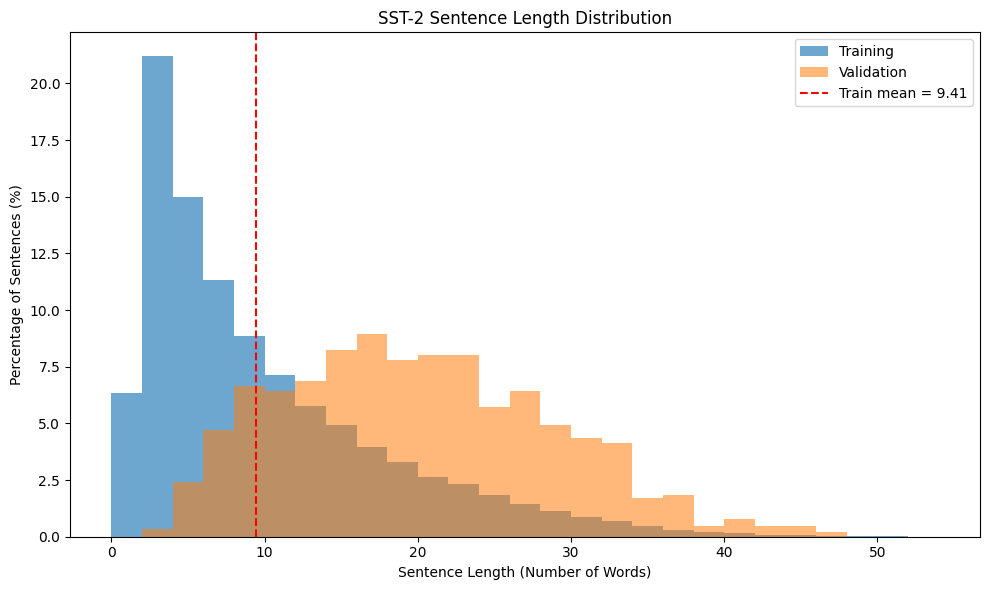

In [4]:
import matplotlib.pyplot as plt
import numpy as np

train_lengths = train_df["sentence_length"]
val_lengths = val_df["sentence_length"]

max_length = max(train_lengths.max(), val_lengths.max())
bins = np.arange(0, max_length + 3, 2)

plt.figure(figsize=(10, 6))

plt.hist(
    train_lengths,
    bins=bins,
    weights=np.ones(len(train_lengths)) * 100 / len(train_lengths),
    alpha=0.65,
    label="Training"
)

plt.hist(
    val_lengths,
    bins=bins,
    weights=np.ones(len(val_lengths)) * 100 / len(val_lengths),
    alpha=0.55,
    label="Validation"
)

plt.axvline(
    train_lengths.mean(),
    color="red",
    linestyle="--",
    label=f"Train mean = {train_lengths.mean():.2f}"
)

plt.xlabel("Sentence Length (Number of Words)")
plt.ylabel("Percentage of Sentences (%)")
plt.title("SST-2 Sentence Length Distribution")

plt.legend()
plt.tight_layout()

plt.savefig(
    "/kaggle/working/sst2_sentence_lengths.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_245/4146288782.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Negative (0)", "Positive (1)"])


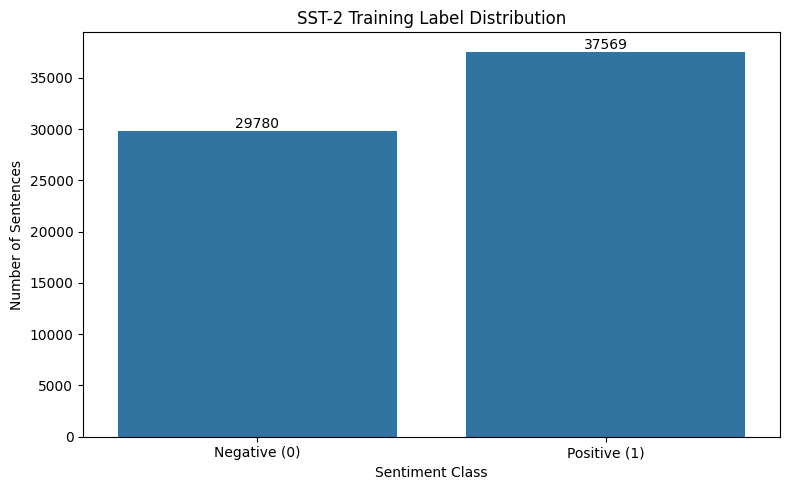

In [5]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="label",
    order=[0, 1],
    ax=ax
)

ax.set_title("SST-2 Training Label Distribution")
ax.set_xlabel("Sentiment Class")
ax.set_ylabel("Number of Sentences")
ax.set_xticklabels(["Negative (0)", "Positive (1)"])

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/sst2_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 1.2 Text Preprocessing

Text preprocessing converts raw sentences into a consistent format so that machine learning models can process them effectively.

For the SST-2 sentiment classification dataset, we use the following preprocessing steps:

1. **Tokenization:** Splitting sentences into individual words.
2. **Lowercasing:** Converting words to lowercase to avoid treating "Good" and "good" as different features.
3. **Punctuation handling:** Ignoring most punctuation when extracting TF-IDF features.
4. **Whitespace normalization:** Removing unnecessary spaces.
5. **Stopword handling:** Retaining stopwords, especially negation words such as "not", "no", and "never".

### Why these steps?

**Example:**

Original sentence: "The Movie was NOT Good!"

After lowercasing and tokenization: `["the", "movie", "was", "not", "good"]`

- Lowercasing reduces the vocabulary size.
- Tokenization allows us to represent sentences using word features.
- Ignoring punctuation simplifies the traditional ML baseline.
- Retaining negation words preserves important sentiment information.

### Justification

For sentiment analysis, removing all stopwords can be harmful because words like "not" can completely change a sentence's meaning.

For example:

- "The movie is good" → Positive sentiment
- "The movie is not good" → Negative sentiment

Therefore, we retain stopwords instead of removing them.

We use scikit-learn's `TfidfVectorizer` for lowercasing, tokenization, and punctuation handling in the next section. This avoids unnecessary preprocessing and keeps the pipeline reproducible.

**Note:** Punctuation such as "!" can carry sentiment information. Our initial TF-IDF baseline ignores it, which is a limitation we will acknowledge.

In [6]:
# Normalize unnecessary whitespace
import re

def preprocess_text(text):
    text = str(text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# Apply preprocessing
train_df["clean_sentence"] = train_df["sentence"].apply(preprocess_text)
val_df["clean_sentence"] = val_df["sentence"].apply(preprocess_text)

# Compare original and processed sentences
print("Original:")
print(train_df["sentence"].iloc[0])

print("\nProcessed:")
print(train_df["clean_sentence"].iloc[0])

Original:
hide new secretions from the parental units 

Processed:
hide new secretions from the parental units


## 1.3 Preparing Training and Validation Data

Before training machine learning models, we need to separate the input features and target labels.

The SST-2 dataset provides two labelled splits:

| Dataset | Number of examples | Purpose |
|---|---:|---|
| Training | 67,349 | Used to train the model |
| Validation | 872 | Used to evaluate model performance |

### Input Features (X)

The input consists of movie-review sentences.

Example: `"the movie was excellent"`

### Target Labels (y)

The target represents the sentiment of the sentence:

- **0:** Negative sentiment
- **1:** Positive sentiment

### Why use separate training and validation sets?

- **Training data:** The model learns patterns that distinguish positive and negative sentences.
- **Validation data:** Evaluates how well the trained model performs on unseen sentences.
- **Data leakage prevention:** We must not use validation data to fit the TF-IDF vocabulary or train the classifier.

### Justification

We use the official SST-2 training and validation splits rather than creating another random split.

This makes our results reproducible and allows us to compare different classification models using the same evaluation dataset.

All classifiers will be evaluated on the full validation set. Later, explanation methods such as LIME, SHAP and attention will be compared using the same fixed subset of validation sentences.

In [7]:
# Separate inputs and target labels

X_train = train_df["clean_sentence"]
y_train = train_df["label"]

X_val = val_df["clean_sentence"]
y_val = val_df["label"]

# Check dataset sizes
print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))

# Check label distribution
print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nValidation label distribution:")
print(y_val.value_counts())

# Check for missing values
print("\nMissing training values:", X_train.isna().sum())
print("Missing validation values:", X_val.isna().sum())

Training examples: 67349
Validation examples: 872

Training label distribution:
label
1    37569
0    29780
Name: count, dtype: int64

Validation label distribution:
label
1    444
0    428
Name: count, dtype: int64

Missing training values: 0
Missing validation values: 0


## 1.4 TF-IDF Vectorization

Machine learning models such as Logistic Regression cannot directly process text. Therefore, we need to convert sentences into numerical feature vectors.

We use **TF-IDF (Term Frequency–Inverse Document Frequency)** to represent the importance of each word in a sentence.

### What is TF-IDF?

TF-IDF assigns higher weights to words that occur frequently in a particular document but are relatively uncommon across the training corpus.

It combines two components:

**1. Term Frequency (TF)**

Measures how frequently a word appears in a document.

For example, if the word "excellent" appears multiple times in a review, it has a higher term frequency.

**2. Inverse Document Frequency (IDF)**

Measures how rare a word is across the documents.

- Common words like "the" and "is" receive lower IDF values.
- Less common words like "excellent" or "disappointing" may receive higher IDF values.


### TF-IDF Formula

The TF-IDF weight of a term \(t\) in document \(d\) is:

$$
\boxed{\mathrm{TF\text{-}IDF}(t,d)=\mathrm{TF}(t,d)\times\mathrm{IDF}(t)}
$$

**Inverse Document Frequency (IDF):**

In scikit-learn, the smoothed IDF is calculated as:

$$
\boxed{\mathrm{IDF}(t)=\log\left(\frac{N+1}{df(t)+1}\right)+1}
$$

**Where:**

- \(t\): A word (term).
- \(d\): A document (sentence).
- \(N\): Total number of training documents.
- \(df(t)\): Number of documents containing term \(t\).

**Normalization:**

By default, `TfidfVectorizer` applies L2 normalization:

$$
\boxed{x_{\mathrm{normalized}}=\frac{x}{\|x\|_2}}
$$

### Example

Consider two sentences:

- "The movie was excellent"
- "The movie was terrible"

Words like "the", "movie", and "was" occur in both sentences, so they are less useful for distinguishing sentiment.

Words such as "excellent" and "terrible" help the classifier distinguish positive and negative reviews.

### Why use TF-IDF?

1. Converts text into numerical vectors.
2. Reduces the influence of very common words.
3. Creates a sparse representation suitable for traditional ML classifiers.
4. Works efficiently with Logistic Regression.
5. Allows us to examine word-level model contributions for explainability.

### Parameters

We use:

- `max_features=10000`: Retain at most 10,000 vocabulary features.
- `ngram_range=(1,1)`: Use individual words (unigrams).
- `min_df=2`: Ignore words appearing in fewer than two training documents.
- `stop_words=None`: Retain stopwords, including important negations.
- `lowercase=True`: Convert text to lowercase during vectorization.

### Justification

We choose unigram TF-IDF as our initial baseline because it is computationally efficient and supports straightforward word-level interpretability.

We fit TF-IDF only on the training dataset and apply the same vocabulary and IDF weights to the validation dataset. This prevents data leakage.

**Limitation:** Unigram TF-IDF does not capture word order or contextual meaning. For example, "good" and "not good" share the feature "good". We will investigate more context-aware neural models in later experiments.


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 1),
    min_df=2,
    stop_words=None,
    lowercase=True
)

# Learn vocabulary and IDF from training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation data using same vectorizer
X_val_tfidf = tfidf.transform(X_val)

print("TF-IDF Vectorization Completed!")

print("Training shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)

print("Vocabulary size:", len(tfidf.vocabulary_))

TF-IDF Vectorization Completed!
Training shape: (67349, 10000)
Validation shape: (872, 10000)
Vocabulary size: 10000


In [9]:
# Get vocabulary words
feature_names = tfidf.get_feature_names_out()

# Examine first training sentence
sample = X_train.iloc[0]

# TF-IDF representation
sample_vector = X_train_tfidf[0]

print("Original sentence:")
print(sample)

print("\nWord TF-IDF scores:")

for idx, value in zip(
    sample_vector.indices,
    sample_vector.data
):
    print(f"{feature_names[idx]}: {value:.4f}")

Original sentence:
hide new secretions from the parental units

Word TF-IDF scores:
hide: 0.5046
new: 0.2993
from: 0.2477
the: 0.1186
parental: 0.5319
units: 0.5454


## 1.5 Logistic Regression Model Training

After converting the SST-2 sentences into TF-IDF feature vectors, we train a Logistic Regression classifier to predict sentiment.

### What is Logistic Regression?

Logistic Regression is a supervised machine learning algorithm used for classification.

In our project, it performs binary sentiment classification:

- **0:** Negative sentiment
- **1:** Positive sentiment


### Mathematical Formulation

For a sentence represented by the TF-IDF feature vector $\mathbf{x}$, Logistic Regression first calculates a linear score:

$$
\boxed{z = \mathbf{w}^{T}\mathbf{x} + b}
$$

Where:

- $\mathbf{x}$: TF-IDF feature vector.
- $\mathbf{w}$: Learned model weights.
- $b$: Bias term.
- $z$: Linear score (logit).

**Sigmoid Function:**

The sigmoid function converts the linear score into a probability between 0 and 1.

$$
\boxed{P(y=1\mid\mathbf{x})=\sigma(z)=\frac{1}{1+e^{-z}}}
$$

**Prediction Rule:**

The predicted sentiment class is determined using a threshold of 0.5.

$$
\boxed{
\hat{y}=
\begin{cases}
1, & P(y=1\mid\mathbf{x})\geq 0.5\\
0, & P(y=1\mid\mathbf{x})<0.5
\end{cases}
}
$$

Where:

- $\hat{y}=1$: Positive sentiment.
- $\hat{y}=0$: Negative sentiment.

### How Does the Model Learn?

Logistic Regression learns its parameters by minimizing Binary Cross-Entropy (BCE) loss with regularization.

**Binary Cross-Entropy Loss:**

$$
\boxed{
L_{\mathrm{BCE}}=-\frac{1}{N}\sum_{i=1}^{N}
\left[
y_i\log(p_i)+(1-y_i)\log(1-p_i)
\right]
}
$$

Where:

- $N$: Number of training examples.
- $y_i$: Actual sentiment label (0 or 1).
- $p_i$: Predicted probability of positive sentiment.

**L2-Regularized Loss:**

$$
\boxed{
L_{\mathrm{total}}=L_{\mathrm{BCE}}+
\frac{\lambda}{2}\|\mathbf{w}\|_2^2
}
$$

Here, $\lambda$ represents the regularization strength. The exact scaling of the penalty depends on the implementation.

Regularization discourages excessively large weights and helps reduce overfitting.

### Why Use Logistic Regression?

1. **Simple Baseline:** Provides a reference for evaluating more complex neural models.
2. **Efficient Training:** Works well with high-dimensional, sparse TF-IDF features.
3. **Interpretability:** Learned coefficients help identify how words influence sentiment predictions.
4. **Explainability Comparison:** Allows us to compare model-based feature contributions with LIME and SHAP.
5. **Reproducibility:** Easy to train, evaluate, and reproduce results on SST-2.

### Justification

Logistic Regression is selected as our traditional machine learning baseline because it is efficient, interpretable, and suitable for TF-IDF text representations.

We train the classifier using 67,349 SST-2 training examples and evaluate it on all 872 validation examples.

Its learned feature contributions will be compared against LIME and SHAP to study explanation agreement and faithfulness.


In [10]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver="lbfgs",
    random_state=42
)

# Train using TF-IDF features
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression Training Completed!")

print("Number of features:", lr_model.n_features_in_)
print("Classes:", lr_model.classes_)
print("Iterations used:", lr_model.n_iter_)

Logistic Regression Training Completed!
Number of features: 10000
Classes: [0 1]
Iterations used: [69]



## 1.6 Model Evaluation

After training Logistic Regression, we evaluate its performance on the official SST-2 validation dataset containing 872 sentences.

### Evaluation Metrics

We use the following metrics:

1. **Accuracy:** Proportion of correctly classified sentences.
2. **Precision:** Proportion of predicted positive examples that are actually positive.
3. **Recall:** Proportion of actual positive examples correctly identified.
4. **Macro F1-score:** Harmonic mean of precision and recall, calculated separately for each class and averaged equally.
5. **ROC-AUC:** Measures how effectively the model ranks positive examples above negative examples.
6. **Confusion Matrix:** Shows correct and incorrect predictions for both sentiment classes.

### Why use multiple metrics?

Accuracy alone does not provide a complete picture, particularly when the dataset contains unequal numbers of positive and negative examples.

Macro F1 gives equal importance to both classes, while the confusion matrix helps us understand which sentiment class the model misclassifies more frequently.

### Justification

We evaluate every classifier on the same 872 validation examples to ensure a consistent model-performance comparison.

All main classification metrics will be reported on a 0–1 scale with four decimal places, and confusion matrix entries will be shown as counts.


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

# Predict using Logistic Regression
y_pred_lr = lr_model.predict(X_val_tfidf)

# Positive-class probabilities
y_prob_lr = lr_model.predict_proba(X_val_tfidf)[:, 1]

# Calculate metrics
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_pred_lr),
    "Precision (Macro)": precision_score(
        y_val, y_pred_lr, average="macro"
    ),
    "Recall (Macro)": recall_score(
        y_val, y_pred_lr, average="macro"
    ),
    "F1 (Macro)": f1_score(
        y_val, y_pred_lr, average="macro"
    ),
    "ROC-AUC": roc_auc_score(y_val, y_prob_lr)
}

# Display results
results_df = pd.DataFrame([lr_results])

display(results_df.round(4))

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_val,
        y_pred_lr,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),ROC-AUC
0,Logistic Regression,0.8154,0.8178,0.8145,0.8147,0.9025



Detailed Classification Report:
              precision    recall  f1-score   support

    Negative     0.8414    0.7687    0.8034       428
    Positive     0.7942    0.8604    0.8259       444

    accuracy                         0.8154       872
   macro avg     0.8178    0.8145    0.8147       872
weighted avg     0.8174    0.8154    0.8149       872



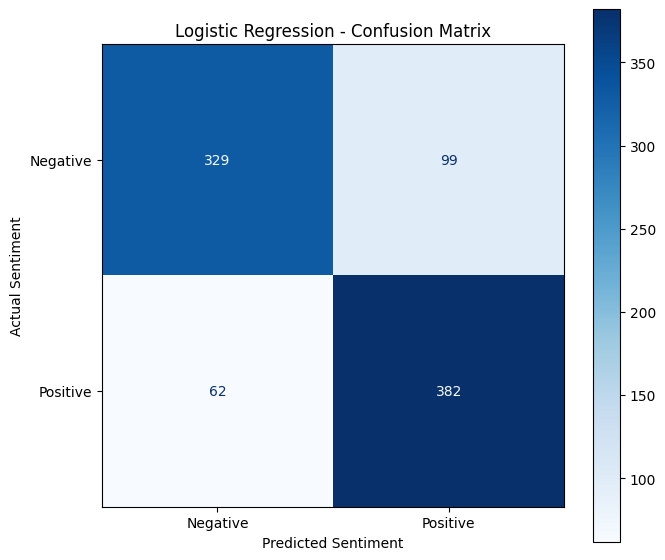

In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_pred_lr, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/lr_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


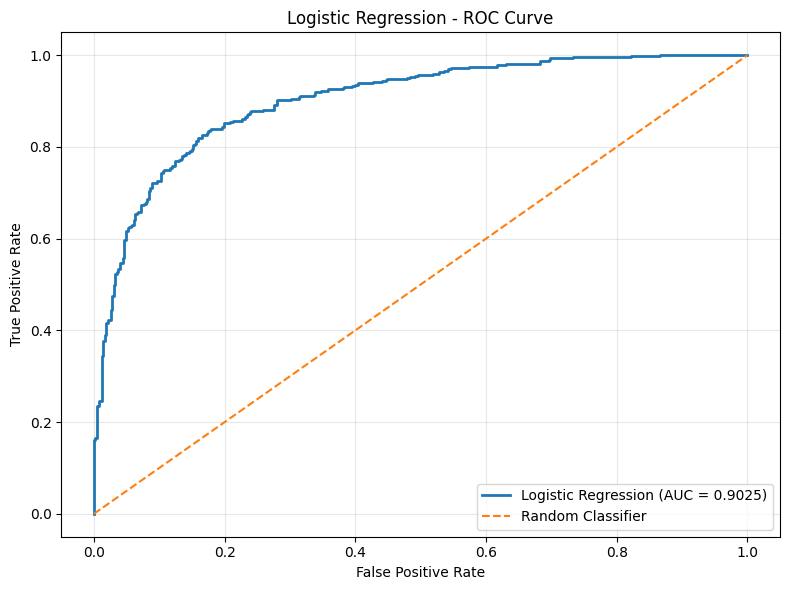

In [13]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_val, y_prob_lr)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - ROC Curve")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/lr_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 1.7 Model-Based Feature Importance

Logistic Regression is an interpretable linear classifier because it assigns a learned coefficient to each TF-IDF feature.

### How do coefficients explain predictions?

For an input sentence, the model computes:

$$
z = \sum_{j=1}^{d} w_j x_j+b
$$

Where:

- $w_j$: Learned coefficient of feature $j$.
- $x_j$: TF-IDF value of feature $j$.
- $b$: Bias term.
- $d$: Number of features.

### Interpretation

- **Positive coefficient:** Associated with positive sentiment.
- **Negative coefficient:** Associated with negative sentiment.
- **Larger absolute coefficient:** Stronger influence on the logit for the same TF-IDF feature value.

### Global vs Local Explanations

**Global importance:** The learned coefficients indicate which words are generally associated with positive or negative sentiment.

**Local importance:** For an individual sentence, we calculate the contribution of each word as:

$$
\text{Contribution}_j = w_j x_j
$$

This measures how much each feature contributes to the sentence's classification score.

### Why analyze model coefficients?

1. Provides an interpretable baseline for understanding Logistic Regression.
2. Identifies words associated with positive and negative predictions.
3. Allows comparison with LIME and SHAP explanations.
4. Helps investigate whether different explanation methods rank words similarly.

### Justification

We use model coefficients and local feature contributions as our first explanation method because they are directly derived from the trained Logistic Regression classifier.

Unlike model-agnostic explanation methods, these contributions are computed from the actual model parameters.


In [14]:
# Extract feature names and learned coefficients
feature_names = tfidf.get_feature_names_out()
coefficients = lr_model.coef_[0]

# Number of words to display
top_n = 15

# Top positive coefficients
positive_idx = np.argsort(coefficients)[-top_n:][::-1]

# Top negative coefficients
negative_idx = np.argsort(coefficients)[:top_n]

positive_words = pd.DataFrame({
    "Word": feature_names[positive_idx],
    "Coefficient": coefficients[positive_idx]
})

negative_words = pd.DataFrame({
    "Word": feature_names[negative_idx],
    "Coefficient": coefficients[negative_idx]
})

print("Top 15 Positive Sentiment Words:")
display(positive_words)

print("\nTop 15 Negative Sentiment Words:")
display(negative_words)

Top 15 Positive Sentiment Words:


,Word,Coefficient
0,best,5.116724
1,powerful,4.834422
2,good,4.619403
3,remarkable,4.561526
4,beautiful,4.521383
5,hilarious,4.512664
6,enjoyable,4.484963
7,fascinating,4.447105
8,heart,4.312274
9,wonderful,4.278918



Top 15 Negative Sentiment Words:


,Word,Coefficient
0,worst,-6.247672
1,lacks,-5.742708
2,bad,-5.525553
3,lacking,-5.201397
4,too,-5.173323
5,no,-4.774189
6,not,-4.725192
7,less,-4.701615
8,none,-4.685662
9,lack,-4.569723


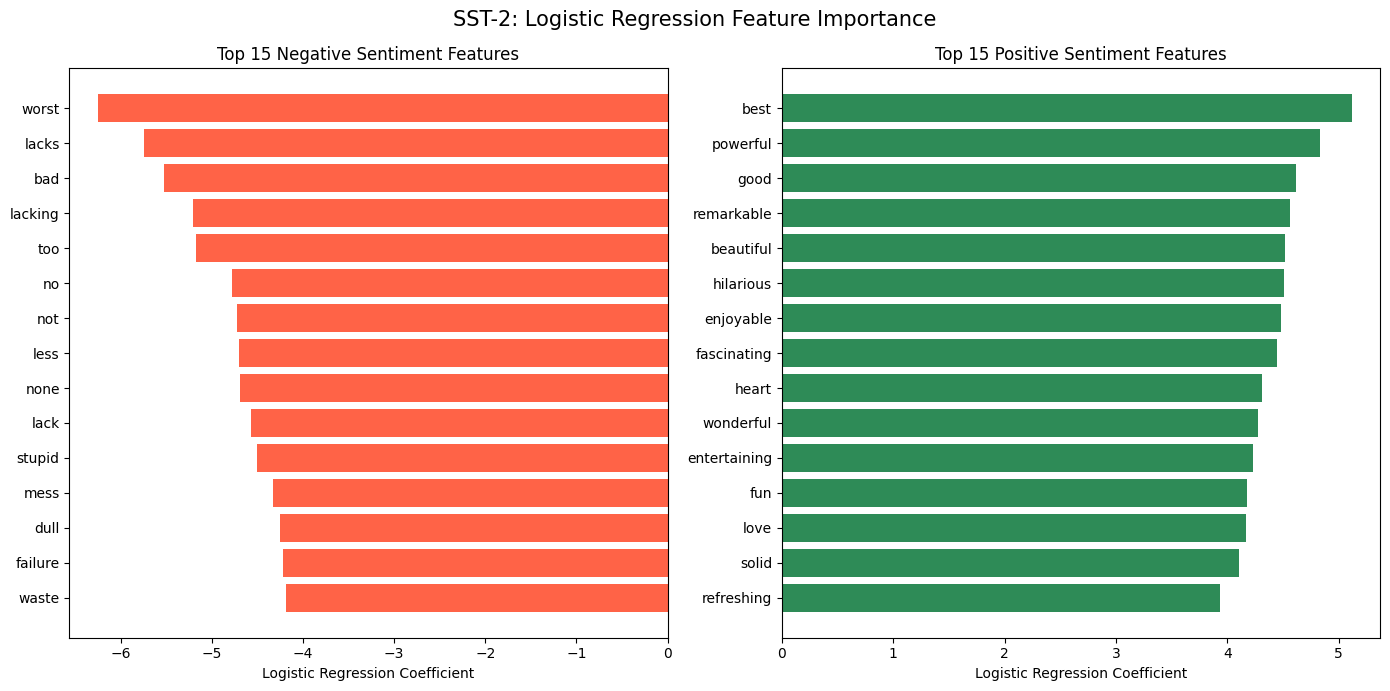

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Negative sentiment words
axes[0].barh(
    negative_words["Word"],
    negative_words["Coefficient"],
    color="tomato"
)

axes[0].set_title("Top 15 Negative Sentiment Features")
axes[0].set_xlabel("Logistic Regression Coefficient")
axes[0].invert_yaxis()

# Positive sentiment words
axes[1].barh(
    positive_words["Word"],
    positive_words["Coefficient"],
    color="seagreen"
)

axes[1].set_title("Top 15 Positive Sentiment Features")
axes[1].set_xlabel("Logistic Regression Coefficient")
axes[1].invert_yaxis()

plt.suptitle(
    "SST-2: Logistic Regression Feature Importance",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/lr_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 1.8 Local Model-Based Explanations

Global feature importance identifies words that are generally associated with positive or negative sentiment.

However, our project focuses on explaining **individual model predictions**.

### What is a Local Explanation?

A local explanation identifies which words influence the prediction of a particular sentence.

For Logistic Regression, the contribution of feature $j$ is:

$$
\boxed{c_j = w_j x_j}
$$

Where:

- $w_j$: Learned Logistic Regression coefficient.
- $x_j$: TF-IDF value of the word.
- $c_j$: Contribution of the word to the prediction score.

The model's decision score is:

$$
\boxed{z = \sum_{j=1}^{d} c_j + b}
$$

### Interpretation

- **Positive contribution:** Pushes the prediction toward positive sentiment.
- **Negative contribution:** Pushes the prediction toward negative sentiment.
- **Larger absolute contribution:** Greater influence on the model's logit.

### Why Are Local Explanations Important?

Our research investigates whether different explanation methods identify the same important words.

Therefore, we need word-level explanations for each individual prediction.

We will compare:

1. Logistic Regression feature contributions.
2. LIME explanations.
3. SHAP explanations.

### Justification

Model-based local contributions provide a direct and interpretable reference because they are calculated using the classifier's actual learned coefficients and TF-IDF features.

These scores will serve as the baseline for measuring explanation agreement using Top-k overlap and Spearman rank correlation.


In [16]:
# Select one validation sentence
sample_idx = 0

sentence = X_val.iloc[sample_idx]

# Transform sentence using the existing TF-IDF vectorizer
sample_tfidf = tfidf.transform([sentence])

# Predict sentiment
prediction = lr_model.predict(sample_tfidf)[0]
probabilities = lr_model.predict_proba(sample_tfidf)[0]

# Extract nonzero features
feature_indices = sample_tfidf.indices
tfidf_values = sample_tfidf.data

# Calculate local contributions: weight * TF-IDF
local_contributions = (
    coefficients[feature_indices] * tfidf_values
)

# Create a DataFrame
local_df = pd.DataFrame({
    "Word": feature_names[feature_indices],
    "TF-IDF": tfidf_values,
    "Coefficient": coefficients[feature_indices],
    "Contribution": local_contributions
})

# Sort by absolute contribution
local_df["Absolute Contribution"] = (
    local_df["Contribution"].abs()
)

local_df = local_df.sort_values(
    "Absolute Contribution",
    ascending=False
)

print("Sentence:", sentence)
print("Actual Label:", y_val.iloc[sample_idx])
print(
    "Predicted Sentiment:",
    "Positive" if prediction == 1 else "Negative"
)
print("Probability (Negative):", round(probabilities[0], 4))
print("Probability (Positive):", round(probabilities[1], 4))

display(local_df.round(4))

Sentence: it 's a charming and often affecting journey .
Actual Label: 1
Predicted Sentiment: Positive
Probability (Negative): 0.0127
Probability (Positive): 0.9873


,Word,TF-IDF,Coefficient,Contribution,Absolute Contribution
2,charming,0.4508,3.9207,1.7674,1.7674
0,affecting,0.5548,1.8964,1.0522,1.0522
5,often,0.4033,1.4295,0.5766,0.5766
4,journey,0.4997,1.0266,0.5130,0.5130
1,and,0.1578,1.1089,0.1750,0.1750
3,it,0.2273,0.1146,0.0260,0.0260


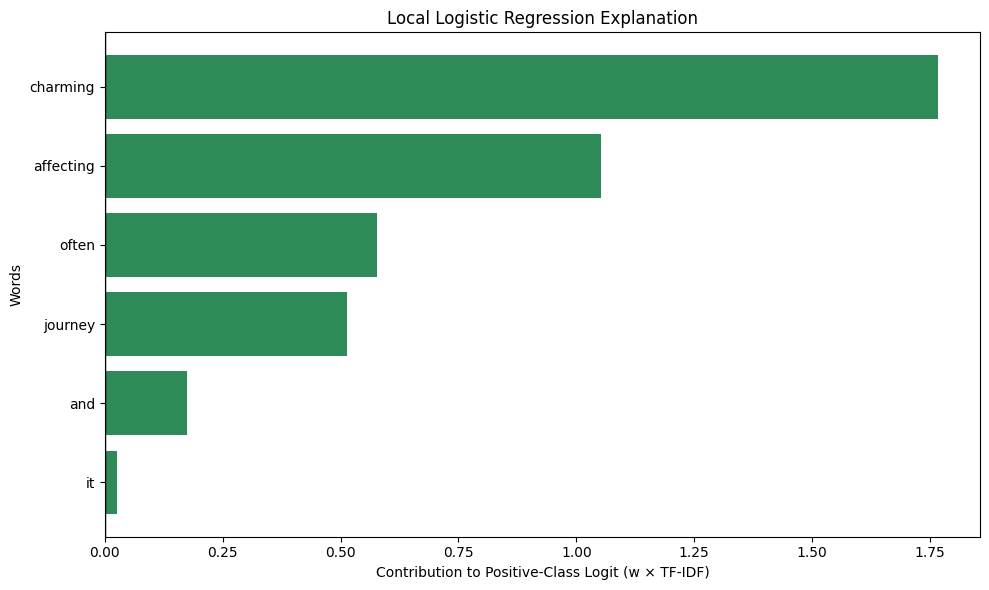

In [17]:
# Plot contribution of each word in the selected sentence

plot_df = local_df.sort_values("Contribution")

colors = [
    "seagreen" if x > 0 else "tomato"
    for x in plot_df["Contribution"]
]

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Word"],
    plot_df["Contribution"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Contribution to Positive-Class Logit (w × TF-IDF)")
plt.ylabel("Words")
plt.title("Local Logistic Regression Explanation")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/lr_local_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 1.9 LIME — Local Interpretable Model-Agnostic Explanations

### What is LIME?

LIME (Local Interpretable Model-Agnostic Explanations) is a post-hoc explainability technique that explains individual predictions of a trained machine learning model.

Unlike Logistic Regression coefficient-based explanations, LIME does not directly use the internal model parameters.

Instead, it studies how predictions change when words are removed or perturbed.

### How Does LIME Work?

1. Select a sentence to explain.
2. Generate perturbed versions by removing different words.
3. Obtain the trained model's predictions for these sentences.
4. Assign higher importance to perturbed sentences that are more similar to the original.
5. Fit a simple interpretable surrogate model locally.
6. Use the surrogate model's weights to estimate word importance.

### Mathematical Formulation

LIME approximates the model locally by solving:

$$
\boxed{
g^*=\arg\min_{g\in G}
\left[
L(f,g,\pi_x)+\Omega(g)
\right]
}
$$

Where:

- $f$: Original trained classifier.
- $g$: Interpretable surrogate model.
- $\pi_x$: Locality weighting around sentence $x$.
- $L$: Loss measuring how well the surrogate approximates the original model locally.
- $\Omega(g)$: Complexity penalty for the explanation.

### Why Use LIME?

1. Provides explanations for individual predictions.
2. Does not require access to internal model parameters.
3. Can be applied to traditional and neural classifiers.
4. Identifies words influencing a specific prediction.
5. Allows comparison against Logistic Regression feature contributions and SHAP.

### Justification

We use LIME to investigate whether a model-agnostic explanation identifies the same important words as the model-based Logistic Regression contributions.

We will evaluate agreement using Top-k overlap and Spearman rank correlation.

We will also examine explanation faithfulness by removing important words and observing prediction changes.

### Limitation

LIME uses random perturbations, so explanations can vary across runs. It also approximates the classifier locally rather than reproducing the exact model decision process.

We will use a fixed random seed for reproducibility and later examine explanation stability.


In [18]:
from lime.lime_text import LimeTextExplainer

# Create LIME explainer
lime_explainer = LimeTextExplainer(
    class_names=["Negative", "Positive"],
    random_state=42
)

# Function that accepts raw text and returns probabilities
def predict_proba_text(texts):
    X = tfidf.transform(texts)
    return lr_model.predict_proba(X)

# Use the same sentence as Section 1.8
sentence = X_val.iloc[sample_idx]

print("Sentence:", sentence)

# Explain positive-class probability
lime_exp = lime_explainer.explain_instance(
    sentence,
    predict_proba_text,
    labels=(1,),
    num_features=20,
    num_samples=2000
)

print("\nLIME Word Importance:")

for word, weight in lime_exp.as_list(label=1):
    print(f"{word}: {weight:.4f}")

print("\nLIME Local R-squared:", round(lime_exp.score, 4))

# Display explanation
lime_exp.show_in_notebook(text=True)

Sentence: it 's a charming and often affecting journey .

LIME Word Importance:
charming: 0.0867
affecting: 0.0409
often: 0.0247
and: 0.0134
journey: 0.0118
it: -0.0018
a: 0.0017
s: -0.0001

LIME Local R-squared: 0.6677


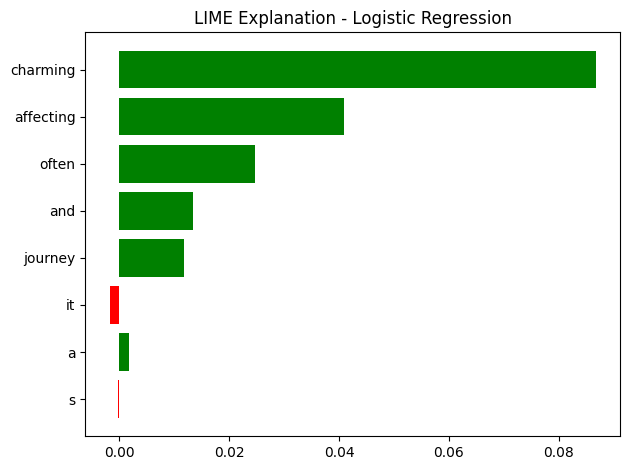

In [19]:
import matplotlib.pyplot as plt

fig = lime_exp.as_pyplot_figure(label=1)

plt.title("LIME Explanation - Logistic Regression")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/lr_lime_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
print("LIME Local R-squared:", round(lime_exp.score, 4))

LIME Local R-squared: 0.6677



## 1.10 SHAP — SHapley Additive exPlanations

### What is SHAP?

SHAP is an explainability method based on Shapley values from cooperative game theory.

It assigns an importance value to each feature by measuring its contribution relative to a baseline prediction.

### How Does SHAP Work?

1. Select a trained classifier and an input sentence.
2. Choose a background dataset to define reference feature values.
3. Estimate how each feature contributes relative to the reference prediction.
4. Assign SHAP values to the features.
5. Identify which words increase or decrease the model's prediction score.

### Mathematical Formulation

SHAP provides an additive explanation:

$$
\boxed{f(x)=\phi_0+\sum_{j=1}^{d}\phi_j}
$$

Where:

- $f(x)$: Model output being explained.
- $\phi_0$: Expected baseline model output.
- $\phi_j$: SHAP contribution of feature $j$.
- $d$: Number of features.

For our linear Logistic Regression classifier, we explain the **logit**, rather than the probability.

With the independent-feature background assumption:

$$
\boxed{\phi_j=w_j(x_j-E[X_j])}
$$

### Why Use SHAP?

1. Provides feature-level explanations.
2. Offers an additive decomposition of the model output.
3. Allows us to identify positive and negative feature contributions.
4. Can be compared against model-based contributions and LIME.
5. Supports systematic explanation agreement analysis.

### Justification

We use SHAP as our third explanation method to investigate how closely different explainability techniques agree on important words.

For Logistic Regression, SHAP's LinearExplainer provides an efficient way to calculate attributions using the trained model coefficients and a reference feature distribution.

### Limitation

SHAP explanations depend on the chosen background distribution and feature-dependence assumptions.

Our TF-IDF SHAP implementation uses an independent-feature assumption, which does not fully capture dependencies between words.


In [21]:
import shap
import numpy as np
import pandas as pd

# Select 200 training examples for SHAP background
rng = np.random.default_rng(42)

background_idx = rng.choice(
    X_train_tfidf.shape[0],
    size=200,
    replace=False
)

background = X_train_tfidf[background_idx]

# Use all 200 background examples
masker = shap.maskers.Independent(
    background,
    max_samples=200
)

# Create SHAP explainer
shap_explainer = shap.LinearExplainer(
    lr_model,
    masker
)
# Same validation example
sample_idx = 0
sentence = X_val.iloc[sample_idx]

sample_vector = X_val_tfidf[
    sample_idx:sample_idx + 1
]

# Compute SHAP values
shap_values = np.asarray(
    shap_explainer.shap_values(sample_vector)
).reshape(-1)

# Present features in the sentence
present_idx = sample_vector.indices

# Create word importance table
shap_df = pd.DataFrame({
    "Word": feature_names[present_idx],
    "SHAP Value": shap_values[present_idx]
})

shap_df["Absolute SHAP"] = (
    shap_df["SHAP Value"].abs()
)

shap_df = shap_df.sort_values(
    "Absolute SHAP",
    ascending=False
)

print("Sentence:", sentence)
print("\nSHAP Word Importance:")

display(shap_df.round(4))

Sentence: it 's a charming and often affecting journey .

SHAP Word Importance:


,Word,SHAP Value,Absolute SHAP
2,charming,1.7674,1.7674
0,affecting,1.0522,1.0522
5,often,0.5685,0.5685
4,journey,0.5130,0.5130
1,and,0.1455,0.1455
3,it,0.0246,0.0246


In [22]:
# Select 200 fixed validation examples
eval_df = (
    val_df.groupby("label", group_keys=False)
    .sample(n=100, random_state=42)
    .sort_index()
)

eval_indices = eval_df.index.to_numpy()

print("Evaluation examples:", len(eval_df))
print(eval_df["label"].value_counts())

Evaluation examples: 200
label
0    100
1    100
Name: count, dtype: int64


In [23]:
# TF-IDF features for selected validation examples
X_eval_tfidf = X_val_tfidf[eval_indices]

# Calculate SHAP values
shap_values_200 = shap_explainer.shap_values(
    X_eval_tfidf
)

shap_values_200 = np.asarray(shap_values_200)

print("SHAP values shape:", shap_values_200.shape)

SHAP values shape: (200, 10000)


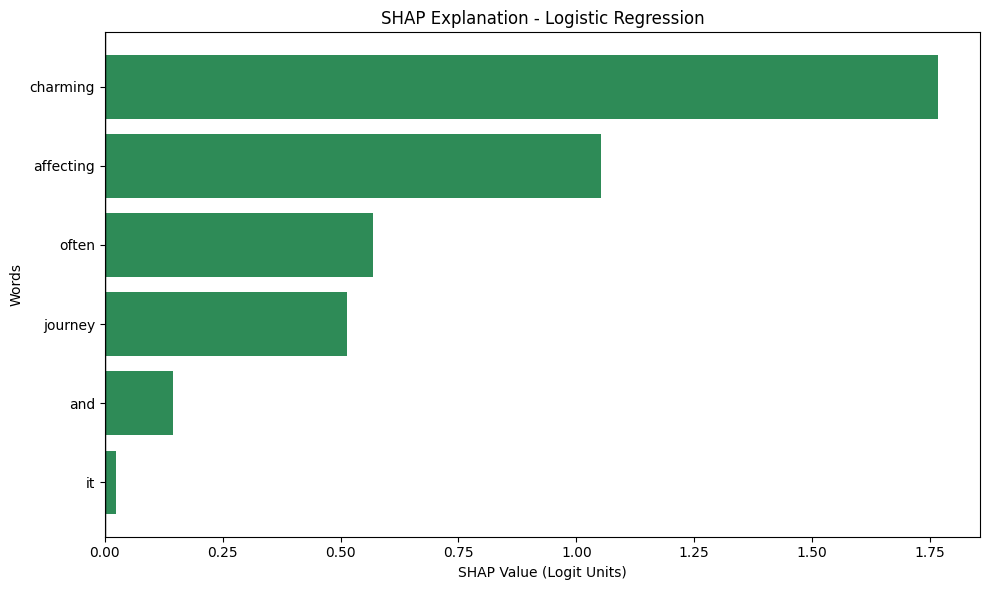

In [24]:
# Plot SHAP values of words present in the sentence
plot_df = shap_df.sort_values("SHAP Value")

colors = [
    "seagreen" if x > 0 else "tomato"
    for x in plot_df["SHAP Value"]
]

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Word"],
    plot_df["SHAP Value"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("SHAP Value (Logit Units)")
plt.ylabel("Words")
plt.title("SHAP Explanation - Logistic Regression")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/lr_shap_explanation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 1.12 LIME Explanations on the Evaluation Dataset

### Objective

Previously, we generated a LIME explanation for only one sentence. However, conclusions based on a single example are insufficient.

We now evaluate LIME on a fixed subset of **200 SST-2 validation sentences**, consisting of:

- 100 positive sentences.
- 100 negative sentences.

### Methodology

1. Use the same 200 validation sentences selected for SHAP.
2. Generate LIME explanations for each sentence.
3. Extract word-level importance scores.
4. Record the local surrogate model's R-squared.
5. Save the explanations for comparison with Logistic Regression contributions and SHAP.

### Justification

Using identical sentences across explanation methods ensures a fair comparison.

A larger evaluation sample reduces dependence on individual examples and enables more reliable aggregate agreement analysis.

We use a fixed random seed for reproducibility.

### Limitation

LIME explanations depend on randomly generated perturbations and may vary across runs.

We will later evaluate explanation stability and report the variation in LIME's local fit.


In [25]:
from lime.lime_text import LimeTextExplainer
from tqdm.auto import tqdm
import numpy as np
import pandas as pd

# Same 200 validation sentences used for SHAP
eval_indices = eval_df.index.to_numpy()

# Initialize LIME
lime_explainer = LimeTextExplainer(
    class_names=["Negative", "Positive"],
    random_state=42
)

# Prediction function
def predict_proba_text(texts):
    return lr_model.predict_proba(
        tfidf.transform(texts)
    )

# Store explanations
lime_results = []

for idx in tqdm(eval_indices, desc="Generating LIME"):

    sentence = X_val.iloc[idx]

    # Generate LIME explanation
    exp = lime_explainer.explain_instance(
        sentence,
        predict_proba_text,
        labels=(1,),
        num_features=1000,
        num_samples=1000
    )

    # Extract word importance
    word_scores = {
        word.lower(): float(weight)
        for word, weight in exp.as_list(label=1)
    }

    lime_results.append({
        "validation_index": int(idx),
        "sentence": sentence,
        "label": int(y_val.iloc[idx]),
        "lime_scores": word_scores,
        "lime_r2": float(exp.score)
    })

print("Total LIME explanations:", len(lime_results))

# Save results
pd.to_pickle(
    lime_results,
    "/kaggle/working/lime_results_200.pkl"
)

print("LIME explanations saved successfully!")

Generating LIME:   0%|          | 0/200 [00:00<?, ?it/s]

Total LIME explanations: 200
LIME explanations saved successfully!


In [26]:
# Collect local R-squared values
lime_r2_values = [
    item["lime_r2"]
    for item in lime_results
]

print("LIME Evaluation Summary")
print("------------------------")
print("Total examples:", len(lime_results))
print("Mean R-squared:", round(np.mean(lime_r2_values), 4))
print("Median R-squared:", round(np.median(lime_r2_values), 4))
print("Minimum R-squared:", round(np.min(lime_r2_values), 4))
print("Maximum R-squared:", round(np.max(lime_r2_values), 4))

LIME Evaluation Summary
------------------------
Total examples: 200
Mean R-squared: 0.8947
Median R-squared: 0.9331
Minimum R-squared: 0.5549
Maximum R-squared: 0.9999


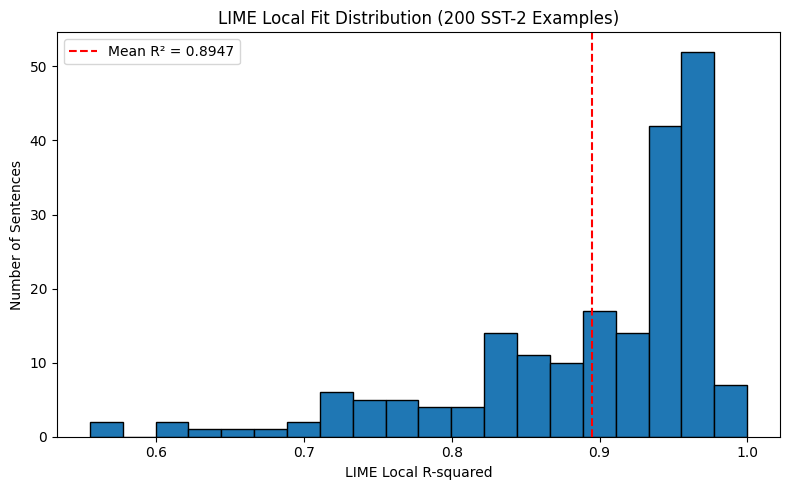

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    lime_r2_values,
    bins=20,
    edgecolor="black"
)

plt.axvline(
    np.mean(lime_r2_values),
    linestyle="--",
    color="red",
    label=f"Mean R² = {np.mean(lime_r2_values):.4f}"
)

plt.xlabel("LIME Local R-squared")
plt.ylabel("Number of Sentences")
plt.title("LIME Local Fit Distribution (200 SST-2 Examples)")

plt.legend()
plt.tight_layout()

plt.savefig(
    "/kaggle/working/lime_r2_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 1.13 Explanation Agreement on 200 Examples

### Objective

We investigate whether Logistic Regression model contributions, LIME, and SHAP identify similar important words for the same predictions.

### Evaluation Setup

- Dataset: SST-2 validation set.
- Evaluation samples: 200 (100 positive, 100 negative).
- Classifier: TF-IDF + Logistic Regression.
- Explanation methods: Model contributions, LIME, SHAP.
- Ranking criterion: Absolute word attribution.
- Evaluation metrics: Top-3 overlap, Top-5 overlap, and Spearman rank correlation.

### Top-k Overlap

$$
\mathrm{Overlap@k}(A,B)=\frac{|A_k\cap B_k|}{k}
$$

This metric measures the proportion of shared words between two top-k explanation rankings.

### Spearman Rank Correlation

$$
\rho_s=\mathrm{corr}(R_A,R_B)
$$

This metric measures the correlation between two word-importance rankings.

### Fair Comparison

All methods are evaluated on the same sentences using a common TF-IDF vocabulary.

We compare only features present in each sentence and consistently use absolute attribution values.

For Top-k overlap, we require at least 2k eligible words to avoid artificially inflated overlap on very short sentences.

We report the actual number of eligible sentences for each metric.

### Justification

Evaluating multiple explanation methods on the same 200 examples provides more reliable comparisons than our preliminary experiments with different sample sizes.

Agreement does not establish faithfulness, so deletion-based evaluation will be conducted separately.


In [28]:
from scipy.stats import spearmanr
import numpy as np
import pandas as pd

# Fixed evaluation indices
eval_indices = eval_df.index.to_numpy()

X_eval_tfidf = X_val_tfidf[eval_indices]

# Retrieve SHAP values for the same 200 examples
shap_values_200 = np.asarray(
    shap_explainer.shap_values(X_eval_tfidf)
)

# Check alignment
assert shap_values_200.shape == X_eval_tfidf.shape
assert len(lime_results) == len(eval_indices)

assert [
    r["validation_index"] for r in lime_results
] == eval_indices.tolist()

# Store aligned explanations
aligned_explanations = []

for pos, idx in enumerate(eval_indices):

    row = X_eval_tfidf[pos]

    # Features actually present in this sentence
    feature_idx = row.indices
    words = feature_names[feature_idx]

    # Model contribution = coefficient * TF-IDF
    model_scores = (
        coefficients[feature_idx] * row.data
    )

    # SHAP values for the same features
    shap_scores = shap_values_200[pos, feature_idx]

    # LIME word importance
    lime_dict = lime_results[pos]["lime_scores"]

    lime_scores = np.array([
        lime_dict.get(word.lower(), 0.0)
        for word in words
    ])

    aligned_explanations.append({
        "validation_index": int(idx),
        "words": words.tolist(),
        "Model": model_scores,
        "LIME": lime_scores,
        "SHAP": shap_scores
    })

print("Aligned examples:", len(aligned_explanations))

print("\nFirst example:")
print("Words:", aligned_explanations[0]["words"])

Aligned examples: 200

First example:
Words: ['and', 'bleak', 'desperate']


In [29]:
def calculate_agreement(words, scores_a, scores_b, k):

    n = len(words)

    # Require enough words for meaningful Top-k comparison
    if n < 2 * k:
        overlap = np.nan
    else:
        top_a = set(
            np.array(words)[np.argsort(-np.abs(scores_a))[:k]]
        )
        top_b = set(
            np.array(words)[np.argsort(-np.abs(scores_b))[:k]]
        )

        overlap = len(top_a & top_b) / k

    # Spearman over all eligible words
    if n < 3:
        rho = np.nan
    else:
        ranks_a = pd.Series(np.abs(scores_a)).rank(
            ascending=False, method="average"
        )
        ranks_b = pd.Series(np.abs(scores_b)).rank(
            ascending=False, method="average"
        )

        if ranks_a.nunique() < 2 or ranks_b.nunique() < 2:
            rho = np.nan
        else:
            rho = spearmanr(ranks_a, ranks_b).statistic

    return overlap, rho


pairs = [
    ("Model", "LIME"),
    ("Model", "SHAP"),
    ("LIME", "SHAP")
]

agreement_records = []

for item in aligned_explanations:

    words = item["words"]

    for a, b in pairs:

        top3, rho = calculate_agreement(
            words, item[a], item[b], k=3
        )

        top5, _ = calculate_agreement(
            words, item[a], item[b], k=5
        )

        agreement_records.append({
            "validation_index": item["validation_index"],
            "Comparison": f"{a} vs {b}",
            "N_Words": len(words),
            "Top3": top3,
            "Top5": top5,
            "Spearman": rho
        })

agreement_200 = pd.DataFrame(agreement_records)

# Aggregate results and report valid sample counts
agreement_summary = agreement_200.groupby(
    "Comparison"
).agg(
    Total_Sentences=("validation_index", "size"),
    Top3_Mean=("Top3", "mean"),
    Top3_N=("Top3", "count"),
    Top5_Mean=("Top5", "mean"),
    Top5_N=("Top5", "count"),
    Spearman_Mean=("Spearman", "mean"),
    Spearman_N=("Spearman", "count")
)

display(agreement_summary.round(4))

# Save for report
agreement_200.to_csv(
    "/kaggle/working/agreement_200.csv",
    index=False
)

agreement_summary.to_csv(
    "/kaggle/working/agreement_summary.csv"
)

,Total_Sentences,Top3_Mean,Top3_N,Top5_Mean,Top5_N,Spearman_Mean,Spearman_N
Comparison,,,,,,,
LIME vs SHAP,200,0.9185,180,0.9101,149,0.9227,197
Model vs LIME,200,0.9204,180,0.9141,149,0.9255,197
Model vs SHAP,200,0.9907,180,0.9893,149,0.9923,197



## 1.14 Faithfulness Evaluation Using Word Deletion

### Objective

Explanation agreement indicates whether methods highlight similar words. However, explanations may agree without identifying features that meaningfully influence the model's prediction.

We therefore evaluate explanation faithfulness using word deletion.

### Methodology

1. Select the same validation sentences for all explanation methods.
2. Rank words by absolute attribution magnitude.
3. Remove the top-1, top-3, and top-5 important words.
4. Recalculate the classifier's predicted probability.
5. Measure the change in probability.
6. Compare against randomly selected word deletion.

### Probability Change

We measure the absolute change in the probability of the originally predicted class:

$$
\Delta_k = \left|P(y=\hat{y}\mid x)-P(y=\hat{y}\mid x_{\setminus S_k})\right|
$$

Where:

- $x$: Original sentence.
- $\hat{y}$: Originally predicted class.
- $S_k$: Set of top-k important words.
- $x_{\setminus S_k}$: Sentence after deleting these words.
- $\Delta_k$: Absolute probability change.

### Random Baseline

For each sentence, we also randomly select and remove the same number of words.

We repeat random deletion 20 times per sentence to reduce random variation.

### Fair Evaluation

We use the same eligible sentences for every explanation method and deletion level.

For comparability across k = 1, 3, and 5, we restrict this experiment to sentences with at least 10 eligible TF-IDF word features.

### Interpretation

An explanation method is considered more effective under this test if deleting its selected words produces a larger probability change than deleting randomly selected words.

However, deletion can produce unnatural sentences. Therefore, deletion-based faithfulness is a behavioral test, not definitive proof of causal importance.


In [30]:
import numpy as np
import pandas as pd
import re

rng = np.random.default_rng(42)

methods = ["Model", "LIME", "SHAP"]
k_values = [1, 3, 5]
random_trials = 20

# Consistent eligible sentence set
eligible_items = [
    item for item in aligned_explanations
    if len(item["words"]) >= 10
]

print("Eligible sentences:", len(eligible_items))

# Function to remove selected words
def remove_words(sentence, words):
    text = sentence

    for word in words:
        pattern = r"(?<!\w)" + re.escape(word) + r"(?!\w)"
        text = re.sub(
            pattern, "",
            text,
            flags=re.IGNORECASE
        )

    return re.sub(r"\s+", " ", text).strip()


# Prepare all deletion experiments
records = []
modified_sentences = []

for item in eligible_items:

    idx = item["validation_index"]
    sentence = X_val.iloc[idx]
    words = np.array(item["words"])

    original_class = int(y_pred_lr[idx])

    for k in k_values:

        # Explanations: Model, LIME, SHAP
        for method in methods:

            scores = np.asarray(item[method])

            # Deterministic ranking, with alphabetical tie breaking
            order = sorted(
                range(len(words)),
                key=lambda j: (-abs(scores[j]), words[j])
            )

            selected_words = words[order[:k]]

            modified_sentences.append(
                remove_words(sentence, selected_words)
            )

            records.append({
                "index": idx,
                "Method": method,
                "k": k,
                "Original_Class": original_class
            })

        # Random deletion baseline
        for trial in range(random_trials):

            selected_words = rng.choice(
                words,
                size=k,
                replace=False
            )

            modified_sentences.append(
                remove_words(sentence, selected_words)
            )

            records.append({
                "index": idx,
                "Method": "Random",
                "k": k,
                "Original_Class": original_class
            })


# Predictions for all modified sentences
modified_tfidf = tfidf.transform(modified_sentences)

modified_probs = lr_model.predict_proba(
    modified_tfidf
)

original_probs = lr_model.predict_proba(
    X_val_tfidf
)

# Compute probability changes
for i, record in enumerate(records):

    idx = record["index"]
    cls = record["Original_Class"]

    p_before = original_probs[idx, cls]
    p_after = modified_probs[i, cls]

    record["Absolute_Change"] = abs(
        p_before - p_after
    )

    record["Signed_Drop"] = (
        p_before - p_after
    )

deletion_df = pd.DataFrame(records)

# Aggregate results
deletion_summary = (
    deletion_df
    .groupby(["Method", "k"])
    .agg(
        Mean_Absolute_Change=("Absolute_Change", "mean"),
        Mean_Signed_Drop=("Signed_Drop", "mean"),
        N_Sentences=("index", "nunique")
    )
    .reset_index()
)

display(deletion_summary.round(4))

# Save results
deletion_df.to_csv(
    "/kaggle/working/deletion_results.csv",
    index=False
)

deletion_summary.to_csv(
    "/kaggle/working/deletion_summary.csv",
    index=False
)

Eligible sentences: 149


,Method,k,Mean_Absolute_Change,Mean_Signed_Drop,N_Sentences
0,LIME,1,0.1451,0.0795,149
1,LIME,3,0.1790,0.1361,149
2,LIME,5,0.1891,0.1647,149
3,Model,1,0.1448,0.0793,149
4,Model,3,0.2069,0.1655,149
5,Model,5,0.2355,0.2128,149
6,Random,1,0.0384,0.0094,149
7,Random,3,0.0756,0.0282,149
8,Random,5,0.1061,0.0465,149
9,SHAP,1,0.1448,0.0793,149


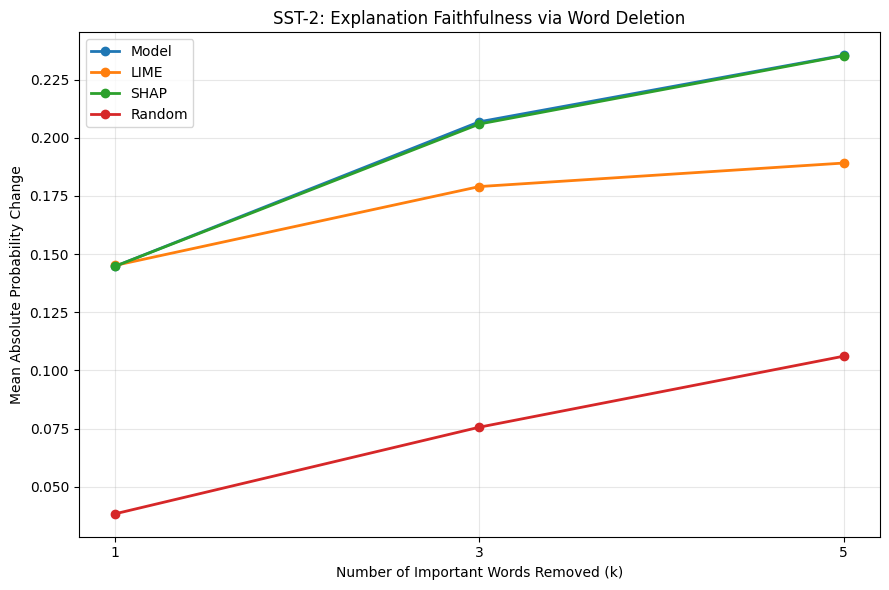

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for method in ["Model", "LIME", "SHAP", "Random"]:

    subset = deletion_summary[
        deletion_summary["Method"] == method
    ]

    plt.plot(
        subset["k"],
        subset["Mean_Absolute_Change"],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Number of Important Words Removed (k)")
plt.ylabel("Mean Absolute Probability Change")
plt.title("SST-2: Explanation Faithfulness via Word Deletion")

plt.xticks([1, 3, 5])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/deletion_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 1.15 Signed Probability Drop and Statistical Reliability

### Why is another evaluation metric needed?

Our previous experiment measured the absolute change in predicted probability after deleting important words.

However, absolute probability change does not distinguish between a decrease and an increase in model confidence.

To evaluate whether removing important words reduces confidence in the original prediction, we also measure the signed probability drop.

### Signed Probability Drop

$$
\Delta_k =
P(\hat{y}\mid x) -
P(\hat{y}\mid x_{\setminus S_k})
$$

Where:

- $\hat{y}$: Original predicted class.
- $x$: Original sentence.
- $S_k$: Selected top-k important words.
- $x_{\setminus S_k}$: Sentence after removing the selected words.

### Interpretation

- **Positive drop:** Removing the words decreases confidence in the original prediction.
- **Zero drop:** Removing the words does not change confidence.
- **Negative drop:** Removing the words increases confidence.

### Statistical Reliability

We report the mean signed probability drop and a 95% bootstrap confidence interval.

For the random baseline, multiple deletion trials are first averaged within each sentence, so that one sentence is not incorrectly counted as 20 independent observations.

### Justification

Signed probability drop provides a complementary evaluation of explanation faithfulness, while confidence intervals help quantify uncertainty due to the limited evaluation sample.


In [32]:
import numpy as np
import pandas as pd

# Average repeated random trials within each sentence
sentence_results = (
    deletion_df
    .groupby(["index", "Method", "k"], as_index=False)
    .agg(
        Signed_Drop=("Signed_Drop", "mean"),
        Absolute_Change=("Absolute_Change", "mean")
    )
)

rng = np.random.default_rng(42)
summary = []

for (method, k), group in sentence_results.groupby(
    ["Method", "k"]
):
    values = group["Signed_Drop"].to_numpy()

    # Bootstrap by sentence
    boot_means = rng.choice(
        values,
        size=(2000, len(values)),
        replace=True
    ).mean(axis=1)

    ci_low, ci_high = np.percentile(
        boot_means, [2.5, 97.5]
    )

    summary.append({
        "Method": method,
        "k": k,
        "N": len(values),
        "Mean Signed Drop": values.mean(),
        "Mean Absolute Change":
            group["Absolute_Change"].mean(),
        "CI Lower": ci_low,
        "CI Upper": ci_high
    })

faithfulness_summary = pd.DataFrame(summary)

display(
    faithfulness_summary
    .sort_values(["k", "Method"])
    .round(4)
)

faithfulness_summary.to_csv(
    "/kaggle/working/faithfulness_with_ci.csv",
    index=False
)

,Method,k,N,Mean Signed Drop,Mean Absolute Change,CI Lower,CI Upper
0,LIME,1,149,0.0795,0.1451,0.0569,0.1028
3,Model,1,149,0.0793,0.1448,0.0579,0.1016
6,Random,1,149,0.0094,0.0384,0.0072,0.0115
9,SHAP,1,149,0.0793,0.1448,0.0579,0.1015
1,LIME,3,149,0.1361,0.1790,0.1081,0.1630
4,Model,3,149,0.1655,0.2069,0.1364,0.1932
7,Random,3,149,0.0282,0.0756,0.0239,0.0326
10,SHAP,3,149,0.1645,0.2059,0.1370,0.1935
2,LIME,5,149,0.1647,0.1891,0.1409,0.1886
5,Model,5,149,0.2128,0.2355,0.1852,0.2403



## 2.1 Text Tokenization and Vocabulary for GRU

### Objective

Unlike Logistic Regression, which uses TF-IDF vectors, a GRU processes a sequence of word embeddings.

Therefore, we convert each sentence into an ordered sequence of integer token IDs.

### Preprocessing Steps

1. **Tokenization:** Split sentences into individual words.
2. **Lowercasing:** Standardize word capitalization.
3. **Vocabulary Construction:** Assign a unique integer ID to each word.
4. **Numerical Encoding:** Convert sentences into sequences of token IDs.
5. **Padding and Truncation:** Standardize sequence lengths for batch training.

### Vocabulary

We construct the vocabulary using only the SST-2 training data to prevent data leakage.

Special tokens:

- `<PAD>`: Used to pad sequences.
- `<UNK>`: Used for words not present in the vocabulary.

### Sequence Length

We examine the distribution of tokenized training sentence lengths and select the 95th percentile as an initial sequence-length limit, capped at 128 tokens.

This provides a practical balance between retaining sentence information and reducing unnecessary computation. We will report the actual truncation rate.

### Why Use GRU?

A Gated Recurrent Unit (GRU) is a recurrent neural network architecture that learns dependencies across a sequence.

Unlike unigram TF-IDF, GRU can account for word order and surrounding context.

### Why Add Attention?

Attention assigns weights to the GRU's hidden states, allowing the classifier to combine information from different word positions.

These attention weights can be examined as potential explanations and compared with LIME.

However, attention weights should not automatically be interpreted as faithful feature importance. We will test them using deletion experiments.


In [33]:
import joblib
import os

os.makedirs("/kaggle/working/models", exist_ok=True)

joblib.dump(
    lr_model,
    "/kaggle/working/models/logistic_regression.pkl"
)

joblib.dump(
    tfidf,
    "/kaggle/working/models/tfidf.pkl"
)

print("Logistic Regression and TF-IDF saved!")

Logistic Regression and TF-IDF saved!


In [34]:
import re
import numpy as np
from collections import Counter

# Tokenization
def tokenize(text):
    return re.findall(
        r"[a-z]+(?:'[a-z]+)?",
        str(text).lower()
    )

# Tokenize training and validation sentences
train_tokens = [tokenize(s) for s in X_train]
val_tokens = [tokenize(s) for s in X_val]

# Word frequency counts from training data only
word_counts = Counter(
    word for sentence in train_tokens for word in sentence
)

# Vocabulary settings
MAX_VOCAB = 20000
MIN_FREQ = 2

vocab = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, count in word_counts.most_common():
    if count < MIN_FREQ or len(vocab) >= MAX_VOCAB:
        break
    vocab[word] = len(vocab)

# Sentence length statistics
train_lengths = np.array([len(s) for s in train_tokens])
val_lengths = np.array([len(s) for s in val_tokens])

# Maximum sequence length for GRU
MAX_LEN = 64

print("Vocabulary size:", len(vocab))
print("Maximum sequence length:", MAX_LEN)
print("Average train length:", round(train_lengths.mean(), 2))
print("Median train length:", np.median(train_lengths))
print("Maximum train length:", train_lengths.max())

print(
    "Training truncation rate:",
    round(100 * np.mean(train_lengths > MAX_LEN), 2), "%"
)

print(
    "Validation truncation rate:",
    round(100 * np.mean(val_lengths > MAX_LEN), 2), "%"
)

print("\nExample sentence:", X_train.iloc[0])
print("Tokens:", train_tokens[0])

Vocabulary size: 13238
Maximum sequence length: 64
Average train length: 8.84
Median train length: 6.0
Maximum train length: 48
Training truncation rate: 0.0 %
Validation truncation rate: 0.0 %

Example sentence: hide new secretions from the parental units
Tokens: ['hide', 'new', 'secretions', 'from', 'the', 'parental', 'units']



## 2.2 Token Encoding and Padding

### Objective

GRU models cannot directly process text. Therefore, we convert each tokenized sentence into a sequence of integer IDs.

### Token Encoding

Each word is mapped to its corresponding vocabulary index.

For example:

**Sentence:** "the movie was good"

**Token IDs (illustrative):** `[5, 18, 27, 42]`

We use two special tokens:

- `<PAD>` (ID = 0): Used to pad shorter sentences.
- `<UNK>` (ID = 1): Represents words not present in the training vocabulary.

### Padding and Truncation

GRU processes batches of sentences with different lengths. We standardize their tensor representation by padding all sequences to 64 tokens.

**Example:**

Original: `[5, 18, 27, 42]`

Padded: `[5, 18, 27, 42, 0, 0, ...]`

### Why MAX_LEN = 64?

Based on our dataset analysis:

- Maximum training sentence length: 48 tokens.
- Training truncation rate: 0%.
- Validation truncation rate: 0%.

Therefore, 64 tokens are sufficient to preserve all words in the training and validation sentences.

We also store actual sequence lengths to distinguish meaningful tokens from padding.

### Justification

Token encoding converts sentences into numerical sequences suitable for GRU training. Padding enables efficient batch processing, while actual sequence lengths allow us to exclude padding from sequence processing and attention calculations.


In [35]:
import torch
import numpy as np

PAD_IDX = vocab["<PAD>"]
UNK_IDX = vocab["<UNK>"]

def encode_and_pad(tokens, max_len=MAX_LEN):

    # Convert tokens to integer IDs
    ids = [vocab.get(word, UNK_IDX) for word in tokens]

    if len(ids) == 0:
        ids = [UNK_IDX]

    # Truncate only if needed
    ids = ids[:max_len]

    # Preserve actual sentence length
    length = len(ids)

    # Pad to MAX_LEN
    ids = ids + [PAD_IDX] * (max_len - length)

    return ids, length


# Encode training and validation sentences
train_encoded = [
    encode_and_pad(tokens) for tokens in train_tokens
]

val_encoded = [
    encode_and_pad(tokens) for tokens in val_tokens
]

# Extract IDs and lengths
train_ids, train_seq_lengths = zip(*train_encoded)
val_ids, val_seq_lengths = zip(*val_encoded)

# Convert to PyTorch tensors
X_train_gru = torch.tensor(train_ids, dtype=torch.long)
X_val_gru = torch.tensor(val_ids, dtype=torch.long)

train_seq_lengths = torch.tensor(
    train_seq_lengths, dtype=torch.long
)

val_seq_lengths = torch.tensor(
    val_seq_lengths, dtype=torch.long
)

y_train_gru = torch.tensor(
    y_train.to_numpy(), dtype=torch.long
)

y_val_gru = torch.tensor(
    y_val.to_numpy(), dtype=torch.long
)

print("Training shape:", X_train_gru.shape)
print("Validation shape:", X_val_gru.shape)

print("\nFirst sentence:")
print(X_train.iloc[0])

print("\nEncoded token IDs:")
print(X_train_gru[0].tolist())

print("\nActual sentence length:")
print(train_seq_lengths[0].item())

Training shape: torch.Size([67349, 64])
Validation shape: torch.Size([872, 64])

First sentence:
hide new secretions from the parental units

Encoded token IDs:
[4537, 86, 11573, 32, 2, 7088, 8609, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Actual sentence length:
7



## 2.3 PyTorch DataLoaders and GPU Setup

### Objective

After converting SST-2 sentences into padded token sequences, we prepare the data for efficient GRU training using PyTorch DataLoaders.

### What is a DataLoader?

A DataLoader divides the dataset into smaller batches instead of processing all sentences simultaneously.

Each batch contains:

- Token IDs representing the sentences.
- Actual sequence lengths before padding.
- Sentiment labels (0 = Negative, 1 = Positive).

### Batch Size

We use a batch size of 64.

This allows the model to process multiple sentences together while maintaining reasonable memory usage.

### Training vs Validation

**Training DataLoader:**

- Batch size = 64.
- Shuffling enabled.
- Used for updating model parameters.

**Validation DataLoader:**

- Batch size = 64.
- Shuffling disabled.
- Used for measuring model performance.

### GPU Acceleration

Neural network training involves repeated matrix operations.

We use a GPU when available to accelerate GRU training.

The implementation automatically selects CUDA if available, otherwise CPU.

### Justification

DataLoaders provide efficient batching and make model training reproducible when combined with controlled random seeds.

We preserve sequence lengths so that padding tokens can be excluded from the GRU's sequential representation and attention computations.


In [36]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Batch size
BATCH_SIZE = 64

# Create training dataset
train_dataset = TensorDataset(
    X_train_gru,
    train_seq_lengths,
    y_train_gru
)

# Create validation dataset
val_dataset = TensorDataset(
    X_val_gru,
    val_seq_lengths,
    y_val_gru
)

# Create DataLoaders
torch.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Check one training batch
batch_x, batch_lengths, batch_y = next(
    iter(train_loader)
)

print("Input batch shape:", batch_x.shape)
print("Lengths shape:", batch_lengths.shape)
print("Labels shape:", batch_y.shape)

# Check GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Input batch shape: torch.Size([64, 64])
Lengths shape: torch.Size([64])
Labels shape: torch.Size([64])

Device: cuda
GPU: Tesla T4



## 2.4 Bidirectional GRU with Attention

### Objective

We implement a Bidirectional Gated Recurrent Unit (BiGRU) with an attention mechanism for binary sentiment classification on SST-2.

Unlike the TF-IDF Logistic Regression baseline, a GRU processes sentences as ordered sequences and can capture contextual dependencies between words.

### 1. Embedding Layer

Each input token is converted into a dense embedding vector.

$$
\mathbf{x}_t=E[w_t]
$$

Where:

- $w_t$: Token ID at position $t$.
- $E$: Learnable embedding matrix.
- $\mathbf{x}_t$: Embedding vector of size 128.

### 2. Bidirectional GRU

A GRU processes the sequence using gating mechanisms that regulate information flow.

The update gate is:

$$
\mathbf{z}_t=\sigma(W_z\mathbf{x}_t+U_z\mathbf{h}_{t-1}+\mathbf{b}_z)
$$

The reset gate is:

$$
\mathbf{r}_t=\sigma(W_r\mathbf{x}_t+U_r\mathbf{h}_{t-1}+\mathbf{b}_r)
$$

The candidate hidden state is:

$$
\tilde{\mathbf{h}}_t=\tanh(W_h\mathbf{x}_t+U_h(\mathbf{r}_t\odot\mathbf{h}_{t-1})+\mathbf{b}_h)
$$

The updated hidden state is:

$$
\mathbf{h}_t=(1-\mathbf{z}_t)\odot\mathbf{h}_{t-1}+\mathbf{z}_t\odot\tilde{\mathbf{h}}_t
$$

A Bidirectional GRU processes each sentence in forward and backward directions.

The two hidden states are concatenated:

$$
\mathbf{h}_t=[\overrightarrow{\mathbf{h}}_t;\overleftarrow{\mathbf{h}}_t]
$$

Each direction has 128 hidden units, producing a 256-dimensional representation.

### 3. Attention Mechanism

Not every word contributes equally to sentiment prediction.

The attention mechanism learns a score for each token position:

$$
e_t=\mathbf{v}^{T}\tanh(W_a\mathbf{h}_t+\mathbf{b}_a)
$$

Attention scores are normalized using softmax:

$$
\alpha_t=\frac{\exp(e_t)}{\sum_{j=1}^{T}\exp(e_j)}
$$

Where:

- $e_t$: Unnormalized attention score.
- $\alpha_t$: Attention weight for token $t$.
- $T$: Number of actual tokens.

Padding positions are masked before softmax.

### 4. Context Vector

The model calculates a weighted sum of hidden states:

$$
\mathbf{c}=\sum_{t=1}^{T}\alpha_t\mathbf{h}_t
$$

The context vector summarizes the sentence using the learned attention weights.

### 5. Classification Layer

The context vector is passed through a fully connected layer:

$$
\mathbf{o}=W_c\mathbf{c}+\mathbf{b}_c
$$

The two logits are converted into sentiment probabilities using softmax:

$$
P(y=k\mid x)=\frac{\exp(o_k)}{\sum_{j=0}^{1}\exp(o_j)}
$$

The predicted sentiment is the class with the highest probability.

### Model Configuration

| Parameter | Value |
|---|---|
| Vocabulary Size | 13,238 |
| Maximum Sequence Length | 64 |
| Embedding Dimension | 128 |
| GRU Hidden Dimension | 128 |
| GRU Directions | Bidirectional |
| Attention Dimension | 128 |
| Dropout | 0.3 |
| Output Classes | 2 |

### Why Use Attention?

Attention provides a mechanism for combining information from different positions in a sentence.

It also produces token-level weights that we can examine and compare against LIME explanations.

However, attention weights are not necessarily faithful explanations. We will evaluate their usefulness through explanation agreement and word-deletion experiments.

### Justification

We select a Bidirectional GRU with attention as our neural baseline because it can represent sequential context while providing explicit token-level attention scores.

This enables us to investigate whether attention identifies words that meaningfully influence sentiment predictions.


In [37]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

class GRUAttention(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        attention_dim=128,
        num_classes=2,
        dropout=0.3,
        pad_idx=0
    ):
        super().__init__()

        # 1. Embedding layer
        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=pad_idx
        )

        # 2. Bidirectional GRU
        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        # 3. Attention scoring network
        self.attention = nn.Sequential(
            nn.Linear(hidden_dim * 2, attention_dim),
            nn.Tanh(),
            nn.Linear(attention_dim, 1)
        )

        # 4. Dropout
        self.dropout = nn.Dropout(dropout)

        # 5. Classification layer
        self.fc = nn.Linear(
            hidden_dim * 2,
            num_classes
        )

    def forward(self, input_ids, lengths):

        # Embeddings: [batch, 64, 128]
        embedded = self.embedding(input_ids)

        # Pack to exclude padding during GRU processing
        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # GRU processing
        packed_output, _ = self.gru(packed)

        # Restore padded tensor
        gru_output, _ = pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=input_ids.size(1)
        )

        # Attention scores: [batch, 64]
        scores = self.attention(gru_output).squeeze(-1)

        # Mask padding tokens
        positions = torch.arange(
            input_ids.size(1),
            device=input_ids.device
        )

        mask = positions.unsqueeze(0) < lengths.unsqueeze(1)

        scores = scores.masked_fill(mask == 0, -1e9)

        # Normalize attention weights
        attention_weights = F.softmax(scores, dim=1)

        # Weighted context vector
        context = torch.sum(
            gru_output * attention_weights.unsqueeze(-1),
            dim=1
        )

        # Classification logits
        logits = self.fc(self.dropout(context))

        return logits, attention_weights


# Initialize model
gru_model = GRUAttention(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    attention_dim=128,
    dropout=0.3,
    pad_idx=PAD_IDX
).to(device)

print(gru_model)

print(
    "\nTrainable parameters:",
    sum(p.numel() for p in gru_model.parameters() if p.requires_grad)
)


GRUAttention(
  (embedding): Embedding(13238, 128, padding_idx=0)
  (gru): GRU(128, 128, batch_first=True, bidirectional=True)
  (attention): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=256, out_features=2, bias=True)
)

Trainable parameters: 1926147


In [38]:

# Get one batch
batch_x, batch_lengths, batch_y = next(
    iter(train_loader)
)

# Move batch to GPU
batch_x = batch_x.to(device)
batch_lengths = batch_lengths.to(device)

# Evaluation mode
gru_model.eval()

with torch.no_grad():
    logits, attention_weights = gru_model(
        batch_x,
        batch_lengths
    )

print("Input shape:", batch_x.shape)
print("Logits shape:", logits.shape)
print("Attention shape:", attention_weights.shape)

# Check attention sums
print(
    "\nAttention sum (first sentence):",
    attention_weights[0].sum().item()
)

# Check that padding has zero attention
first_length = batch_lengths[0].item()

print(
    "Maximum padded-token attention:",
    attention_weights[0, first_length:].max().item()
    if first_length < batch_x.size(1) else 0.0
)

# Predicted probabilities
probs = torch.softmax(logits, dim=1)

print("\nFirst sentence probabilities:", probs[0].tolist())


Input shape: torch.Size([64, 64])
Logits shape: torch.Size([64, 2])
Attention shape: torch.Size([64, 64])

Attention sum (first sentence): 1.0
Maximum padded-token attention: 0.0

First sentence probabilities: [0.5016186237335205, 0.4983813762664795]



## 2.5 GRU with Attention — Model Training

### Objective

We train the Bidirectional GRU with Attention on the SST-2 dataset to predict positive and negative sentiment.

### Training Configuration

| Hyperparameter | Value |
|---|---|
| Optimizer | Adam |
| Learning Rate | 0.001 |
| Loss Function | Cross-Entropy |
| Batch Size | 64 |
| Maximum Epochs | 10 |
| Early Stopping Patience | 3 |
| Gradient Clipping | 1.0 |
| Dropout | 0.3 |
| Random Seed | 42 |

### Cross-Entropy Loss

For a binary classifier with two output logits, we use cross-entropy loss:

$$
\boxed{
L=-\frac{1}{N}\sum_{i=1}^{N}
\log P(y_i\mid x_i)
}
$$

Where:

- $N$: Number of training examples.
- $y_i$: True sentiment label.
- $x_i$: Input sentence.
- $P(y_i\mid x_i)$: Predicted probability assigned to the correct class.

### Adam Optimizer

We use Adam to update the trainable parameters of the embedding, GRU, attention, and classification layers.

Adam adapts parameter-wise learning rates using estimates of the first and second moments of gradients.

### Early Stopping

Training for too many epochs may cause overfitting.

We monitor development-set cross-entropy loss and stop training if it does not improve for three consecutive epochs.

The best-performing model checkpoint is saved for later evaluation.

### Gradient Clipping

We clip the gradient norm to 1.0 to help prevent excessively large gradients during recurrent neural network training.

### Justification

Using a separate development split, early stopping, dropout, and gradient clipping provides a more controlled training procedure.

The official SST-2 validation split is reserved for evaluating the final selected classifier.


In [39]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
import numpy as np
import torch

# Split only the original training data
all_indices = np.arange(len(train_dataset))

train_idx, dev_idx = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=42,
    stratify=y_train.to_numpy()
)

# Create subsets
train_subset = Subset(train_dataset, train_idx)
dev_subset = Subset(train_dataset, dev_idx)

# Create DataLoaders
train_fit_loader = DataLoader(
    train_subset,
    batch_size=64,
    shuffle=True
)

dev_loader = DataLoader(
    dev_subset,
    batch_size=64,
    shuffle=False
)

print("Training examples:", len(train_subset))
print("Development examples:", len(dev_subset))
print("Official validation examples:", len(val_dataset))
print("Device:", device)

Training examples: 60614
Development examples: 6735
Official validation examples: 872
Device: cuda


In [40]:
import torch.nn as nn
import torch.optim as optim

# Reinitialize for a reproducible fresh training run
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

gru_model = GRUAttention(
    vocab_size=len(vocab),
    embedding_dim=128,
    hidden_dim=128,
    attention_dim=128,
    dropout=0.3,
    pad_idx=PAD_IDX
).to(device)

# Loss function
criterion = nn.CrossEntropyLoss()

# Adam optimizer
optimizer = optim.Adam(
    gru_model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

EPOCHS = 10
PATIENCE = 3

print("Model and optimizer initialized!")
print("Training device:", device)

Model and optimizer initialized!
Training device: cuda


In [41]:
import torch
import numpy as np
import pandas as pd
import os
import copy

from sklearn.metrics import accuracy_score, f1_score

os.makedirs("/kaggle/working/models", exist_ok=True)

history = []

best_dev_loss = float("inf")
best_model_state = None
patience_counter = 0

for epoch in range(EPOCHS):

    # ========== TRAINING ==========
    gru_model.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    for inputs, lengths, labels in train_fit_loader:

        inputs = inputs.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits, _ = gru_model(inputs, lengths)

        loss = criterion(logits, labels)

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            gru_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_train_loss += loss.item() * labels.size(0)

        predictions = torch.argmax(logits, dim=1)

        train_preds.extend(predictions.cpu().tolist())
        train_labels.extend(labels.cpu().tolist())

    train_loss = total_train_loss / len(train_subset)

    train_acc = accuracy_score(train_labels, train_preds)

    train_f1 = f1_score(
        train_labels, train_preds, average="macro"
    )

    # ========== DEVELOPMENT ==========
    gru_model.eval()

    total_dev_loss = 0
    dev_preds = []
    dev_labels = []

    with torch.no_grad():

        for inputs, lengths, labels in dev_loader:

            inputs = inputs.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits, _ = gru_model(inputs, lengths)

            loss = criterion(logits, labels)

            total_dev_loss += loss.item() * labels.size(0)

            predictions = torch.argmax(logits, dim=1)

            dev_preds.extend(predictions.cpu().tolist())
            dev_labels.extend(labels.cpu().tolist())

    dev_loss = total_dev_loss / len(dev_subset)

    dev_acc = accuracy_score(dev_labels, dev_preds)

    dev_f1 = f1_score(
        dev_labels, dev_preds, average="macro"
    )

    history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Dev Loss": dev_loss,
        "Train Accuracy": train_acc,
        "Dev Accuracy": dev_acc,
        "Train F1": train_f1,
        "Dev F1": dev_f1
    })

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Dev Loss: {dev_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Dev Acc: {dev_acc:.4f} | "
        f"Dev F1: {dev_f1:.4f}"
    )

    # ========== EARLY STOPPING ==========
    if dev_loss < best_dev_loss - 1e-4:

        best_dev_loss = dev_loss

        best_model_state = copy.deepcopy(
            gru_model.state_dict()
        )

        patience_counter = 0

        torch.save(
            best_model_state,
            "/kaggle/working/models/best_gru_attention.pt"
        )

        print("  Best model saved!")

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

# Load the best model
gru_model.load_state_dict(best_model_state)
gru_model.eval()

# Save history
history_df = pd.DataFrame(history)

history_df.to_csv(
    "/kaggle/working/gru_training_history.csv",
    index=False
)

print("\nGRU Training Completed!")
print("Best development loss:", round(best_dev_loss, 4))

Epoch 1/10 | Train Loss: 0.4682 | Dev Loss: 0.3319 | Train Acc: 0.7652 | Dev Acc: 0.8543 | Dev F1: 0.8515
  Best model saved!
Epoch 2/10 | Train Loss: 0.2445 | Dev Loss: 0.2495 | Train Acc: 0.9025 | Dev Acc: 0.8955 | Dev F1: 0.8942
  Best model saved!
Epoch 3/10 | Train Loss: 0.1616 | Dev Loss: 0.2243 | Train Acc: 0.9400 | Dev Acc: 0.9122 | Dev F1: 0.9110
  Best model saved!
Epoch 4/10 | Train Loss: 0.1228 | Dev Loss: 0.2231 | Train Acc: 0.9564 | Dev Acc: 0.9188 | Dev F1: 0.9176
  Best model saved!
Epoch 5/10 | Train Loss: 0.0972 | Dev Loss: 0.2351 | Train Acc: 0.9659 | Dev Acc: 0.9225 | Dev F1: 0.9216
Epoch 6/10 | Train Loss: 0.0819 | Dev Loss: 0.2285 | Train Acc: 0.9713 | Dev Acc: 0.9264 | Dev F1: 0.9255
Epoch 7/10 | Train Loss: 0.0695 | Dev Loss: 0.2533 | Train Acc: 0.9752 | Dev Acc: 0.9252 | Dev F1: 0.9242
Early stopping triggered.

GRU Training Completed!
Best development loss: 0.2231


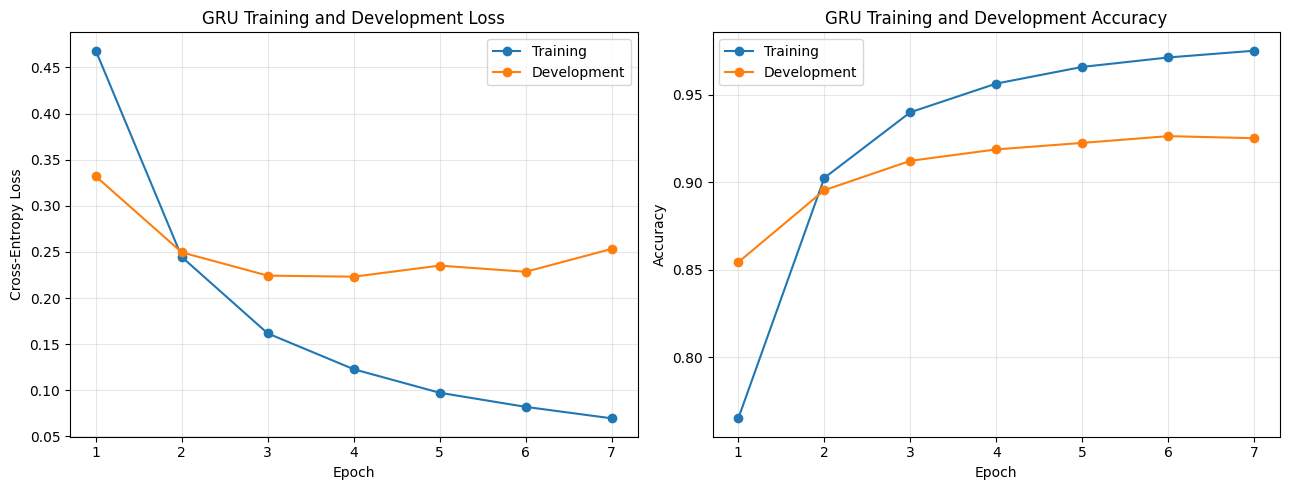

In [42]:
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss
axes[0].plot(
    history_df["Epoch"],
    history_df["Train Loss"],
    marker="o",
    label="Training"
)

axes[0].plot(
    history_df["Epoch"],
    history_df["Dev Loss"],
    marker="o",
    label="Development"
)

axes[0].set_title("GRU Training and Development Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(
    history_df["Epoch"],
    history_df["Train Accuracy"],
    marker="o",
    label="Training"
)

axes[1].plot(
    history_df["Epoch"],
    history_df["Dev Accuracy"],
    marker="o",
    label="Development"
)

axes[1].set_title("GRU Training and Development Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gru_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.6 GRU Model Evaluation

### Objective

After training the Bidirectional GRU with Attention, we evaluate its classification performance on the official SST-2 validation set.

### Evaluation Metrics

We calculate:

1. **Accuracy:** Fraction of correctly classified sentences.
2. **Macro Precision:** Average precision across both sentiment classes.
3. **Macro Recall:** Average recall across both sentiment classes.
4. **Macro F1:** Average of the individual class F1-scores.
5. **ROC-AUC:** Measures the model's ability to distinguish positive and negative examples.
6. **Confusion Matrix:** Shows correct and incorrect classifications.

### Evaluation Procedure

We load the best checkpoint selected using development loss and evaluate it on all 872 official validation examples.

The same evaluation metrics are used for Logistic Regression and GRU to make classification performance comparable.

### Justification

Evaluating the selected checkpoint on the full validation dataset gives us a consistent measure of model performance before conducting explanation experiments.

The model is placed in evaluation mode to disable dropout, and gradients are disabled during inference.


In [43]:
import torch
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Load best checkpoint (epoch 4)
gru_model.load_state_dict(
    torch.load(
        "/kaggle/working/models/best_gru_attention.pt",
        map_location=device,
        weights_only=True
    )
)

gru_model.eval()

gru_preds = []
gru_probs = []
gru_true = []

with torch.no_grad():

    for inputs, lengths, labels in val_loader:

        inputs = inputs.to(device)
        lengths = lengths.to(device)

        logits, attention = gru_model(inputs, lengths)

        probabilities = torch.softmax(logits, dim=1)

        predictions = torch.argmax(probabilities, dim=1)

        gru_preds.extend(predictions.cpu().numpy())
        gru_probs.extend(probabilities[:, 1].cpu().numpy())
        gru_true.extend(labels.numpy())

# Convert to numpy arrays
gru_preds = np.array(gru_preds)
gru_probs = np.array(gru_probs)
gru_true = np.array(gru_true)

# Compute metrics
gru_results = {
    "Model": "GRU with Attention",
    "Accuracy": accuracy_score(gru_true, gru_preds),
    "Precision (Macro)": precision_score(
        gru_true, gru_preds, average="macro"
    ),
    "Recall (Macro)": recall_score(
        gru_true, gru_preds, average="macro"
    ),
    "F1 (Macro)": f1_score(
        gru_true, gru_preds, average="macro"
    ),
    "ROC-AUC": roc_auc_score(gru_true, gru_probs)
}

print("GRU Final Evaluation Results")
display(pd.DataFrame([gru_results]).round(4))

print("\nClassification Report:")
print(
    classification_report(
        gru_true,
        gru_preds,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

# Save predictions for later explanation experiments
gru_predictions_df = pd.DataFrame({
    "validation_index": np.arange(len(gru_true)),
    "sentence": X_val.to_numpy(),
    "true_label": gru_true,
    "prediction": gru_preds,
    "positive_probability": gru_probs
})

gru_predictions_df.to_csv(
    "/kaggle/working/gru_predictions.csv",
    index=False
)

GRU Final Evaluation Results


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),ROC-AUC
0,GRU with Attention,0.8349,0.8374,0.834,0.8343,0.9155



Classification Report:
              precision    recall  f1-score   support

    Negative     0.8622    0.7897    0.8244       428
    Positive     0.8125    0.8784    0.8442       444

    accuracy                         0.8349       872
   macro avg     0.8374    0.8340    0.8343       872
weighted avg     0.8369    0.8349    0.8345       872



In [44]:
# Compare both classifiers
model_comparison = pd.DataFrame([
    lr_results,
    gru_results
])

display(model_comparison.round(4))

model_comparison.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),ROC-AUC
0,Logistic Regression,0.8154,0.8178,0.8145,0.8147,0.9025
1,GRU with Attention,0.8349,0.8374,0.8340,0.8343,0.9155


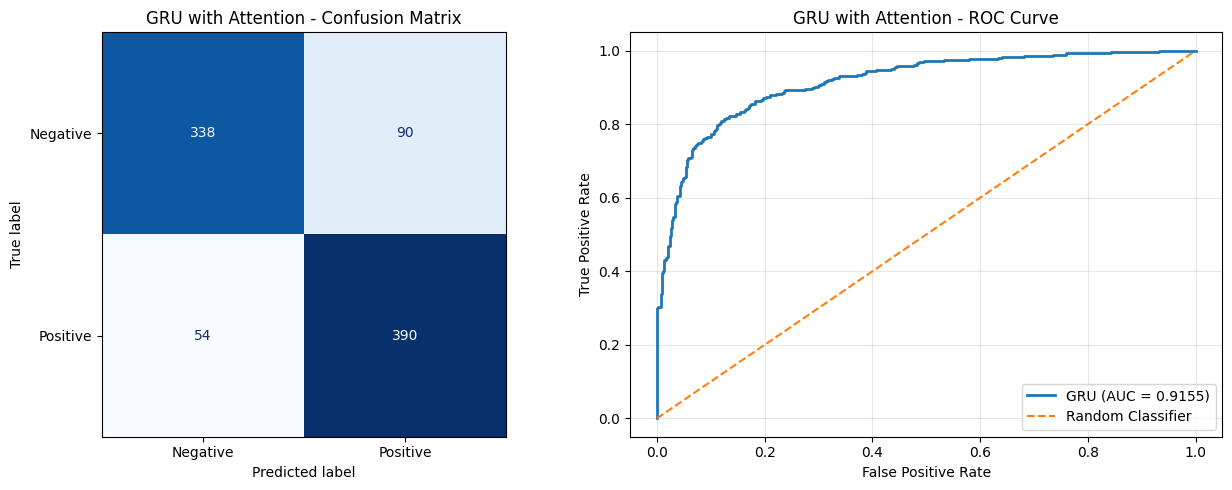

In [45]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix
cm = confusion_matrix(gru_true, gru_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    ax=axes[0],
    cmap="Blues",
    values_format="d",
    colorbar=False
)

axes[0].set_title("GRU with Attention - Confusion Matrix")

# ROC curve
fpr, tpr, _ = roc_curve(gru_true, gru_probs)

roc_auc = auc(fpr, tpr)

axes[1].plot(
    fpr, tpr,
    label=f"GRU (AUC = {roc_auc:.4f})",
    linewidth=2
)

axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("GRU with Attention - ROC Curve")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gru_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.7 Attention Weight Visualization

### Objective

We visualize the attention weights learned by our Bidirectional GRU to examine which words receive more attention during sentiment classification.

### How Are Attention Weights Calculated?

For every token, the GRU generates a contextual hidden state $\mathbf{h}_t$.

An attention scoring network calculates:

$$
e_t = \mathbf{v}^{T}\tanh(W_a\mathbf{h}_t+\mathbf{b}_a)
$$

The scores are normalized using softmax:

$$
\alpha_t = \frac{\exp(e_t)}{\sum_{j=1}^{T}\exp(e_j)}
$$

Where:

- $e_t$: Attention score for token $t$.
- $\alpha_t$: Normalized attention weight.
- $T$: Number of actual tokens.

The attention weights satisfy:

$$
\sum_{t=1}^{T}\alpha_t=1
$$

Padding positions receive zero attention.

### Interpretation

- Higher attention weights indicate that the token's hidden state contributes more strongly to the attention-weighted context vector.
- Lower attention weights indicate a smaller contribution to that aggregation.
- Attention weights are nonnegative and normalized.

### Why Visualize Attention?

1. Identify which words receive high attention.
2. Examine whether sentiment-related words receive high weights.
3. Compare attention rankings against LIME.
4. Investigate whether high-attention words affect predictions when removed.

### Limitation

High attention does not necessarily mean that removing a word will strongly affect the prediction.

Therefore, attention weights are treated as candidate explanations rather than guaranteed faithful feature importance.


In [46]:
import torch
import numpy as np
import pandas as pd

# Same validation sentence as previous explanations
sample_idx = 0

sentence = X_val.iloc[sample_idx]
true_label = int(y_val.iloc[sample_idx])

# Tokenize the sentence
tokens = tokenize(sentence)

# Encode and pad
ids, length = encode_and_pad(tokens)

# Convert to tensors
input_tensor = torch.tensor(
    [ids],
    dtype=torch.long,
    device=device
)

length_tensor = torch.tensor(
    [length],
    dtype=torch.long,
    device=device
)

# Evaluate GRU
gru_model.eval()

with torch.no_grad():

    logits, attention_weights = gru_model(
        input_tensor,
        length_tensor
    )

    probabilities = torch.softmax(logits, dim=1)

    prediction = probabilities.argmax(dim=1).item()

# Extract valid attention weights only
attention_scores = (
    attention_weights[0, :length]
    .cpu()
    .numpy()
)

# Create attention table
attention_df = pd.DataFrame({
    "Position": np.arange(length),
    "Word": tokens[:length],
    "Attention Weight": attention_scores
})

print("Sentence:", sentence)
print("Actual Label:", true_label)
print("Predicted Label:", prediction)

print(
    "Positive Probability:",
    round(probabilities[0, 1].item(), 4)
)

print(
    "Attention Sum:",
    round(attention_scores.sum(), 4)
)

display(
    attention_df.sort_values(
        "Attention Weight",
        ascending=False
    ).round(4)
)

Sentence: it 's a charming and often affecting journey .
Actual Label: 1
Predicted Label: 1
Positive Probability: 0.9999
Attention Sum: 1.0


,Position,Word,Attention Weight
7,7,journey,0.5126
6,6,affecting,0.3548
3,3,charming,0.0789
5,5,often,0.0218
0,0,it,0.0099
4,4,and,0.0083
2,2,a,0.0071
1,1,s,0.0065


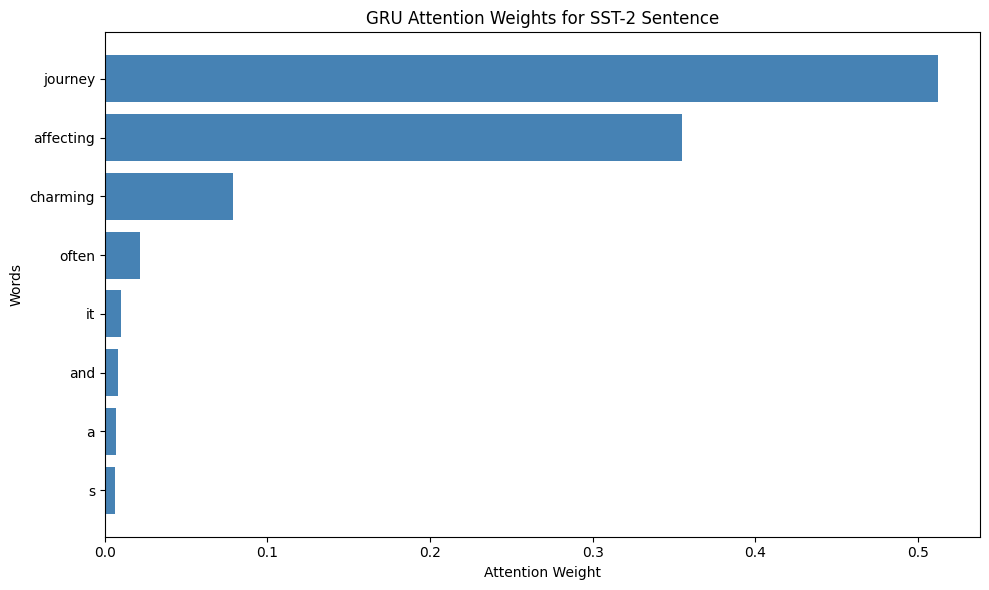

In [47]:
import matplotlib.pyplot as plt

plot_df = attention_df.sort_values(
    "Attention Weight",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Word"],
    plot_df["Attention Weight"],
    color="steelblue"
)

plt.xlabel("Attention Weight")
plt.ylabel("Words")
plt.title("GRU Attention Weights for SST-2 Sentence")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gru_attention_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.8 LIME Explanations for GRU with Attention

### Objective

We apply LIME to our trained Bidirectional GRU with Attention to identify important words influencing individual sentiment predictions.

### Methodology

1. Select a validation sentence.
2. Generate perturbed sentences by removing words.
3. Obtain sentiment probabilities from the trained GRU.
4. Fit a local interpretable surrogate model using LIME.
5. Extract word-level importance scores.
6. Compare LIME explanations against GRU attention weights.

### Why Compare Attention and LIME?

Attention and LIME produce explanations using different approaches.

- **Attention:** Assigns weights to contextual GRU hidden states during prediction.
- **LIME:** Estimates the effects of word perturbations using a local surrogate model.

We investigate whether words receiving high attention are also important according to LIME.

### Evaluation

We initially generate an explanation for one validation sentence to verify the implementation.

Subsequently, both methods will be evaluated on the same fixed 200 SST-2 validation examples.

We will measure:

- Top-3 and Top-5 overlap.
- Spearman rank correlation.
- Word-deletion faithfulness.
- Comparison with random deletion.

### Limitation

Attention weights are nonnegative and normalized, while LIME produces signed attribution scores.

We will compare word rankings using absolute LIME attribution values and attention weights, rather than comparing their numerical magnitudes directly.

We will also align tokenization and account for repeated words before calculating aggregate agreement metrics.


In [48]:
from lime.lime_text import LimeTextExplainer
import torch
import numpy as np

# Ensure the trained GRU is in evaluation mode
gru_model.eval()

def predict_proba_gru(texts):

    all_probs = []

    # Process perturbations in batches
    batch_size = 128

    for start in range(0, len(texts), batch_size):

        batch_texts = texts[start:start + batch_size]

        # Tokenize and encode
        encoded = [
            encode_and_pad(tokenize(text))
            for text in batch_texts
        ]

        ids, lengths = zip(*encoded)

        # Convert to tensors
        input_ids = torch.tensor(
            ids, dtype=torch.long, device=device
        )

        seq_lengths = torch.tensor(
            lengths, dtype=torch.long, device=device
        )

        # Predict
        with torch.no_grad():

            logits, _ = gru_model(
                input_ids, seq_lengths
            )

            probs = torch.softmax(
                logits, dim=1
            )

        all_probs.append(probs.cpu().numpy())

    return np.vstack(all_probs)


print("GRU prediction function created!")

GRU prediction function created!


In [49]:
# Initialize LIME
gru_lime_explainer = LimeTextExplainer(
    class_names=["Negative", "Positive"],
    random_state=42
)

# Same validation sentence
sample_idx = 0

sentence = X_val.iloc[sample_idx]

# Get GRU prediction
original_probs = predict_proba_gru([sentence])[0]

predicted_class = int(np.argmax(original_probs))

print("Sentence:", sentence)
print("Predicted class:", predicted_class)
print("Positive probability:", round(original_probs[1], 4))

# Generate LIME explanation
gru_lime_exp = gru_lime_explainer.explain_instance(
    sentence,
    predict_proba_gru,
    labels=(predicted_class,),
    num_features=20,
    num_samples=1000
)

print("\nLIME word importance:")

for word, weight in gru_lime_exp.as_list(
    label=predicted_class
):
    print(f"{word}: {weight:.4f}")

print(
    "\nLIME Local R-squared:",
    round(gru_lime_exp.score, 4)
)

Sentence: it 's a charming and often affecting journey .
Predicted class: 1
Positive probability: 0.9999

LIME word importance:
charming: 0.0170
affecting: 0.0169
often: 0.0080
journey: 0.0060
and: 0.0058
it: 0.0056
a: 0.0039
s: -0.0022

LIME Local R-squared: 0.2427


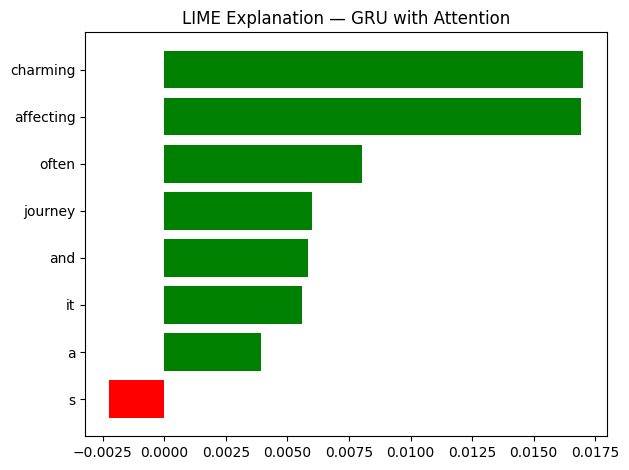

In [50]:
import matplotlib.pyplot as plt

fig = gru_lime_exp.as_pyplot_figure(
    label=predicted_class
)

plt.title("LIME Explanation — GRU with Attention")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/gru_lime_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.9 GRU Attention vs LIME — Evaluation on 200 Examples

### Objective

We investigate whether attention weights from our trained Bidirectional GRU agree with word-importance scores generated by LIME.

### Evaluation Setup

| Parameter | Value |
|---|---|
| Dataset | SST-2 |
| Evaluation examples | 200 |
| Positive examples | 100 |
| Negative examples | 100 |
| Classifier | Bidirectional GRU with Attention |
| Explanation methods | Attention and LIME |
| LIME perturbation samples | 1,000 per sentence |

### Methodology

1. Use the same 200 validation sentences selected for the Logistic Regression experiments.
2. Generate GRU attention weights for each sentence.
3. Generate LIME explanations using the same GRU classifier.
4. Apply consistent word tokenization.
5. Aggregate repeated-token attention weights into word-level scores.
6. Save both explanations and LIME local R-squared values.
7. Compare word rankings using Top-k overlap and Spearman correlation.

### Fair Comparison

Attention weights and LIME values have different interpretations and numerical scales.

Therefore, we compare rankings rather than raw attribution magnitudes.

We also record LIME local R-squared to examine whether explanation agreement depends on the quality of the local surrogate approximation.

### Justification

Using identical evaluation examples and consistent word alignment allows us to perform a more reliable comparison than our preliminary experiments using only 20 examples.

High attention–LIME agreement does not necessarily imply explanation faithfulness. We will test faithfulness separately using word deletion.


In [51]:
# Original validation sentence
sample_idx = 0
original_sentence = X_val.iloc[sample_idx]

# Standardize using our GRU tokenizer
standardized_sentence = " ".join(
    tokenize(original_sentence)
)

print("Original:")
print(original_sentence)

print("\nStandardized:")
print(standardized_sentence)

# Compare GRU probabilities
p_original = predict_proba_gru(
    [original_sentence]
)[0]

p_standardized = predict_proba_gru(
    [standardized_sentence]
)[0]

print("\nOriginal probabilities:", p_original)
print("Standardized probabilities:", p_standardized)

print(
    "Predictions match:",
    np.allclose(p_original, p_standardized)
)

Original:
it 's a charming and often affecting journey .

Standardized:
it s a charming and often affecting journey

Original probabilities: [1.2784582e-04 9.9987209e-01]
Standardized probabilities: [1.2784582e-04 9.9987209e-01]
Predictions match: True


In [52]:
import numpy as np
import pandas as pd
import torch
from lime.lime_text import LimeTextExplainer
from tqdm.auto import tqdm

# Same 200 examples used for Logistic Regression
eval_indices = eval_df.index.to_numpy()

assert len(eval_indices) == 200

gru_model.eval()

# Initialize LIME with whitespace-based tokenization
gru_lime_explainer = LimeTextExplainer(
    class_names=["Negative", "Positive"],
    random_state=42,
    bow=True,
    split_expression=r"\s+"
)

gru_explanations = []

for idx in tqdm(eval_indices, desc="GRU Explanations"):

    original_sentence = X_val.iloc[idx]
    tokens = tokenize(original_sentence)

    if len(tokens) == 0:
        continue

    # Standardized sentence for LIME
    sentence = " ".join(tokens)

    # Encode sentence
    ids, length = encode_and_pad(tokens)

    input_ids = torch.tensor(
        [ids],
        dtype=torch.long,
        device=device
    )

    lengths = torch.tensor(
        [length],
        dtype=torch.long,
        device=device
    )

    # ========== GRU ATTENTION ==========
    with torch.no_grad():

        logits, attention = gru_model(
            input_ids,
            lengths
        )

        probs = torch.softmax(logits, dim=1)

    predicted_class = int(
        probs.argmax(dim=1).item()
    )

    # Attention over valid tokens
    attention_values = (
        attention[0, :length]
        .cpu()
        .numpy()
    )

    # Aggregate attention for repeated word types
    attention_scores = {}

    for word, weight in zip(
        tokens[:length],
        attention_values
    ):
        attention_scores[word] = (
            attention_scores.get(word, 0.0)
            + float(weight)
        )

    # ========== LIME ==========
    lime_exp = gru_lime_explainer.explain_instance(
        sentence,
        predict_proba_gru,
        labels=(predicted_class,),
        num_features=len(set(tokens)),
        num_samples=1000
    )

    lime_scores = {
        word.lower(): float(weight)
        for word, weight in lime_exp.as_list(
            label=predicted_class
        )
    }

    # Save explanations
    gru_explanations.append({
        "validation_index": int(idx),
        "sentence": original_sentence,
        "tokens": tokens,
        "true_label": int(y_val.iloc[idx]),
        "predicted_class": predicted_class,
        "positive_probability": float(probs[0, 1]),
        "attention_scores": attention_scores,
        "lime_scores": lime_scores,
        "lime_r2": float(lime_exp.score)
    })

print("Total explanations:", len(gru_explanations))

# Save complete explanations
pd.to_pickle(
    gru_explanations,
    "/kaggle/working/gru_explanations_200.pkl"
)

print("GRU explanations saved!")

GRU Explanations:   0%|          | 0/200 [00:00<?, ?it/s]

Total explanations: 200
GRU explanations saved!


In [53]:
# Collect LIME R-squared values
gru_lime_r2 = np.array([
    item["lime_r2"]
    for item in gru_explanations
])

print("GRU + LIME Evaluation Summary")
print("-----------------------------")

print("Total examples:", len(gru_explanations))
print("Mean R-squared:", round(gru_lime_r2.mean(), 4))
print("Median R-squared:", round(np.median(gru_lime_r2), 4))
print("Minimum R-squared:", round(gru_lime_r2.min(), 4))
print("Maximum R-squared:", round(gru_lime_r2.max(), 4))

print(
    "Examples with R² < 0.5:",
    np.sum(gru_lime_r2 < 0.5)
)

GRU + LIME Evaluation Summary
-----------------------------
Total examples: 200
Mean R-squared: 0.6315
Median R-squared: 0.6843
Minimum R-squared: 0.0969
Maximum R-squared: 0.9981
Examples with R² < 0.5: 54



## 2.10 GRU Attention vs LIME — Explanation Agreement

### Objective

We investigate whether attention weights from our trained Bidirectional GRU identify the same important words as LIME explanations.

### Evaluation Setup

- Dataset: SST-2 validation set.
- Selected examples: 200 (100 positive and 100 negative).
- Classifier: Bidirectional GRU with Attention.
- Explanation methods: Attention and LIME.
- Ranking criterion: Attention weight and absolute LIME attribution.

### Evaluation Metrics

**1. Top-k Overlap**

$$
\mathrm{Overlap@k}(A,B)=\frac{|A_k\cap B_k|}{k}
$$

We calculate overlap for k = 3 and k = 5.

**2. Spearman Rank Correlation**

$$
\rho_s=\mathrm{corr}(R_A,R_B)
$$

This measures agreement between the complete word rankings.

### Word Alignment

Both methods are compared using the same unique words from each tokenized sentence.

Repeated occurrences of the same word have their attention weights summed to obtain word-type importance scores, matching LIME's bag-of-words representation.

We check that every word has a corresponding LIME attribution rather than silently assigning missing scores to zero.

### Evaluation Constraints

- Top-3 requires at least 6 unique words.
- Top-5 requires at least 10 unique words.
- Spearman requires at least 3 unique words and nonconstant rankings.
- We report the actual number of eligible examples for each metric.

### Justification

This evaluation directly addresses our research question: Do attention-based explanations and perturbation-based explanations highlight the same important words?

We also retain LIME local R-squared values to examine whether lower surrogate-model fit is associated with explanation disagreement.


In [54]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

def top_k_overlap(words, scores_a, scores_b, k):

    n = len(words)

    # Avoid inflated overlap for short sentences
    if n < 2 * k:
        return np.nan

    # Sort by absolute importance, breaking ties by word
    order_a = sorted(
        range(n),
        key=lambda i: (-abs(scores_a[i]), words[i])
    )

    order_b = sorted(
        range(n),
        key=lambda i: (-abs(scores_b[i]), words[i])
    )

    top_a = {words[i] for i in order_a[:k]}
    top_b = {words[i] for i in order_b[:k]}

    return len(top_a & top_b) / k


def rank_correlation(scores_a, scores_b):

    if len(scores_a) < 3:
        return np.nan

    ranks_a = pd.Series(np.abs(scores_a)).rank(
        ascending=False, method="average"
    )

    ranks_b = pd.Series(np.abs(scores_b)).rank(
        ascending=False, method="average"
    )

    if ranks_a.nunique() < 2 or ranks_b.nunique() < 2:
        return np.nan

    return spearmanr(ranks_a, ranks_b).statistic


agreement_records = []
missing_records = []

for item in gru_explanations:

    # Unique words, preserving first-occurrence order
    words = list(dict.fromkeys(
        item["tokens"][:MAX_LEN]
    ))

    attention_dict = item["attention_scores"]
    lime_dict = item["lime_scores"]

    # Audit missing word alignments
    missing = [
        word for word in words
        if word not in attention_dict or word not in lime_dict
    ]

    if missing:
        missing_records.append({
            "validation_index": item["validation_index"],
            "missing_words": missing
        })
        continue

    attention_scores = np.array([
        attention_dict[w] for w in words
    ])

    lime_scores = np.array([
        lime_dict[w] for w in words
    ])

    # Calculate agreement
    top3 = top_k_overlap(
        words, attention_scores, lime_scores, k=3
    )

    top5 = top_k_overlap(
        words, attention_scores, lime_scores, k=5
    )

    rho = rank_correlation(
        attention_scores, lime_scores
    )

    agreement_records.append({
        "validation_index": item["validation_index"],
        "N_Words": len(words),
        "Top3": top3,
        "Top5": top5,
        "Spearman": rho,
        "LIME_R2": item["lime_r2"],
        "Predicted_Class": item["predicted_class"]
    })


gru_agreement_df = pd.DataFrame(agreement_records)

print("Selected examples:", len(gru_explanations))
print("Aligned examples:", len(gru_agreement_df))
print("Examples with missing matches:", len(missing_records))

if missing_records:
    print("First missing-match example:", missing_records[0])

print("\nAgreement Summary:")

gru_agreement_summary = pd.DataFrame({
    "Metric": [
        "Top-3 Overlap",
        "Top-5 Overlap",
        "Spearman Correlation"
    ],
    "Mean": [
        gru_agreement_df["Top3"].mean(),
        gru_agreement_df["Top5"].mean(),
        gru_agreement_df["Spearman"].mean()
    ],
    "N": [
        gru_agreement_df["Top3"].count(),
        gru_agreement_df["Top5"].count(),
        gru_agreement_df["Spearman"].count()
    ]
})

display(gru_agreement_summary.round(4))

# Save results
gru_agreement_df.to_csv(
    "/kaggle/working/gru_lime_agreement_200.csv",
    index=False
)

gru_agreement_summary.to_csv(
    "/kaggle/working/gru_lime_agreement_summary.csv",
    index=False
)

Selected examples: 200
Aligned examples: 200
Examples with missing matches: 0

Agreement Summary:


,Metric,Mean,N
0,Top-3 Overlap,0.5330,187
1,Top-5 Overlap,0.5539,165
2,Spearman Correlation,0.4187,199


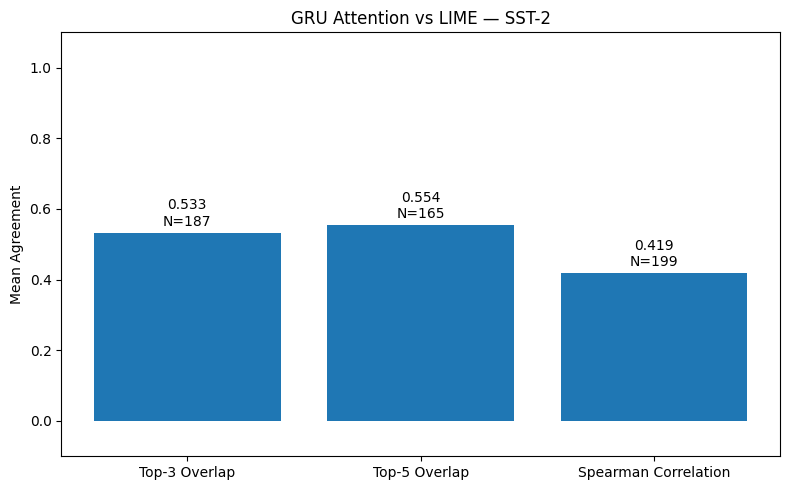

In [55]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

metrics = gru_agreement_summary["Metric"]
values = gru_agreement_summary["Mean"]

bars = ax.bar(metrics, values)

for bar, value, n in zip(
    bars,
    values,
    gru_agreement_summary["N"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}\nN={n}",
        ha="center"
    )

ax.set_ylabel("Mean Agreement")
ax.set_title("GRU Attention vs LIME — SST-2")
ax.set_ylim(-0.1, 1.1)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gru_lime_agreement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.11 Relationship Between LIME Local Fit and Explanation Agreement

### Objective

We investigate whether the quality of LIME's local approximation is associated with its agreement with GRU attention weights.

### Motivation

LIME fits a simple surrogate model around an individual prediction.

However, the GRU is a nonlinear neural classifier, and a linear surrogate may not approximate its prediction behavior equally well for every sentence.

Our previous experiments showed that 54 out of 200 examples had LIME local R-squared below 0.5.

### Methodology

We divide evaluation examples into two groups:

1. **Low local fit:** LIME R-squared < 0.5.
2. **Higher local fit:** LIME R-squared >= 0.5.

For each group, we calculate:

- Mean Top-3 overlap.
- Mean Top-5 overlap.
- Mean Spearman rank correlation.
- Number of eligible examples for each metric.

### Research Question

Does stronger LIME local surrogate fit correspond to greater agreement between attention weights and LIME word rankings?

### Justification

This analysis helps distinguish disagreement between explanation methods from potential limitations in LIME's local approximation.

However, correlation between local fit and explanation agreement does not establish causation.

The threshold of 0.5 is used for exploratory analysis rather than as a universal standard for explanation reliability.


In [56]:
import pandas as pd
import numpy as np

# Create LIME local fit groups
gru_agreement_df["R2_Group"] = np.where(
    gru_agreement_df["LIME_R2"] < 0.5,
    "Low R2 (<0.5)",
    "Higher R2 (>=0.5)"
)

# Calculate agreement for both groups
r2_agreement_summary = (
    gru_agreement_df
    .groupby("R2_Group")
    .agg(
        Total_Examples=("validation_index", "count"),

        Mean_R2=("LIME_R2", "mean"),

        Top3_Mean=("Top3", "mean"),
        Top3_N=("Top3", "count"),

        Top5_Mean=("Top5", "mean"),
        Top5_N=("Top5", "count"),

        Spearman_Mean=("Spearman", "mean"),
        Spearman_N=("Spearman", "count")
    )
    .reset_index()
)

display(r2_agreement_summary.round(4))

# Save results
r2_agreement_summary.to_csv(
    "/kaggle/working/gru_r2_agreement.csv",
    index=False
)

,R2_Group,Total_Examples,Mean_R2,Top3_Mean,Top3_N,Top5_Mean,Top5_N,Spearman_Mean,Spearman_N
0,Higher R2 (>=0.5),146,0.7376,0.5231,137,0.5475,122,0.4114,145
1,Low R2 (<0.5),54,0.3445,0.5600,50,0.5721,43,0.4383,54


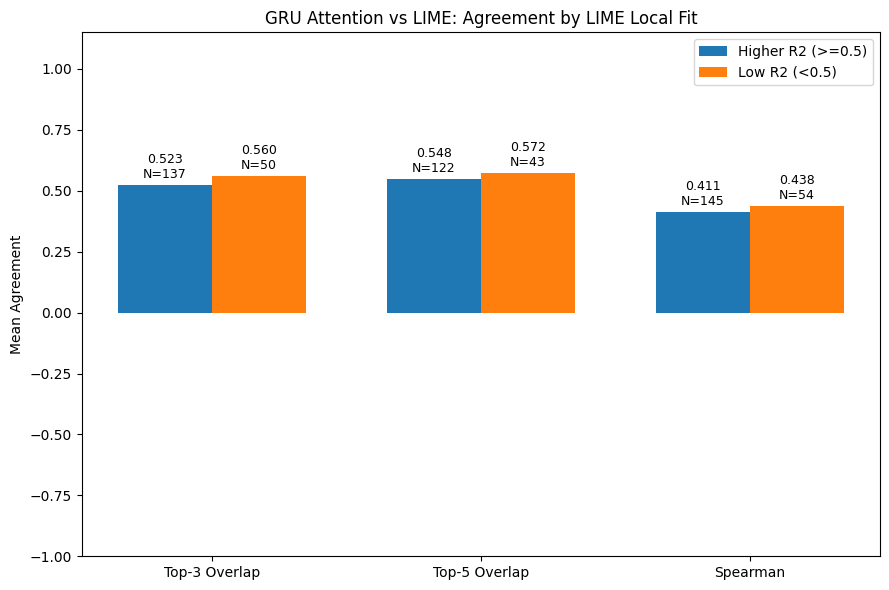

In [57]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Top3", "Top5", "Spearman"]

group_means = (
    gru_agreement_df
    .groupby("R2_Group")[metrics]
    .mean()
)

group_counts = (
    gru_agreement_df
    .groupby("R2_Group")[metrics]
    .count()
)

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

for i, group in enumerate(group_means.index):

    values = group_means.loc[group].values
    counts = group_counts.loc[group].values

    positions = x + (i - 0.5) * width

    bars = ax.bar(
        positions,
        values,
        width,
        label=group
    )

    for bar, value, n in zip(bars, values, counts):

        ax.annotate(
            f"{value:.3f}\nN={n}",
            (bar.get_x() + bar.get_width()/2,
             bar.get_height()),
            textcoords="offset points",
            xytext=(0, 5),
            ha="center",
            fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels([
    "Top-3 Overlap",
    "Top-5 Overlap",
    "Spearman"
])

ax.set_ylabel("Mean Agreement")
ax.set_title(
    "GRU Attention vs LIME: Agreement by LIME Local Fit"
)

ax.set_ylim(-1, 1.15)
ax.legend()

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gru_r2_vs_agreement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.12 GRU Faithfulness Evaluation Using Word Deletion

### Objective

We evaluate whether words highlighted by GRU attention and LIME meaningfully influence the trained model's predictions.

### Evaluation Setup

- Dataset: SST-2 validation set.
- Initial evaluation sample: 200 sentences.
- Classifier: Trained Bidirectional GRU with Attention.
- Explanation methods: Attention and LIME.
- Baseline: Random word deletion.
- Deletion levels: Top-1, Top-3, and Top-5 words.
- Random trials: 20 per sentence and deletion level.

### Methodology

1. Select sentences containing at least 10 unique words.
2. Rank words using attention weights and absolute LIME attribution values.
3. Delete the top-k selected words.
4. Obtain the GRU prediction after deletion.
5. Calculate the signed probability drop and absolute probability change.
6. Repeat using random word selection.
7. Compare methods on the same eligible sentences.

### Signed Probability Drop

$$
\boxed{
\Delta_k=P(\hat{y}\mid x)-P(\hat{y}\mid x_{\setminus S_k})
}
$$

A positive value indicates reduced confidence in the original predicted class.

### Absolute Probability Change

$$
\boxed{
A_k=\left|P(\hat{y}\mid x)-P(\hat{y}\mid x_{\setminus S_k})\right|
}
$$

This measures prediction sensitivity regardless of the direction of change.

### Fair Comparison

All methods use identical sentences and deletion levels.

We delete word types rather than individual token occurrences. When a selected word occurs more than once, all occurrences are removed.

Random deletion uses the same word-type selection unit and is repeated 20 times.

### Statistical Reliability

We report mean results and 95% bootstrap confidence intervals using sentence-level resampling.

### Limitations

Deleting words may produce unnatural sentences. Attention weights are also unsigned, while LIME can identify both supporting and opposing evidence. Therefore, deletion results measure model sensitivity rather than definitive causal explanation faithfulness.


In [58]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

rng = np.random.default_rng(42)

methods = ["Attention", "LIME"]
k_values = [1, 3, 5]
random_trials = 20

# Same eligible sentence set for all deletion levels
eligible_items = [
    item for item in gru_explanations
    if len(set(item["tokens"][:MAX_LEN])) >= 10
]

print("Selected examples:", len(gru_explanations))
print("Eligible for deletion:", len(eligible_items))

# Standardize sentences using GRU tokenization
original_texts = [
    " ".join(item["tokens"][:MAX_LEN])
    for item in eligible_items
]

# Predict original probabilities
original_probs = predict_proba_gru(original_texts)

# Remove all occurrences of selected word types
def delete_word_types(tokens, selected_words):
    selected = set(selected_words)
    return " ".join(
        word for word in tokens
        if word not in selected
    )

modified_texts = []
records = []

for pos, item in enumerate(tqdm(
    eligible_items,
    desc="Preparing GRU deletion tests"
)):
    tokens = item["tokens"][:MAX_LEN]
    words = sorted(set(tokens))

    original_class = int(
        np.argmax(original_probs[pos])
    )

    assert original_class == item["predicted_class"]

    score_dicts = {
        "Attention": item["attention_scores"],
        "LIME": item["lime_scores"]
    }

    for k in k_values:

        # Explanation-based deletions
        for method in methods:
            scores = score_dicts[method]

            ranked_words = sorted(
                words,
                key=lambda w: (-abs(scores[w]), w)
            )

            selected_words = ranked_words[:k]

            modified_texts.append(
                delete_word_types(tokens, selected_words)
            )

            records.append({
                "index": item["validation_index"],
                "position": pos,
                "Method": method,
                "k": k,
                "Trial": 0,
                "Original_Class": original_class
            })

        # Random deletion baseline
        for trial in range(random_trials):
            selected_words = rng.choice(
                words,
                size=k,
                replace=False
            )

            modified_texts.append(
                delete_word_types(tokens, selected_words)
            )

            records.append({
                "index": item["validation_index"],
                "position": pos,
                "Method": "Random",
                "k": k,
                "Trial": trial,
                "Original_Class": original_class
            })

# Predict all modified sentences
modified_probs = predict_proba_gru(modified_texts)

# Calculate probability changes
for i, record in enumerate(records):
    pos = record["position"]
    cls = record["Original_Class"]

    p_before = original_probs[pos, cls]
    p_after = modified_probs[i, cls]

    record["Signed_Drop"] = float(
        p_before - p_after
    )

    record["Absolute_Change"] = float(
        abs(p_before - p_after)
    )

gru_deletion_df = pd.DataFrame(records)

# Average random trials within each sentence
gru_sentence_deletion = (
    gru_deletion_df
    .groupby(["index", "Method", "k"], as_index=False)
    .agg(
        Signed_Drop=("Signed_Drop", "mean"),
        Absolute_Change=("Absolute_Change", "mean")
    )
)

print("GRU deletion experiments completed!")

Selected examples: 200
Eligible for deletion: 165


Preparing GRU deletion tests:   0%|          | 0/165 [00:00<?, ?it/s]

GRU deletion experiments completed!


In [59]:
rng_ci = np.random.default_rng(42)

summary = []

for (method, k), group in gru_sentence_deletion.groupby(
    ["Method", "k"]
):
    values = group["Signed_Drop"].to_numpy()

    bootstrap_means = rng_ci.choice(
        values,
        size=(2000, len(values)),
        replace=True
    ).mean(axis=1)

    ci_low, ci_high = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    summary.append({
        "Method": method,
        "k": k,
        "N": len(values),
        "Mean Signed Drop": values.mean(),
        "Mean Absolute Change":
            group["Absolute_Change"].mean(),
        "CI Lower": ci_low,
        "CI Upper": ci_high
    })

gru_faithfulness_summary = pd.DataFrame(summary)

display(
    gru_faithfulness_summary
    .sort_values(["k", "Method"])
    .round(4)
)

# Save results
gru_deletion_df.to_csv(
    "/kaggle/working/gru_deletion_results.csv",
    index=False
)

gru_faithfulness_summary.to_csv(
    "/kaggle/working/gru_faithfulness_summary.csv",
    index=False
)

,Method,k,N,Mean Signed Drop,Mean Absolute Change,CI Lower,CI Upper
0,Attention,1,165,0.1540,0.2117,0.1084,0.2039
3,LIME,1,165,0.2320,0.2723,0.1892,0.2788
6,Random,1,165,0.0261,0.0648,0.0198,0.0328
1,Attention,3,165,0.2353,0.2872,0.1867,0.2911
4,LIME,3,165,0.2913,0.3339,0.2398,0.3395
7,Random,3,165,0.0657,0.1236,0.0538,0.0780
2,Attention,5,165,0.2852,0.3212,0.2358,0.3355
5,LIME,5,165,0.3395,0.3808,0.2843,0.3927
8,Random,5,165,0.1006,0.1674,0.0829,0.1202


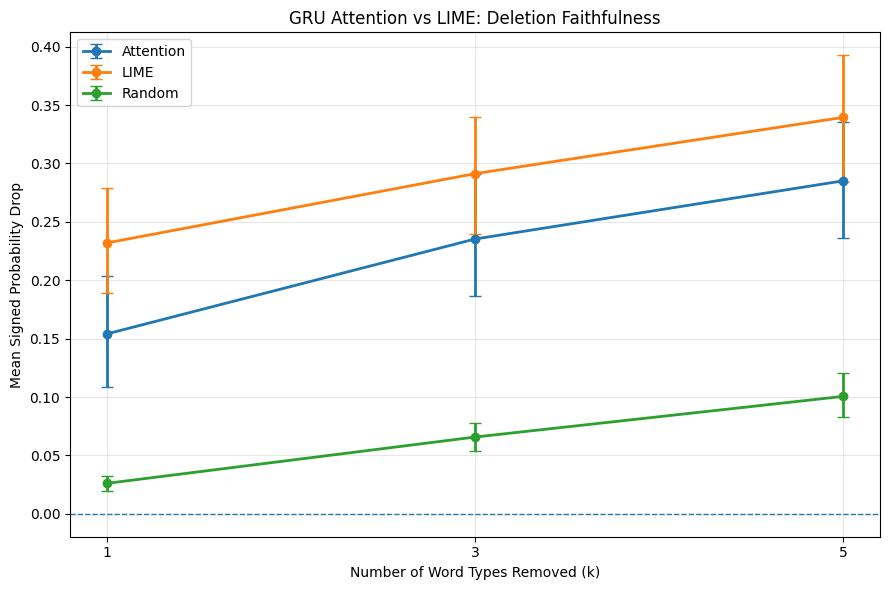

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for method in ["Attention", "LIME", "Random"]:

    subset = (
        gru_faithfulness_summary[
            gru_faithfulness_summary["Method"] == method
        ]
        .sort_values("k")
    )

    y = subset["Mean Signed Drop"].to_numpy()

    lower_error = y - subset["CI Lower"].to_numpy()
    upper_error = subset["CI Upper"].to_numpy() - y

    plt.errorbar(
        subset["k"],
        y,
        yerr=[lower_error, upper_error],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method
    )

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Number of Word Types Removed (k)")
plt.ylabel("Mean Signed Probability Drop")
plt.title(
    "GRU Attention vs LIME: Deletion Faithfulness"
)

plt.xticks([1, 3, 5])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/gru_deletion_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 2.13 Paired Bootstrap Comparison of Faithfulness

### Objective

We test whether the observed differences in word-deletion faithfulness between LIME, attention, and random deletion are reliably different from zero.

### Methodology

We use paired bootstrap resampling because all explanation methods were evaluated on the same sentences.

For each sentence, we calculate the difference between two methods:

$$
d_i=\Delta_i^{(A)}-\Delta_i^{(B)}
$$

The mean difference is:

$$
\overline{d}=\frac{1}{N}\sum_{i=1}^{N}d_i
$$

We resample sentences with replacement 5,000 times and calculate a 95% bootstrap confidence interval for the mean difference.

### Comparisons

1. LIME vs Attention
2. LIME vs Random
3. Attention vs Random

### Interpretation

- Positive mean difference: Method A produces a larger average signed probability drop than Method B.
- Confidence interval entirely above zero: Evidence that Method A has a higher mean drop under this evaluation.
- Confidence interval containing zero: The observed difference is not clearly established by this interval.

### Justification

Paired comparisons account for the fact that methods are evaluated on the same sentences.

This provides a more appropriate statistical comparison than inspecting overlapping confidence intervals for the individual method means.


In [61]:
import numpy as np
import pandas as pd

# Arrange results so methods are compared on the same sentences
paired_df = gru_sentence_deletion.pivot_table(
    index=["index", "k"],
    columns="Method",
    values="Signed_Drop"
)

comparisons = [
    ("LIME", "Attention"),
    ("LIME", "Random"),
    ("Attention", "Random")
]

rng = np.random.default_rng(42)

bootstrap_results = []

for k in [1, 3, 5]:

    subset = paired_df.xs(k, level="k")

    for method_a, method_b in comparisons:

        paired = subset[
            [method_a, method_b]
        ].dropna()

        differences = (
            paired[method_a] - paired[method_b]
        ).to_numpy()

        n = len(differences)

        # Paired bootstrap: resample sentence differences
        sample_indices = rng.integers(
            0, n,
            size=(5000, n)
        )

        boot_means = differences[
            sample_indices
        ].mean(axis=1)

        ci_low, ci_high = np.percentile(
            boot_means, [2.5, 97.5]
        )

        bootstrap_results.append({
            "k": k,
            "Comparison": f"{method_a} - {method_b}",
            "N": n,
            "Mean Difference": differences.mean(),
            "CI Lower": ci_low,
            "CI Upper": ci_high,
            "CI Excludes Zero": (
                ci_low > 0 or ci_high < 0
            )
        })

paired_bootstrap_df = pd.DataFrame(
    bootstrap_results
)

display(paired_bootstrap_df.round(4))

# Save for final report
paired_bootstrap_df.to_csv(
    "/kaggle/working/gru_paired_bootstrap.csv",
    index=False
)

,k,Comparison,N,Mean Difference,CI Lower,CI Upper,CI Excludes Zero
0,1,LIME - Attention,165,0.0779,0.0391,0.1168,True
1,1,LIME - Random,165,0.2059,0.1633,0.2503,True
2,1,Attention - Random,165,0.1280,0.0853,0.1700,True
3,3,LIME - Attention,165,0.0560,0.0052,0.1081,True
4,3,LIME - Random,165,0.2256,0.1750,0.2764,True
5,3,Attention - Random,165,0.1696,0.1212,0.2184,True
6,5,LIME - Attention,165,0.0543,0.0099,0.1018,True
7,5,LIME - Random,165,0.2389,0.1880,0.2869,True
8,5,Attention - Random,165,0.1846,0.1410,0.2292,True



## 3.1 BERT for SST-2 Sentiment Classification

### Objective

We extend our study to BERT (Bidirectional Encoder Representations from Transformers), a pretrained transformer-based language model.

Unlike Logistic Regression and GRU trained with randomly initialized embeddings, BERT starts with language representations learned during large-scale pretraining.

### Why Use BERT?

1. **Contextual Representations:** A word's representation depends on surrounding words.
2. **Bidirectional Context:** BERT considers words on both sides of a token.
3. **Self-Attention:** Transformer attention allows tokens to interact across the sentence.
4. **Transfer Learning:** Pretrained representations can be fine-tuned for sentiment classification.
5. **Explainability:** We can compare attention-derived word scores with LIME and examine their faithfulness.

### Selected Model

We use `google-bert/bert-base-uncased`.

- Transformer layers: 12
- Attention heads per layer: 12
- Hidden dimension: 768
- Task: Binary sentiment classification

### Tokenization

BERT uses WordPiece subword tokenization.

It also introduces special tokens:

- `[CLS]`: Classification token.
- `[SEP]`: Marks the end of the input sequence.
- `[PAD]`: Padding token.

### Justification

BERT provides a contextual transformer classifier for investigating whether attention-based explanations agree with perturbation-based explanations.

For a fair evaluation, we retain the same SST-2 validation set and fixed explanation-evaluation sentence IDs.

We will aggregate BERT subword attributions into whole-word scores before comparing explanation methods.


In [62]:
# Install only if transformers is unavailable
%pip install -q transformers

Note: you may need to restart the kernel to use updated packages.


In [69]:
import transformers
import torch
from transformers import AutoTokenizer

print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

MODEL_NAME = "google-bert/bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sentence = X_val.iloc[0]

encoded = bert_tokenizer(sentence)

print("Sentence:", sentence)
print("BERT tokens:", bert_tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

Transformers version: 5.20.2
GPU available: True
Sentence: it 's a charming and often affecting journey .
BERT tokens: ['[CLS]', 'it', "'", 's', 'a', 'charming', 'and', 'often', 'affecting', 'journey', '.', '[SEP]']



## 3.2 BERT Tokenization and Dataset Preparation

### Objective

We prepare the SST-2 dataset for BERT fine-tuning using its pretrained WordPiece tokenizer.

### WordPiece Tokenization

Unlike our GRU tokenizer, BERT may split uncommon words into smaller subword units.

Special tokens are added:

- `[CLS]`: Represents the sequence for classification.
- `[SEP]`: Marks the end of the sentence.
- `[PAD]`: Used when padding sequences.

### Attention Mask

BERT uses an attention mask to distinguish real tokens from padding:

- 1: Real token.
- 0: Padding token.

### Maximum Sequence Length

We initially consider a maximum length of 128 WordPiece tokens, including special tokens.

Before selecting this value, we examine the actual training and validation sequence-length distributions and measure the truncation rate.

### Data Splitting

We use the same 90% training and 10% development split as our GRU experiment.

The official 872 SST-2 validation examples remain separate for final evaluation.

### Justification

This approach preserves a consistent evaluation procedure across Logistic Regression, GRU, and BERT while accounting for differences in their tokenization methods.


In [70]:
from transformers import AutoTokenizer
import numpy as np

MODEL_NAME = "google-bert/bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

sentence = X_val.iloc[0]

encoded = bert_tokenizer(sentence)

tokens = bert_tokenizer.convert_ids_to_tokens(
    encoded["input_ids"]
)

print("Original sentence:", sentence)
print("\nBERT tokens:", tokens)
print("\nToken IDs:", encoded["input_ids"])
print("\nNumber of tokens:", len(tokens))
print("Tokenizer is fast:", bert_tokenizer.is_fast)

Original sentence: it 's a charming and often affecting journey .

BERT tokens: ['[CLS]', 'it', "'", 's', 'a', 'charming', 'and', 'often', 'affecting', 'journey', '.', '[SEP]']

Token IDs: [101, 2009, 1005, 1055, 1037, 11951, 1998, 2411, 12473, 4990, 1012, 102]

Number of tokens: 12
Tokenizer is fast: True


In [68]:
import requests

try:
    response = requests.get("https://huggingface.co", timeout=10)
    print("Status:", response.status_code)
except Exception as e:
    print("Error:", e)

Status: 200



## 3.2 BERT Sequence Length Analysis

### Objective

We analyze the number of WordPiece tokens in SST-2 sentences to select an appropriate maximum sequence length for BERT.

### Methodology

We calculate:

1. Minimum token length.
2. Maximum token length.
3. Mean and median token lengths.
4. 95th and 99th percentile lengths.
5. Training and validation truncation rates.

### Why Is Sequence Length Important?

BERT processes sentences as token sequences. Shorter maximum lengths reduce computational costs, while excessively short lengths may remove important sentiment information.

Unlike our GRU tokenizer, BERT uses WordPiece tokenization and includes special tokens such as `[CLS]` and `[SEP]`.

### Justification

We select the maximum sequence length using the observed token-length distribution rather than choosing an arbitrary value.

This helps preserve sentiment information while keeping training efficient.


In [71]:
import numpy as np

# Tokenize training sentences
bert_train_encoded = bert_tokenizer(
    X_train.astype(str).tolist(),
    padding=False,
    truncation=False,
    return_attention_mask=False
)

# Tokenize validation sentences
bert_val_encoded = bert_tokenizer(
    X_val.astype(str).tolist(),
    padding=False,
    truncation=False,
    return_attention_mask=False
)

# Calculate sequence lengths
bert_train_lengths = np.array([
    len(ids)
    for ids in bert_train_encoded["input_ids"]
])

bert_val_lengths = np.array([
    len(ids)
    for ids in bert_val_encoded["input_ids"]
])

# Display statistics for both splits
for name, lengths in [
    ("Training", bert_train_lengths),
    ("Validation", bert_val_lengths)
]:
    print(f"\n{name} Dataset")
    print("Minimum:", lengths.min())
    print("Maximum:", lengths.max())
    print("Mean:", round(lengths.mean(), 2))
    print("Median:", np.median(lengths))
    print("95th Percentile:", np.percentile(lengths, 95))
    print("99th Percentile:", np.percentile(lengths, 99))

# Initial maximum length
BERT_MAX_LEN = 128

print("\nSelected Maximum Length:", BERT_MAX_LEN)

print(
    "Training Truncation:",
    round(
        np.mean(bert_train_lengths > BERT_MAX_LEN) * 100,
        2
    ), "%"
)

print(
    "Validation Truncation:",
    round(
        np.mean(bert_val_lengths > BERT_MAX_LEN) * 100,
        2
    ), "%"
)


Training Dataset
Minimum: 3
Maximum: 66
Mean: 13.32
Median: 10.0
95th Percentile: 33.0
99th Percentile: 44.0

Validation Dataset
Minimum: 4
Maximum: 55
Mean: 25.16
Median: 24.5
95th Percentile: 44.0
99th Percentile: 51.289999999999964

Selected Maximum Length: 128
Training Truncation: 0.0 %
Validation Truncation: 0.0 %



## 3.3 BERT Input Encoding and DataLoaders

### Objective

We convert SST-2 sentences into BERT-compatible numerical representations and prepare PyTorch DataLoaders for fine-tuning.

### Input Representation

BERT requires two main inputs:

1. **Input IDs:** Numerical IDs corresponding to WordPiece tokens.
2. **Attention Mask:** Identifies real tokens and padding positions.

For example:

- Input IDs: `[101, ..., 102, 0, 0]`
- Attention Mask: `[1, ..., 1, 0, 0]`

### Maximum Sequence Length

We use a maximum sequence length of 72 tokens.

The observed maximum lengths were 66 tokens for training and 55 tokens for validation.

Therefore, no sentences are truncated in either split.

### Dataset Splitting

We retain the same training/development indices used for our GRU model:

- 90% of the original training data for fine-tuning.
- 10% for development and early stopping.
- 872 official validation examples for final evaluation.

### Batch Size

We initially use a batch size of 16 because BERT requires more GPU memory than our GRU model.

### Justification

Using the pretrained BERT tokenizer preserves compatibility with BERT's embedding layer.

We also maintain consistent train/development splits and evaluation sentences across our neural classifiers.


In [72]:
import torch

# Selected maximum sequence length
BERT_MAX_LEN = 72

# Tokenize training sentences
bert_train_encoding = bert_tokenizer(
    train_df["sentence"].astype(str).tolist(),
    padding="max_length",
    truncation=True,
    max_length=BERT_MAX_LEN,
    return_tensors="pt"
)

# Tokenize validation sentences
bert_val_encoding = bert_tokenizer(
    val_df["sentence"].astype(str).tolist(),
    padding="max_length",
    truncation=True,
    max_length=BERT_MAX_LEN,
    return_tensors="pt"
)

# Convert labels to PyTorch tensors
bert_train_labels = torch.tensor(
    train_df["label"].to_numpy(),
    dtype=torch.long
)

bert_val_labels = torch.tensor(
    val_df["label"].to_numpy(),
    dtype=torch.long
)

print("Training input IDs:",
      bert_train_encoding["input_ids"].shape)

print("Validation input IDs:",
      bert_val_encoding["input_ids"].shape)

print("\nFirst sentence token IDs:")
print(bert_train_encoding["input_ids"][0][:20])

print("\nFirst sentence attention mask:")
print(bert_train_encoding["attention_mask"][0][:20])

Training input IDs: torch.Size([67349, 72])
Validation input IDs: torch.Size([872, 72])

First sentence token IDs:
tensor([  101,  5342,  2047,  3595,  8496,  2013,  1996, 18643,  3197,   102,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0])

First sentence attention mask:
tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])


In [73]:
from torch.utils.data import TensorDataset, DataLoader, Subset

# Create datasets
bert_train_dataset = TensorDataset(
    bert_train_encoding["input_ids"],
    bert_train_encoding["attention_mask"],
    bert_train_labels
)

bert_val_dataset = TensorDataset(
    bert_val_encoding["input_ids"],
    bert_val_encoding["attention_mask"],
    bert_val_labels
)

# Reuse GRU train/dev indices
assert len(train_idx) + len(dev_idx) == len(bert_train_dataset)

bert_train_subset = Subset(
    bert_train_dataset,
    train_idx
)

bert_dev_subset = Subset(
    bert_train_dataset,
    dev_idx
)

BERT_BATCH_SIZE = 16

bert_train_loader = DataLoader(
    bert_train_subset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=True
)

bert_dev_loader = DataLoader(
    bert_dev_subset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

bert_val_loader = DataLoader(
    bert_val_dataset,
    batch_size=BERT_BATCH_SIZE,
    shuffle=False
)

# Check one batch
batch_ids, batch_mask, batch_labels = next(
    iter(bert_train_loader)
)

print("Train examples:", len(bert_train_subset))
print("Dev examples:", len(bert_dev_subset))
print("Validation examples:", len(bert_val_dataset))

print("\nInput IDs shape:", batch_ids.shape)
print("Attention Mask shape:", batch_mask.shape)
print("Labels shape:", batch_labels.shape)

print("\nGPU:", torch.cuda.get_device_name(0))

Train examples: 60614
Dev examples: 6735
Validation examples: 872

Input IDs shape: torch.Size([16, 72])
Attention Mask shape: torch.Size([16, 72])
Labels shape: torch.Size([16])

GPU: Tesla T4



## 3.4 BERT Model Initialization

### Objective

We initialize a pretrained BERT model and add a classification head for binary sentiment classification on SST-2.

### Model Architecture

Our model is based on `google-bert/bert-base-uncased`.

| Component | Configuration |
|---|---|
| Transformer Layers | 12 |
| Attention Heads | 12 per layer |
| Hidden Dimension | 768 |
| Maximum Input Length | 72 |
| Classification Classes | 2 |
| Pretrained Model | BERT Base Uncased |

### How Does BERT Perform Classification?

BERT processes the input sentence through multiple transformer encoder layers.

The final hidden representation of the `[CLS]` token is used to obtain a sentence-level representation for classification.

The classifier produces two logits:

$$
\mathbf{z}=W_c\mathbf{h}_{\mathrm{CLS}}+\mathbf{b}_c
$$

These logits are converted into probabilities using softmax:

$$
P(y=k\mid x)=
\frac{\exp(z_k)}{\sum_{j=0}^{1}\exp(z_j)}
$$

### Transfer Learning

We initialize BERT using pretrained weights instead of training the entire network from scratch.

The sentiment classification head is newly initialized and will be trained during fine-tuning.

During fine-tuning, both the pretrained BERT parameters and classification head are updated.

### Justification

Pretrained BERT provides contextual language representations, allowing us to compare transformer-based explanations with our Logistic Regression and GRU experiments.

The model will be evaluated on the same 872 official SST-2 validation examples.


In [74]:
import torch
from transformers import AutoModelForSequenceClassification

# Reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

MODEL_NAME = "google-bert/bert-base-uncased"

# Initialize BERT for binary sentiment classification
bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Negative", 1: "Positive"},
    label2id={"Negative": 0, "Positive": 1}
)

# Move model to GPU
bert_model = bert_model.to(device)

print("BERT Model Loaded Successfully!")
print("Device:", next(bert_model.parameters()).device)

print(
    "Total Parameters:",
    sum(p.numel() for p in bert_model.parameters())
)

print(
    "Trainable Parameters:",
    sum(p.numel() for p in bert_model.parameters()
        if p.requires_grad)
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BERT Model Loaded Successfully!
Device: cuda:0
Total Parameters: 109483778
Trainable Parameters: 109483778


In [75]:
# Take two examples to test the model
batch_ids, batch_mask, batch_labels = next(
    iter(bert_train_loader)
)

batch_ids = batch_ids[:2].to(device)
batch_mask = batch_mask[:2].to(device)
batch_labels = batch_labels[:2].to(device)

bert_model.eval()

with torch.no_grad():

    outputs = bert_model(
        input_ids=batch_ids,
        attention_mask=batch_mask,
        labels=batch_labels
    )

    logits = outputs.logits
    probabilities = torch.softmax(logits, dim=1)

print("Input shape:", batch_ids.shape)
print("Logits shape:", logits.shape)
print("Probabilities shape:", probabilities.shape)

print("\nInitial Loss:", round(outputs.loss.item(), 4))

print("\nFirst Sentence Probabilities:")
print(probabilities[0].cpu().numpy())

Input shape: torch.Size([2, 72])
Logits shape: torch.Size([2, 2])
Probabilities shape: torch.Size([2, 2])

Initial Loss: 0.692

First Sentence Probabilities:
[0.48535317 0.5146468 ]



## 3.5 BERT Fine-Tuning

### Objective

We fine-tune the pretrained BERT Base Uncased model for binary sentiment classification using SST-2.

### Training Configuration

| Hyperparameter | Value |
|---|---|
| Optimizer | AdamW |
| Learning Rate | 0.00002 |
| Weight Decay | 0.01 |
| Batch Size | 16 |
| Maximum Epochs | 3 |
| Loss Function | Cross-Entropy |
| Gradient Clipping | 1.0 |
| Mixed Precision | FP16 |
| Model Selection | Lowest Development Loss |

### Cross-Entropy Loss

For each training example, BERT produces a probability distribution over the two sentiment classes.

The training objective is:

$$
\boxed{
L=-\frac{1}{N}\sum_{i=1}^{N}\log P(y_i\mid x_i)
}
$$

Where:

- $N$: Number of training examples.
- $x_i$: Input sentence.
- $y_i$: Correct sentiment class.
- $P(y_i\mid x_i)$: Probability assigned to the correct class.

### Why Use AdamW?

AdamW is an optimizer that combines adaptive gradient updates with decoupled weight decay.

It is commonly used when fine-tuning pretrained transformer models.

### Mixed-Precision Training

We use FP16 mixed precision to reduce GPU memory consumption and accelerate supported operations.

Gradient scaling helps avoid numerical underflow during backpropagation.

### Model Selection

We monitor development loss after each epoch and save the checkpoint with the lowest development loss.

The official 872 validation examples are not used for checkpoint selection.

### Justification

Fine-tuning allows BERT to adapt its pretrained contextual representations to sentiment classification.

This provides a transformer-based classifier for comparing LIME, attention-based explanations, and deletion faithfulness.


In [76]:
import torch
import numpy as np
import pandas as pd
import os

from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

# Training settings
BERT_EPOCHS = 3
BERT_LR = 2e-5
BERT_PATIENCE = 2

# Optimizer
bert_optimizer = AdamW(
    bert_model.parameters(),
    lr=BERT_LR,
    weight_decay=0.01
)

# Mixed precision for Tesla T4
use_amp = torch.cuda.is_available()

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

# Save directory
BERT_SAVE_DIR = "/kaggle/working/models/best_bert_sst2"

os.makedirs(BERT_SAVE_DIR, exist_ok=True)

print("BERT Training Configuration")
print("---------------------------")
print("Device:", device)
print("Epochs:", BERT_EPOCHS)
print("Learning rate:", BERT_LR)
print("Batch size:", BERT_BATCH_SIZE)
print("Mixed precision:", use_amp)
print("Training examples:", len(bert_train_subset))
print("Development examples:", len(bert_dev_subset))

BERT Training Configuration
---------------------------
Device: cuda
Epochs: 3
Learning rate: 2e-05
Batch size: 16
Mixed precision: True
Training examples: 60614
Development examples: 6735


In [77]:
bert_history = []

best_bert_dev_loss = float("inf")
bert_patience_counter = 0

for epoch in range(BERT_EPOCHS):

    # ========== TRAINING ==========
    bert_model.train()

    total_train_loss = 0
    train_preds = []
    train_labels = []

    progress = tqdm(
        bert_train_loader,
        desc=f"BERT Epoch {epoch+1}/{BERT_EPOCHS}"
    )

    for input_ids, attention_mask, labels in progress:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        bert_optimizer.zero_grad(set_to_none=True)

        # Mixed-precision forward pass
        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=use_amp
        ):
            outputs = bert_model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

        # Backpropagation
        scaler.scale(loss).backward()

        # Unscale before gradient clipping
        scaler.unscale_(bert_optimizer)

        torch.nn.utils.clip_grad_norm_(
            bert_model.parameters(),
            max_norm=1.0
        )

        # Update weights
        scaler.step(bert_optimizer)
        scaler.update()

        total_train_loss += loss.item() * labels.size(0)

        predictions = outputs.logits.argmax(dim=1)

        train_preds.extend(predictions.cpu().tolist())
        train_labels.extend(labels.cpu().tolist())

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = total_train_loss / len(bert_train_subset)
    train_acc = accuracy_score(train_labels, train_preds)

    # ========== DEVELOPMENT ==========
    bert_model.eval()

    total_dev_loss = 0
    dev_preds = []
    dev_labels = []

    with torch.no_grad():

        for input_ids, attention_mask, labels in bert_dev_loader:

            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=use_amp
            ):
                outputs = bert_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels
                )

            total_dev_loss += outputs.loss.item() * labels.size(0)

            predictions = outputs.logits.argmax(dim=1)

            dev_preds.extend(predictions.cpu().tolist())
            dev_labels.extend(labels.cpu().tolist())

    dev_loss = total_dev_loss / len(bert_dev_subset)
    dev_acc = accuracy_score(dev_labels, dev_preds)
    dev_f1 = f1_score(
        dev_labels,
        dev_preds,
        average="macro"
    )

    # Store epoch results
    bert_history.append({
        "Epoch": epoch + 1,
        "Train Loss": train_loss,
        "Dev Loss": dev_loss,
        "Train Accuracy": train_acc,
        "Dev Accuracy": dev_acc,
        "Dev F1": dev_f1
    })

    print(
        f"\nEpoch {epoch+1}/{BERT_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Dev Loss: {dev_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Dev Acc: {dev_acc:.4f} | "
        f"Dev F1: {dev_f1:.4f}"
    )

    # Save training history after every epoch
    bert_history_df = pd.DataFrame(bert_history)

    bert_history_df.to_csv(
        "/kaggle/working/bert_training_history.csv",
        index=False
    )

    # ========== MODEL SELECTION ==========
    if dev_loss < best_bert_dev_loss - 1e-4:

        best_bert_dev_loss = dev_loss
        bert_patience_counter = 0

        # Save best model and tokenizer
        bert_model.save_pretrained(BERT_SAVE_DIR)
        bert_tokenizer.save_pretrained(BERT_SAVE_DIR)

        print("Best BERT checkpoint saved!")

    else:
        bert_patience_counter += 1

        if bert_patience_counter >= BERT_PATIENCE:
            print("Early stopping triggered.")
            break

print("\nBERT Training Completed!")
print("Best development loss:", round(best_bert_dev_loss, 4))
print("Saved model:", BERT_SAVE_DIR)

BERT Epoch 1/3:   0%|          | 0/3789 [00:00<?, ?it/s]


Epoch 1/3 | Train Loss: 0.2271 | Dev Loss: 0.1865 | Train Acc: 0.9195 | Dev Acc: 0.9394 | Dev F1: 0.9385


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best BERT checkpoint saved!


BERT Epoch 2/3:   0%|          | 0/3789 [00:00<?, ?it/s]


Epoch 2/3 | Train Loss: 0.1355 | Dev Loss: 0.2348 | Train Acc: 0.9613 | Dev Acc: 0.9480 | Dev F1: 0.9473


BERT Epoch 3/3:   0%|          | 0/3789 [00:00<?, ?it/s]


Epoch 3/3 | Train Loss: 0.0987 | Dev Loss: 0.2702 | Train Acc: 0.9746 | Dev Acc: 0.9482 | Dev F1: 0.9475
Early stopping triggered.

BERT Training Completed!
Best development loss: 0.1865
Saved model: /kaggle/working/models/best_bert_sst2


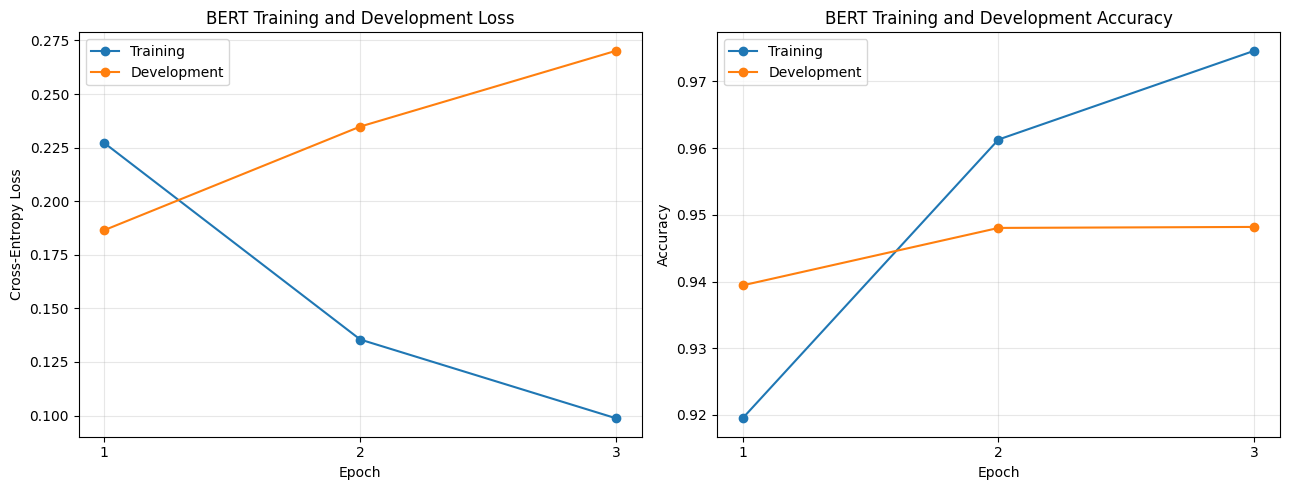

In [80]:
import matplotlib.pyplot as plt

bert_history_df = pd.DataFrame(bert_history)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training and development loss
axes[0].plot(
    bert_history_df["Epoch"],
    bert_history_df["Train Loss"],
    marker="o",
    label="Training"
)

axes[0].plot(
    bert_history_df["Epoch"],
    bert_history_df["Dev Loss"],
    marker="o",
    label="Development"
)

axes[0].set_title("BERT Training and Development Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xticks([1, 2, 3])

# Training and development accuracy
axes[1].plot(
    bert_history_df["Epoch"],
    bert_history_df["Train Accuracy"],
    marker="o",
    label="Training"
)

axes[1].plot(
    bert_history_df["Epoch"],
    bert_history_df["Dev Accuracy"],
    marker="o",
    label="Development"
)

axes[1].set_title("BERT Training and Development Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_xticks([1, 2, 3])
plt.tight_layout()

plt.savefig(
    "/kaggle/working/bert_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3.6 BERT Model Evaluation

### Objective

We evaluate the fine-tuned BERT classifier on the official SST-2 validation set and compare its classification performance against Logistic Regression and GRU with Attention.

### Checkpoint Selection

We select the checkpoint with the lowest development cross-entropy loss.

The best checkpoint was obtained at epoch 1, with development loss of 0.1865.

Although development accuracy improved in later epochs, development loss increased. Therefore, we retain our predefined model-selection criterion.

### Evaluation Metrics

We calculate:

1. Accuracy.
2. Macro Precision.
3. Macro Recall.
4. Macro F1-score.
5. ROC-AUC.
6. Confusion Matrix.

### Evaluation Protocol

All three classifiers are evaluated on the same 872 official validation sentences.

The selected BERT checkpoint is loaded from disk and placed in evaluation mode. No model parameters are updated during evaluation.

### Justification

Using a consistent validation dataset and evaluation metrics allows us to compare classification performance across traditional, recurrent, and transformer-based architectures.

We also distinguish model classification performance from explanation agreement and faithfulness, which will be evaluated separately.


In [79]:
import torch
import numpy as np
import pandas as pd
import gc

from transformers import AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Free training optimizer/model GPU memory
del bert_model
del bert_optimizer

gc.collect()
torch.cuda.empty_cache()

# Load best checkpoint (epoch 1)
BERT_SAVE_DIR = "/kaggle/working/models/best_bert_sst2"

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_SAVE_DIR
).to(device)

bert_model.eval()

print("Best BERT checkpoint loaded!")

bert_preds = []
bert_probs = []
bert_true = []

# Evaluate on all validation examples
with torch.inference_mode():

    for input_ids, attention_mask, labels in bert_val_loader:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(
            outputs.logits, dim=1
        )

        predictions = probabilities.argmax(dim=1)

        bert_preds.extend(
            predictions.cpu().numpy()
        )

        bert_probs.extend(
            probabilities[:, 1].cpu().numpy()
        )

        bert_true.extend(
            labels.numpy()
        )

# Convert to numpy arrays
bert_preds = np.array(bert_preds)
bert_probs = np.array(bert_probs)
bert_true = np.array(bert_true)

assert len(bert_true) == 872

# Calculate metrics
bert_results = {
    "Model": "BERT Base",
    "Accuracy": accuracy_score(bert_true, bert_preds),
    "Precision (Macro)": precision_score(
        bert_true, bert_preds, average="macro"
    ),
    "Recall (Macro)": recall_score(
        bert_true, bert_preds, average="macro"
    ),
    "F1 (Macro)": f1_score(
        bert_true, bert_preds, average="macro"
    ),
    "ROC-AUC": roc_auc_score(
        bert_true, bert_probs
    )
}

print("\nBERT Final Evaluation Results:")
display(pd.DataFrame([bert_results]).round(4))

print("\nClassification Report:")
print(
    classification_report(
        bert_true,
        bert_preds,
        target_names=["Negative", "Positive"],
        digits=4
    )
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Best BERT checkpoint loaded!

BERT Final Evaluation Results:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),ROC-AUC
0,BERT Base,0.9002,0.9064,0.8991,0.8996,0.9783



Classification Report:
              precision    recall  f1-score   support

    Negative     0.9523    0.8388    0.8919       428
    Positive     0.8606    0.9595    0.9073       444

    accuracy                         0.9002       872
   macro avg     0.9064    0.8991    0.8996       872
weighted avg     0.9056    0.9002    0.8998       872




## 3.7 Comparison of Classification Models

### Objective

We compare the classification performance of three architectures on SST-2:

1. Logistic Regression with TF-IDF.
2. Bidirectional GRU with Attention.
3. BERT Base Uncased.

### Evaluation Setup

All models are evaluated on the official SST-2 validation set containing 872 sentences.

### Evaluation Metrics

We use:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- ROC-AUC
- Confusion Matrix

All classification metrics are reported on a scale from 0 to 1.

### Why Compare These Models?

The selected classifiers represent three different approaches to text classification.

**Logistic Regression:** Uses sparse TF-IDF word features and provides directly interpretable model coefficients.

**GRU with Attention:** Processes sequential word representations and produces learned attention weights.

**BERT:** Uses pretrained contextual representations and multi-head transformer attention.

### Justification

The comparison establishes how classification performance varies across model architectures.

However, classification accuracy does not directly measure explanation quality.

We evaluate explanation agreement and deletion-based faithfulness separately to investigate whether more accurate classifiers also produce more useful explanations.

### Evaluation Limitation

The classifiers share the same validation set, but their training procedures differ.

Logistic Regression uses the full training split, while GRU and BERT use internal development splits for checkpoint selection.

Therefore, the comparison represents the performance of our implemented pipelines rather than a controlled architecture-only experiment.


In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Combine all model results
final_comparison = pd.DataFrame([
    lr_results,
    gru_results,
    bert_results
])

# Display results
print("Final SST-2 Model Comparison")
display(final_comparison.round(4))

# Save results
final_comparison.to_csv(
    "/kaggle/working/final_model_comparison.csv",
    index=False
)

Final SST-2 Model Comparison


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),ROC-AUC
0,Logistic Regression,0.8154,0.8178,0.8145,0.8147,0.9025
1,GRU with Attention,0.8349,0.8374,0.8340,0.8343,0.9155
2,BERT Base,0.9002,0.9064,0.8991,0.8996,0.9783


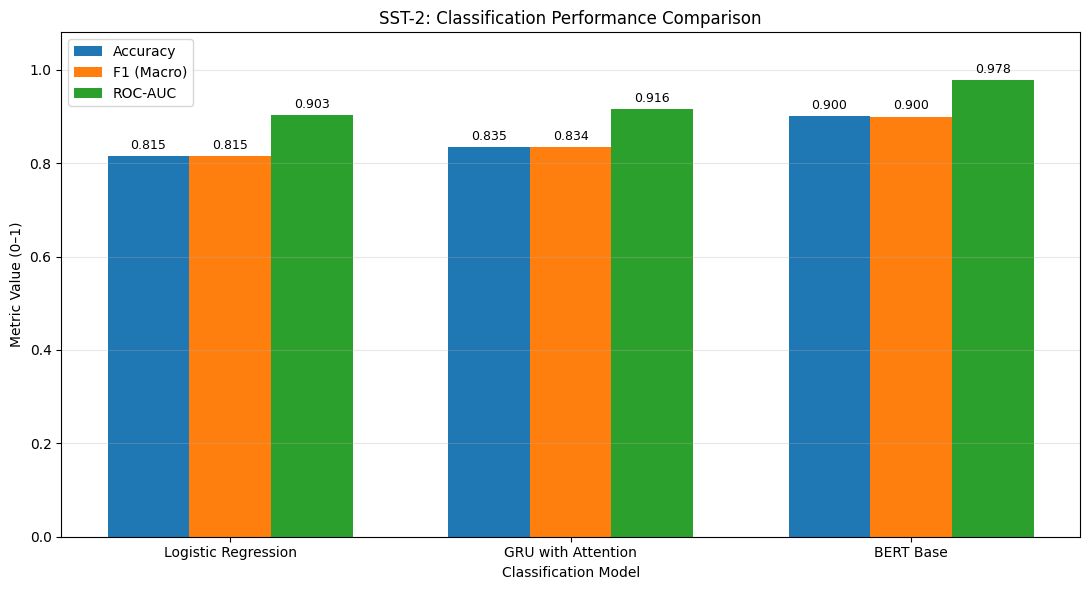

In [82]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["Accuracy", "F1 (Macro)", "ROC-AUC"]

model_names = final_comparison["Model"].tolist()

x = np.arange(len(model_names))
width = 0.24

fig, ax = plt.subplots(figsize=(11, 6))

for i, metric in enumerate(metrics):

    values = final_comparison[metric].to_numpy()

    bars = ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=metric
    )

    ax.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

ax.set_xlabel("Classification Model")
ax.set_ylabel("Metric Value (0–1)")

ax.set_title(
    "SST-2: Classification Performance Comparison"
)

ax.set_xticks(x)
ax.set_xticklabels(model_names)

ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

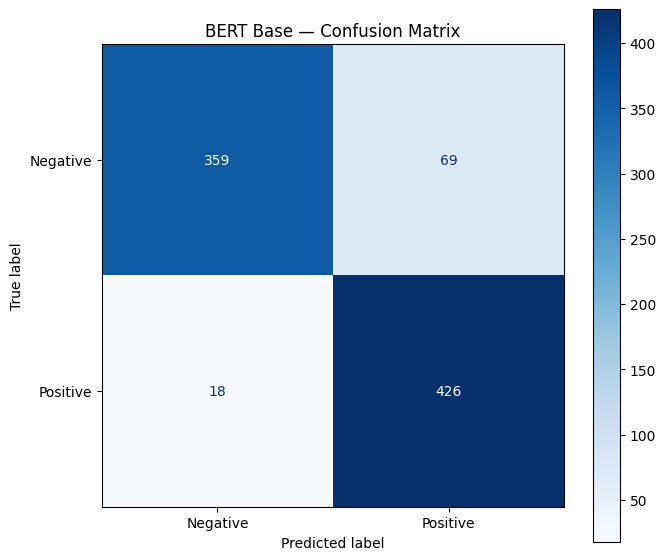

Confusion Matrix:
[[359  69]
 [ 18 426]]


In [83]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm_bert = confusion_matrix(
    bert_true,
    bert_preds,
    labels=[0, 1]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_bert,
    display_labels=["Negative", "Positive"]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("BERT Base — Confusion Matrix")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/bert_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix:")
print(cm_bert)

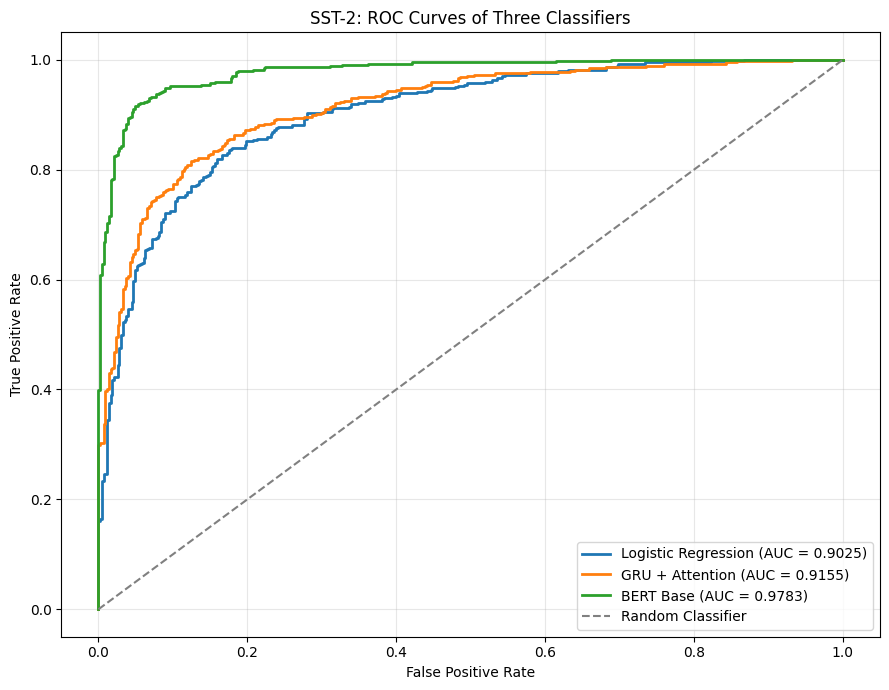

In [84]:
from sklearn.metrics import roc_curve, roc_auc_score

# Ensure predictions use the same 872 validation labels
true_labels = y_val.to_numpy()

assert len(true_labels) == 872
assert np.array_equal(true_labels, gru_true)
assert np.array_equal(true_labels, bert_true)

# Recalculate LR probabilities using the current trained model
lr_probs_final = lr_model.predict_proba(
    X_val_tfidf
)[:, 1]

roc_models = {
    "Logistic Regression": lr_probs_final,
    "GRU + Attention": gru_probs,
    "BERT Base": bert_probs
}

plt.figure(figsize=(9, 7))

for name, probabilities in roc_models.items():

    fpr, tpr, _ = roc_curve(
        true_labels,
        probabilities
    )

    auc_score = roc_auc_score(
        true_labels,
        probabilities
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("SST-2: ROC Curves of Three Classifiers")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/kaggle/working/all_models_roc.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3.8 BERT Attention-Based Explanations

### Objective

We analyze the self-attention weights of our fine-tuned BERT classifier to examine which tokens receive attention during sentiment classification.

### How Does BERT Attention Work?

BERT uses multi-head self-attention to learn relationships between tokens.

The scaled dot-product attention formula is:

$$
\boxed{
\mathrm{Attention}(Q,K,V)=
\mathrm{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
}
$$

Where:

- $Q$: Query matrix.
- $K$: Key matrix.
- $V$: Value matrix.
- $d_k$: Dimension of the key vectors.

### BERT Architecture

Our BERT Base model has:

- 12 transformer encoder layers.
- 12 attention heads per layer.
- 768-dimensional hidden representations.

### Explanation Method

For our initial attention analysis:

1. Extract attention from the final transformer layer.
2. Select attention originating from the `[CLS]` token.
3. Average attention scores across the 12 heads.
4. Exclude special tokens from the visualization.
5. Normalize the remaining scores for comparison.

The resulting scores represent how the final-layer `[CLS]` representation attends to input tokens.

### Why Use This Method?

The `[CLS]` representation is used for sentence-level classification, so inspecting its attention offers a simple way to visualize token relationships.

### Limitation

Attention weights are not direct measures of causal feature importance. High attention does not guarantee that deleting a token will substantially change the model's prediction.

We will evaluate these scores against LIME using agreement metrics and deletion tests.


In [85]:
import torch
import numpy as np
import pandas as pd

# Use the already fine-tuned BERT checkpoint
bert_model.eval()

# Enable attention weight extraction
bert_model.set_attn_implementation("eager")

# Same sentence used in LR and GRU explanations
sample_idx = 0
sentence = X_val.iloc[sample_idx]

# Tokenize
inputs = bert_tokenizer(
    sentence,
    return_tensors="pt",
    truncation=True,
    max_length=BERT_MAX_LEN
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Obtain prediction and attention matrices
with torch.no_grad():
    outputs = bert_model(
        **inputs,
        output_attentions=True,
        return_dict=True
    )

    probabilities = torch.softmax(outputs.logits, dim=1)

predicted_class = probabilities.argmax(dim=1).item()

# Attention from the last transformer layer
last_attention = outputs.attentions[-1][0]

# Shape: [12 heads, sequence length, sequence length]
print("Last-layer attention shape:", last_attention.shape)

# CLS attention to each token, averaged over 12 heads
cls_attention = (
    last_attention[:, 0, :]
    .mean(dim=0)
    .cpu()
    .numpy()
)

tokens = bert_tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].cpu().tolist()
)

print("\nSentence:", sentence)
print("Actual label:", int(y_val.iloc[sample_idx]))
print("Predicted class:", predicted_class)
print("Positive probability:",
      round(probabilities[0, 1].item(), 4))

print("\nTokens:", tokens)
print("Attention sum:", round(cls_attention.sum(), 4))

Last-layer attention shape: torch.Size([12, 12, 12])

Sentence: it 's a charming and often affecting journey .
Actual label: 1
Predicted class: 1
Positive probability: 0.9989

Tokens: ['[CLS]', 'it', "'", 's', 'a', 'charming', 'and', 'often', 'affecting', 'journey', '.', '[SEP]']
Attention sum: 1.0


,Token,Attention,Normalized Attention
10,.,0.4851,0.5466
6,and,0.0562,0.0633
3,s,0.0550,0.0619
1,it,0.0492,0.0554
4,a,0.0473,0.0533
5,charming,0.0447,0.0503
2,',0.0440,0.0496
7,often,0.0377,0.0424
8,affecting,0.0343,0.0386
9,journey,0.0342,0.0386


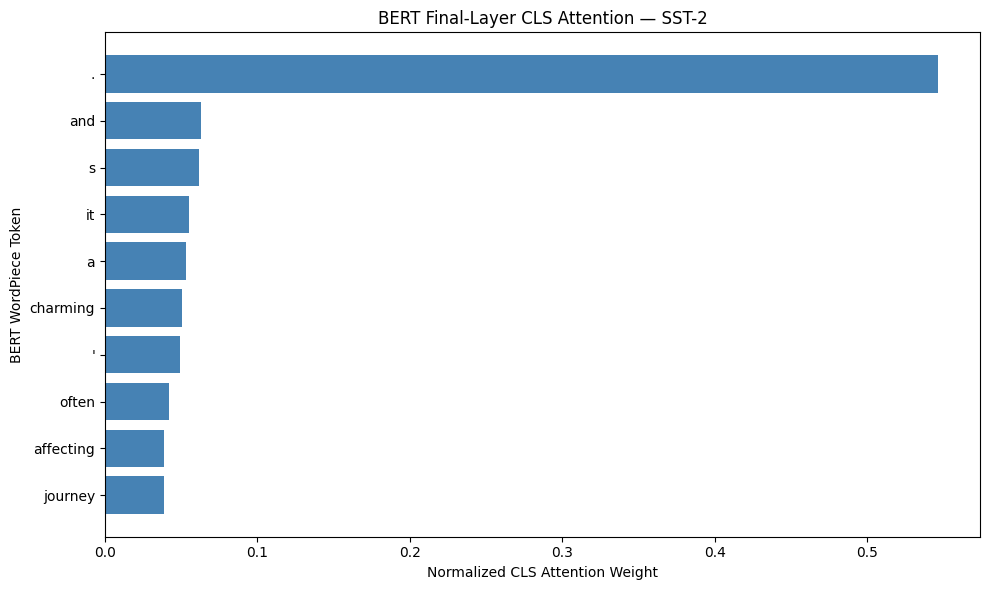

In [86]:
import matplotlib.pyplot as plt

# Remove special tokens from the visualization
special_tokens = set(bert_tokenizer.all_special_tokens)

attention_df = pd.DataFrame({
    "Token": tokens,
    "Attention": cls_attention
})

attention_df = attention_df[
    ~attention_df["Token"].isin(special_tokens)
].copy()

# Normalize over the displayed tokens
attention_df["Normalized Attention"] = (
    attention_df["Attention"] /
    attention_df["Attention"].sum()
)

display(
    attention_df.sort_values(
        "Normalized Attention",
        ascending=False
    ).round(4)
)

# Plot
plot_df = attention_df.sort_values(
    "Normalized Attention"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Token"],
    plot_df["Normalized Attention"],
    color="steelblue"
)

plt.xlabel("Normalized CLS Attention Weight")
plt.ylabel("BERT WordPiece Token")
plt.title("BERT Final-Layer CLS Attention — SST-2")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/bert_attention_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

,Token,Attention,Normalized Attention,Word Attention
6,and,0.0562,0.0633,0.1567
3,s,0.0550,0.0619,0.1534
1,it,0.0492,0.0554,0.1372
4,a,0.0473,0.0533,0.1319
5,charming,0.0447,0.0503,0.1246
7,often,0.0377,0.0424,0.1051
8,affecting,0.0343,0.0386,0.0957
9,journey,0.0342,0.0386,0.0955


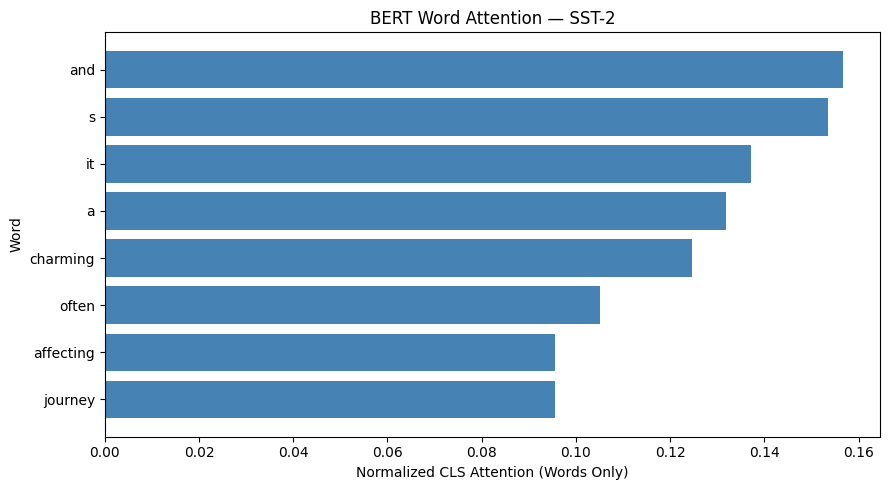

In [87]:
# Keep alphabetic tokens for this example
word_attention_df = attention_df[
    attention_df["Token"].str.fullmatch(r"[A-Za-z]+")
].copy()

# Normalize over displayed words
word_attention_df["Word Attention"] = (
    word_attention_df["Attention"] /
    word_attention_df["Attention"].sum()
)

display(
    word_attention_df.sort_values(
        "Word Attention",
        ascending=False
    ).round(4)
)

# Plot
plot_df = word_attention_df.sort_values("Word Attention")

plt.figure(figsize=(9, 5))

plt.barh(
    plot_df["Token"],
    plot_df["Word Attention"],
    color="steelblue"
)

plt.xlabel("Normalized CLS Attention (Words Only)")
plt.ylabel("Word")
plt.title("BERT Word Attention — SST-2")

plt.tight_layout()
plt.show()


## 3.9 LIME Explanations for BERT

### Objective

We apply LIME to the fine-tuned BERT classifier to identify words influencing individual sentiment predictions.

### Methodology

1. Select a validation sentence.
2. Generate perturbed versions of the sentence using LIME.
3. Obtain BERT's predicted sentiment probabilities.
4. Fit a locally weighted surrogate model.
5. Extract word-importance scores.
6. Compare LIME explanations with BERT's attention-based word scores.

### Why Use LIME?

LIME is model-agnostic and can be applied to Logistic Regression, GRU and BERT using their prediction probabilities.

This allows us to investigate explanation behavior across different classifier architectures.

### Comparison

We will compare:

- BERT final-layer CLS attention.
- LIME word importance.
- Random word selection as a deletion baseline.

We will measure Top-k overlap, Spearman correlation and deletion-based faithfulness using the same fixed 200 validation examples.

### Limitation

LIME uses random perturbations and a local surrogate approximation. Its word scores may be unstable or inaccurate when the surrogate poorly approximates BERT's behavior.

Attention scores also do not directly measure causal importance, so both methods require behavioral evaluation.


In [88]:
import torch
import numpy as np
from lime.lime_text import LimeTextExplainer

bert_model.eval()

def predict_proba_bert(texts):

    all_probs = []
    batch_size = 32

    for start in range(0, len(texts), batch_size):

        batch_texts = list(
            texts[start:start + batch_size]
        )

        # Tokenize perturbed sentences
        encoded = bert_tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=BERT_MAX_LEN,
            return_tensors="pt"
        )

        # Move tensors to GPU
        encoded = {
            key: value.to(device)
            for key, value in encoded.items()
        }

        # BERT prediction
        with torch.inference_mode():
            outputs = bert_model(**encoded)

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )

        all_probs.append(
            probabilities.cpu().numpy()
        )

    return np.vstack(all_probs)


print("BERT prediction function created!")

# Test on the same validation sentence
sample_idx = 0
sentence = X_val.iloc[sample_idx]

probs = predict_proba_bert([sentence])[0]

print("Sentence:", sentence)
print("Negative probability:", round(probs[0], 4))
print("Positive probability:", round(probs[1], 4))

BERT prediction function created!
Sentence: it 's a charming and often affecting journey .
Negative probability: 0.0011
Positive probability: 0.9989


Sentence: it 's a charming and often affecting journey .
Predicted class: 1

LIME Word Importance:
charming: 0.0111
affecting: 0.0107
journey: 0.0053
a: 0.0033
it: 0.0028
often: 0.0019
and: -0.0018
s: 0.0007

LIME Local R-squared: 0.3845


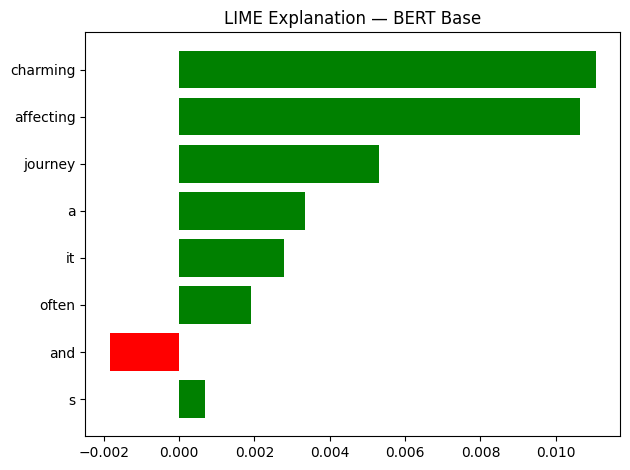

In [89]:
# Initialize LIME
bert_lime_explainer = LimeTextExplainer(
    class_names=["Negative", "Positive"],
    random_state=42
)

# Same sentence
sample_idx = 0
sentence = X_val.iloc[sample_idx]

# Get prediction
original_probs = predict_proba_bert([sentence])[0]
predicted_class = int(np.argmax(original_probs))

# Generate explanation
bert_lime_exp = bert_lime_explainer.explain_instance(
    sentence,
    predict_proba_bert,
    labels=(predicted_class,),
    num_features=20,
    num_samples=1000
)

print("Sentence:", sentence)
print("Predicted class:", predicted_class)

print("\nLIME Word Importance:")

for word, weight in bert_lime_exp.as_list(
    label=predicted_class
):
    print(f"{word}: {weight:.4f}")

print(
    "\nLIME Local R-squared:",
    round(bert_lime_exp.score, 4)
)

# Plot
fig = bert_lime_exp.as_pyplot_figure(
    label=predicted_class
)

plt.title("LIME Explanation — BERT Base")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/bert_lime_example.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3.10 BERT Attention and LIME Explanations on 200 Examples

### Objective

We investigate whether BERT's attention-based explanations agree with LIME's word-importance explanations across multiple validation sentences.

### Evaluation Setup

| Parameter | Value |
|---|---|
| Dataset | SST-2 |
| Evaluation examples | 200 |
| Positive examples | 100 |
| Negative examples | 100 |
| Model | Fine-tuned BERT Base |
| Explanation methods | Final-layer CLS Attention and LIME |
| LIME perturbations | 1,000 per sentence |
| Random seed | 42 |

### Methodology

1. Select the same 200 validation sentences used in previous experiments.
2. Extract BERT's final-layer CLS attention weights.
3. Average attention across all 12 heads.
4. Map WordPiece tokens to original words using character offsets.
5. Aggregate subword attention scores into word-level scores.
6. Generate LIME explanations for the same BERT predictions.
7. Record word importance and LIME local R-squared.
8. Save all explanations for agreement and faithfulness evaluation.

### Word Alignment

BERT may split a word into multiple subword tokens.

For example:

`unbelievable` → `un`, `##believable`

We combine the attention scores of subwords belonging to the same original word.

Punctuation and special tokens are excluded from the word-level comparison. We retain the original sentences when making predictions.

Repeated occurrences of a word are aggregated into a single word-type score to match LIME's bag-of-words representation.

### Evaluation Metrics

We will evaluate:

- Top-3 overlap.
- Top-5 overlap.
- Spearman rank correlation.
- Mean LIME local R-squared.
- Deletion-based faithfulness.

### Justification

Using identical sentences and aligned word features avoids misleading comparisons caused by different tokenization methods.

Attention weights and LIME values are compared through rankings, not their raw numerical magnitudes.

### Limitations

Final-layer CLS attention is only one possible attention-based explanation of BERT.

It does not capture all information flowing through the 12 transformer layers.

High attention or high agreement does not necessarily indicate explanation faithfulness. We will evaluate this separately through word deletion.


In [91]:
import re
import numpy as np
import torch

# Extract BERT attention and align it with words
def get_bert_word_attention(sentence):

    # Identify original word spans
    word_matches = list(
        re.finditer(r"\w+", sentence)
    )

    words = [
        match.group().lower()
        for match in word_matches
    ]

    spans = [
        match.span()
        for match in word_matches
    ]

    # Tokenize with character offsets
    encoded = bert_tokenizer(
        sentence,
        return_offsets_mapping=True,
        return_tensors="pt",
        truncation=True,
        max_length=BERT_MAX_LEN
    )

    offsets = encoded.pop(
        "offset_mapping"
    )[0].tolist()

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    # Extract last-layer CLS attention
    bert_model.eval()

    with torch.inference_mode():

        outputs = bert_model(
            **encoded,
            output_attentions=True,
            return_dict=True
        )

        probs = torch.softmax(
            outputs.logits, dim=1
        )

        attention = (
            outputs.attentions[-1][0, :, 0, :]
            .mean(dim=0)
            .float()
            .cpu()
            .numpy()
        )

    # Aggregate WordPiece attention by character overlap
    word_attention = np.zeros(
        len(words), dtype=float
    )

    for (start, end), weight in zip(offsets, attention):

        # Skip special tokens
        if end <= start:
            continue

        overlaps = [
            max(0, min(end, w_end) - max(start, w_start))
            for w_start, w_end in spans
        ]

        total_overlap = sum(overlaps)

        if total_overlap == 0:
            continue

        for j, overlap in enumerate(overlaps):
            if overlap > 0:
                word_attention[j] += (
                    float(weight) *
                    overlap / total_overlap
                )

    # Aggregate repeated words into word types
    word_scores = {}

    for word, weight in zip(words, word_attention):
        word_scores[word] = (
            word_scores.get(word, 0.0)
            + float(weight)
        )

    # Normalize over words only
    total = sum(word_scores.values())

    if total > 0:
        word_scores = {
            word: score / total
            for word, score in word_scores.items()
        }

    return {
        "attention_scores": word_scores,
        "predicted_class": int(
            probs.argmax(dim=1).item()
        ),
        "positive_probability": float(
            probs[0, 1].item()
        )
    }


# Test on existing sentence
sample_idx = 0
sentence = X_val.iloc[sample_idx]

result = get_bert_word_attention(sentence)

print("Sentence:", sentence)
print("Predicted class:", result["predicted_class"])

print("\nWord-level BERT Attention:")
for word, score in sorted(
    result["attention_scores"].items(),
    key=lambda x: -x[1]
):
    print(f"{word}: {score:.4f}")

print(
    "\nAttention sum:",
    round(sum(result["attention_scores"].values()), 4)
)

Sentence: it 's a charming and often affecting journey .
Predicted class: 1

Word-level BERT Attention:
and: 0.1567
s: 0.1534
it: 0.1372
a: 0.1319
charming: 0.1246
often: 0.1051
affecting: 0.0957
journey: 0.0955

Attention sum: 1.0


In [92]:
import os
import pandas as pd
import numpy as np

from lime.lime_text import LimeTextExplainer
from tqdm.auto import tqdm

# Same 200 validation indices
eval_indices = eval_df.index.to_numpy()

assert len(eval_indices) == 200
assert bert_tokenizer.is_fast

# Set attention extraction mode
bert_model.set_attn_implementation("eager")
bert_model.eval()

# Save path
BERT_EXPLANATIONS_PATH = (
    "/kaggle/working/bert_explanations_200.pkl"
)

# Resume from saved results if available
if os.path.exists(BERT_EXPLANATIONS_PATH):
    bert_explanations = pd.read_pickle(
        BERT_EXPLANATIONS_PATH
    )
else:
    bert_explanations = []

completed_indices = {
    item["validation_index"]
    for item in bert_explanations
}

for idx in tqdm(
    eval_indices,
    desc="BERT Attention + LIME"
):

    idx = int(idx)

    if idx in completed_indices:
        continue

    sentence = str(X_val.iloc[idx])

    # ========== BERT ATTENTION ==========
    attention_result = get_bert_word_attention(
        sentence
    )

    predicted_class = attention_result[
        "predicted_class"
    ]

    attention_scores = attention_result[
        "attention_scores"
    ]

    # ========== LIME ==========
    # Fixed per-sentence seed for reproducibility
    lime_explainer = LimeTextExplainer(
        class_names=["Negative", "Positive"],
        random_state=42 + idx,
        bow=True,
        split_expression=r"\W+"
    )

    lime_exp = lime_explainer.explain_instance(
        sentence,
        predict_proba_bert,
        labels=(predicted_class,),
        num_features=len(attention_scores),
        num_samples=1000
    )

    lime_scores = {
        word.lower(): float(weight)
        for word, weight in lime_exp.as_list(
            label=predicted_class
        )
    }

    # Check word alignment
    missing_words = [
        word for word in attention_scores
        if word not in lime_scores
    ]

    bert_explanations.append({
        "validation_index": idx,
        "sentence": sentence,
        "true_label": int(y_val.iloc[idx]),
        "predicted_class": predicted_class,
        "positive_probability":
            attention_result["positive_probability"],
        "attention_scores": attention_scores,
        "lime_scores": lime_scores,
        "lime_r2": float(lime_exp.score),
        "missing_words": missing_words
    })

    completed_indices.add(idx)

    # Save intermediate progress
    if len(bert_explanations) % 10 == 0:
        pd.to_pickle(
            bert_explanations,
            BERT_EXPLANATIONS_PATH
        )

# Save final results
pd.to_pickle(
    bert_explanations,
    BERT_EXPLANATIONS_PATH
)

print("\nBERT explanations completed!")
print("Total examples:", len(bert_explanations))

print(
    "Examples with missing word matches:",
    sum(
        len(item["missing_words"]) > 0
        for item in bert_explanations
    )
)

print("Saved to:", BERT_EXPLANATIONS_PATH)

BERT Attention + LIME:   0%|          | 0/200 [00:00<?, ?it/s]


BERT explanations completed!
Total examples: 200
Examples with missing word matches: 0
Saved to: /kaggle/working/bert_explanations_200.pkl


In [93]:
import numpy as np
import pandas as pd

bert_lime_r2 = np.array([
    item["lime_r2"]
    for item in bert_explanations
])

print("BERT + LIME Evaluation Summary")
print("--------------------------------")

print("Total examples:", len(bert_explanations))

print(
    "Mean R-squared:",
    round(bert_lime_r2.mean(), 4)
)

print(
    "Median R-squared:",
    round(np.median(bert_lime_r2), 4)
)

print(
    "Minimum R-squared:",
    round(bert_lime_r2.min(), 4)
)

print(
    "Maximum R-squared:",
    round(bert_lime_r2.max(), 4)
)

print(
    "Examples with R² < 0.5:",
    np.sum(bert_lime_r2 < 0.5)
)

# Save summary
bert_lime_summary = pd.DataFrame({
    "Model": ["BERT Base"],
    "N": [len(bert_lime_r2)],
    "Mean_R2": [bert_lime_r2.mean()],
    "Median_R2": [np.median(bert_lime_r2)],
    "Low_R2_Count": [
        int(np.sum(bert_lime_r2 < 0.5))
    ]
})

bert_lime_summary.to_csv(
    "/kaggle/working/bert_lime_summary.csv",
    index=False
)

display(bert_lime_summary.round(4))

BERT + LIME Evaluation Summary
--------------------------------
Total examples: 200
Mean R-squared: 0.4978
Median R-squared: 0.516
Minimum R-squared: 0.0728
Maximum R-squared: 0.9995
Examples with R² < 0.5: 95


,Model,N,Mean_R2,Median_R2,Low_R2_Count
0,BERT Base,200,0.4978,0.516,95



## 3.11 BERT Attention vs LIME — Explanation Agreement

### Objective

We investigate whether BERT's final-layer CLS attention and LIME identify similar important words for the same sentiment predictions.

### Evaluation Setup

- **Dataset:** SST-2 validation set.
- **Evaluation examples:** 200 (100 positive, 100 negative).
- **Classifier:** Fine-tuned BERT Base Uncased.
- **Explanation methods:** Final-layer CLS Attention and LIME.
- **Ranking criterion:** Attention weight and absolute LIME attribution.

### 1. Top-k Overlap

Top-k overlap measures the fraction of important words shared by two explanation methods.

$$
\boxed{\mathrm{Overlap@k}(A,B)=\frac{|A_k\cap B_k|}{k}}
$$

We evaluate k = 3 and k = 5.

### 2. Spearman Rank Correlation

Spearman correlation measures agreement between complete word-importance rankings.

$$
\boxed{\rho_s=\mathrm{corr}(R_A,R_B)}
$$

Values range from -1 to +1:

- +1: Identical rankings.
- 0: No rank correlation.
- -1: Opposite rankings.

### 3. Random Overlap Baseline

Top-k overlap can be artificially high for short sentences.

If a sentence has $n$ unique words and two independent methods randomly select $k$ words, the expected overlap is:

$$
\boxed{\mathbb{E}[\mathrm{Overlap@k}]=\frac{k}{n}}
$$

We compare observed overlap against this random-selection expectation.

### Fair Comparison

1. Both explanations correspond to the same BERT prediction.
2. WordPiece tokens are aligned with original words.
3. Punctuation and special tokens are excluded from word-level rankings.
4. Repeated words are aggregated into word-type scores.
5. Top-3 requires at least 6 unique words.
6. Top-5 requires at least 10 unique words.
7. Spearman requires at least 3 unique words and nonconstant rankings.

We report the number of eligible sentences for every metric.

### Justification

Agreement measures whether methods identify similar important words. Comparing with random overlap helps determine whether the observed agreement is meaningful beyond sentence-length effects.

However, agreement does not establish faithfulness, which will be evaluated separately using word deletion.


In [94]:

import numpy as np
import pandas as pd
from scipy.stats import spearmanr

# Verify the evaluation sample
assert len(bert_explanations) == 200

assert len(set(
    item["validation_index"]
    for item in bert_explanations
)) == 200

assert all(
    len(item["missing_words"]) == 0
    for item in bert_explanations
)

# Top-k overlap
def bert_topk_overlap(words, att, lime, k):

    n = len(words)

    if n < 2 * k:
        return np.nan

    # Rank attention weights
    top_att = set(sorted(
        words,
        key=lambda w: (-abs(att[w]), w)
    )[:k])

    # Rank absolute LIME weights
    top_lime = set(sorted(
        words,
        key=lambda w: (-abs(lime[w]), w)
    )[:k])

    return len(top_att & top_lime) / k


# Spearman rank correlation
def bert_spearman(words, att, lime):

    if len(words) < 3:
        return np.nan

    att_values = np.array([
        abs(att[w]) for w in words
    ])

    lime_values = np.array([
        abs(lime[w]) for w in words
    ])

    # Undefined when scores are constant
    if (
        np.unique(att_values).size < 2
        or np.unique(lime_values).size < 2
    ):
        return np.nan

    return float(
        spearmanr(att_values, lime_values).statistic
    )


agreement_records = []

for item in bert_explanations:

    att = item["attention_scores"]
    lime = item["lime_scores"]

    # Common vocabulary
    words = sorted(att.keys())

    assert set(words) == set(lime.keys())

    n = len(words)

    top3 = bert_topk_overlap(words, att, lime, 3)
    top5 = bert_topk_overlap(words, att, lime, 5)

    rho = bert_spearman(words, att, lime)

    agreement_records.append({
        "validation_index": item["validation_index"],
        "N_Words": n,
        "Top3": top3,
        "Top5": top5,
        "RandomExpectedTop3": (
            3 / n if n >= 6 else np.nan
        ),
        "RandomExpectedTop5": (
            5 / n if n >= 10 else np.nan
        ),
        "Spearman": rho,
        "LIME_R2": item["lime_r2"],
        "Predicted_Class": item["predicted_class"]
    })

bert_agreement_df = pd.DataFrame(agreement_records)

print("Selected examples:", len(bert_explanations))
print("Analyzed examples:", len(bert_agreement_df))

# Aggregate results
bert_agreement_summary = pd.DataFrame({
    "Metric": [
        "Top-3 Overlap",
        "Top-5 Overlap",
        "Spearman Correlation"
    ],
    "Mean": [
        bert_agreement_df["Top3"].mean(),
        bert_agreement_df["Top5"].mean(),
        bert_agreement_df["Spearman"].mean()
    ],
    "N": [
        bert_agreement_df["Top3"].count(),
        bert_agreement_df["Top5"].count(),
        bert_agreement_df["Spearman"].count()
    ],
    "Random Expected": [
        bert_agreement_df["RandomExpectedTop3"].mean(),
        bert_agreement_df["RandomExpectedTop5"].mean(),
        0.0
    ]
})

bert_agreement_summary["Excess Over Random"] = (
    bert_agreement_summary["Mean"]
    - bert_agreement_summary["Random Expected"]
)

print("\nBERT Attention vs LIME Agreement:")
display(bert_agreement_summary.round(4))

# Save results
bert_agreement_df.to_csv(
    "/kaggle/working/bert_agreement_200.csv",
    index=False
)

bert_agreement_summary.to_csv(
    "/kaggle/working/bert_agreement_summary.csv",
    index=False
)


Selected examples: 200
Analyzed examples: 200

BERT Attention vs LIME Agreement:


,Metric,Mean,N,Random Expected,Excess Over Random
0,Top-3 Overlap,0.3939,187,0.2019,0.1920
1,Top-5 Overlap,0.4412,165,0.2924,0.1488
2,Spearman Correlation,0.2581,199,0.0000,0.2581


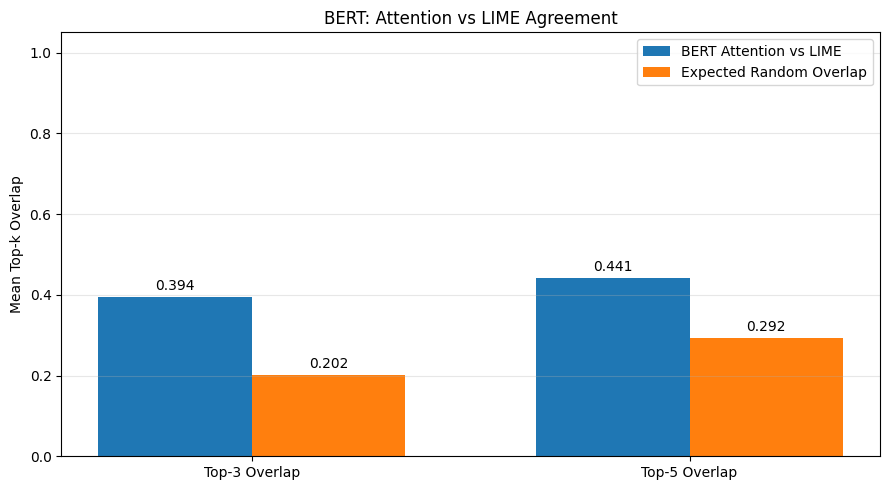

In [95]:

import matplotlib.pyplot as plt
import numpy as np

# Top-k metrics only
plot_data = bert_agreement_summary.iloc[:2]

metrics = plot_data["Metric"].tolist()
observed = plot_data["Mean"].to_numpy()
random_expected = plot_data["Random Expected"].to_numpy()

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(
    x - width / 2,
    observed,
    width,
    label="BERT Attention vs LIME"
)

bars2 = ax.bar(
    x + width / 2,
    random_expected,
    width,
    label="Expected Random Overlap"
)

ax.bar_label(bars1, fmt="%.3f", padding=3)
ax.bar_label(bars2, fmt="%.3f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(metrics)

ax.set_ylabel("Mean Top-k Overlap")
ax.set_title(
    "BERT: Attention vs LIME Agreement"
)

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/bert_agreement_graph.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 3.12 BERT Explanation Faithfulness Using Word Deletion

### Objective

We evaluate whether important words identified by BERT final-layer CLS attention and LIME influence the classifier's predictions.

### Evaluation Setup

| Parameter | Value |
|---|---|
| Dataset | SST-2 Validation |
| Initial Evaluation Examples | 200 |
| Model | Fine-tuned BERT Base |
| Methods | CLS Attention, LIME, Random |
| Deletion Levels | Top-1, Top-3, Top-5 |
| Random Trials | 20 per sentence |
| Minimum Unique Words | 10 |

### Methodology

1. Select sentences containing at least 10 unique words.
2. Rank words according to CLS attention and absolute LIME attribution.
3. Remove the top-k important word types.
4. Recalculate BERT's predicted probabilities.
5. Measure signed probability drop and absolute probability change.
6. Compare both explanation methods with random word deletion.
7. Estimate 95% bootstrap confidence intervals.

### Signed Probability Drop

$$
\boxed{
\Delta_k=P(\hat{y}\mid x)-P(\hat{y}\mid x_{\setminus S_k})
}
$$

Where:

- $x$: Original sentence.
- $\hat{y}$: Originally predicted sentiment class.
- $S_k$: Top-k selected word types.
- $x_{\setminus S_k}$: Sentence after deletion.

### Absolute Probability Change

$$
\boxed{
A_k=\left|P(\hat{y}\mid x)-P(\hat{y}\mid x_{\setminus S_k})\right|
}
$$

### Interpretation

- Positive signed drop: Confidence in the original predicted class decreases.
- Negative signed drop: Confidence in the original class increases.
- Larger absolute change: Greater prediction sensitivity to word removal.

### Fair Comparison

All methods are evaluated using the same eligible sentences and deletion levels.

Repeated occurrences of a selected word are removed together.

Punctuation and unselected words are preserved. However, deletion may leave grammatically unnatural text.

The random baseline uses 20 trials per sentence. Its results are averaged within each sentence before statistical analysis.

### Justification

This experiment evaluates prediction sensitivity, rather than relying only on agreement between explanation rankings.

Attention and LIME are compared against random deletion to determine whether they identify words that influence BERT's predictions under the selected perturbation protocol.


In [96]:

import re
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

rng = np.random.default_rng(42)

methods = ["Attention", "LIME"]
k_values = [1, 3, 5]
random_trials = 20

# Select the same eligible sentences for all methods
eligible_items = [
    item for item in bert_explanations
    if len(item["attention_scores"]) >= 10
    and set(item["attention_scores"]) == set(item["lime_scores"])
]

print("Selected examples:", len(bert_explanations))
print("Eligible for deletion:", len(eligible_items))

# Remove all occurrences of selected word types.
# Preserve punctuation and unselected words.
def delete_bert_words(sentence, selected_words):

    selected = set(selected_words)

    return re.sub(
        r"\w+",
        lambda match: (
            "" if match.group().lower() in selected
            else match.group()
        ),
        sentence
    )

# Predict original sentences
original_texts = [
    item["sentence"] for item in eligible_items
]

original_probs = predict_proba_bert(original_texts)

# Check that predictions match saved explanations
mismatches = sum(
    int(np.argmax(original_probs[pos])) != item["predicted_class"]
    for pos, item in enumerate(eligible_items)
)

assert mismatches == 0, (
    f"{mismatches} predictions differ from saved explanations. "
    "Check that the same BERT checkpoint is loaded."
)

modified_texts = []
records = []

for pos, item in enumerate(tqdm(
    eligible_items,
    desc="Preparing BERT deletion experiments"
)):

    sentence = item["sentence"]
    words = sorted(item["attention_scores"].keys())

    original_class = int(
        np.argmax(original_probs[pos])
    )

    score_dicts = {
        "Attention": item["attention_scores"],
        "LIME": item["lime_scores"]
    }

    for k in k_values:

        # Explanation-based word deletion
        for method in methods:

            scores = score_dicts[method]

            ranked_words = sorted(
                words,
                key=lambda w: (-abs(scores[w]), w)
            )

            selected_words = ranked_words[:k]

            modified_texts.append(
                delete_bert_words(sentence, selected_words)
            )

            records.append({
                "index": item["validation_index"],
                "position": pos,
                "Method": method,
                "k": k,
                "Trial": 0,
                "Original_Class": original_class
            })

        # Random deletion baseline
        for trial in range(random_trials):

            selected_words = rng.choice(
                words,
                size=k,
                replace=False
            )

            modified_texts.append(
                delete_bert_words(sentence, selected_words)
            )

            records.append({
                "index": item["validation_index"],
                "position": pos,
                "Method": "Random",
                "k": k,
                "Trial": trial,
                "Original_Class": original_class
            })

print("Total modified sentences:", len(modified_texts))

# Obtain BERT predictions for modified sentences
modified_probs = predict_proba_bert(modified_texts)

# Calculate probability changes
for i, record in enumerate(records):

    pos = record["position"]
    cls = record["Original_Class"]

    p_before = original_probs[pos, cls]
    p_after = modified_probs[i, cls]

    record["Signed_Drop"] = float(
        p_before - p_after
    )

    record["Absolute_Change"] = float(
        abs(p_before - p_after)
    )

bert_deletion_df = pd.DataFrame(records)

# Average random trials within each sentence
bert_sentence_deletion = (
    bert_deletion_df
    .groupby(["index", "Method", "k"], as_index=False)
    .agg(
        Signed_Drop=("Signed_Drop", "mean"),
        Absolute_Change=("Absolute_Change", "mean")
    )
)

# Save results
bert_deletion_df.to_csv(
    "/kaggle/working/bert_deletion_results.csv",
    index=False
)

bert_sentence_deletion.to_csv(
    "/kaggle/working/bert_sentence_deletion.csv",
    index=False
)

print("\nBERT deletion experiments completed!")


Selected examples: 200
Eligible for deletion: 165


Preparing BERT deletion experiments:   0%|          | 0/165 [00:00<?, ?it/s]

Total modified sentences: 10890

BERT deletion experiments completed!


In [97]:

import numpy as np
import pandas as pd

rng_ci = np.random.default_rng(42)

summary = []

for (method, k), group in bert_sentence_deletion.groupby(
    ["Method", "k"]
):

    values = group["Signed_Drop"].to_numpy()

    # Sentence-level bootstrap
    boot_means = rng_ci.choice(
        values,
        size=(2000, len(values)),
        replace=True
    ).mean(axis=1)

    ci_low, ci_high = np.percentile(
        boot_means,
        [2.5, 97.5]
    )

    summary.append({
        "Method": method,
        "k": k,
        "N": len(values),
        "Mean Signed Drop": values.mean(),
        "Mean Absolute Change":
            group["Absolute_Change"].mean(),
        "CI Lower": ci_low,
        "CI Upper": ci_high
    })

bert_faithfulness_summary = pd.DataFrame(summary)

bert_faithfulness_summary = (
    bert_faithfulness_summary
    .sort_values(["k", "Method"])
    .reset_index(drop=True)
)

print("BERT Faithfulness Results:")

display(bert_faithfulness_summary.round(4))

bert_faithfulness_summary.to_csv(
    "/kaggle/working/bert_faithfulness_summary.csv",
    index=False
)


BERT Faithfulness Results:


,Method,k,N,Mean Signed Drop,Mean Absolute Change,CI Lower,CI Upper
0,Attention,1,165,0.1289,0.1571,0.0825,0.1766
1,LIME,1,165,0.2556,0.2689,0.2000,0.3127
2,Random,1,165,0.0261,0.0446,0.0192,0.0337
3,Attention,3,165,0.2443,0.2800,0.1853,0.3076
4,LIME,3,165,0.3238,0.3441,0.2627,0.3899
5,Random,3,165,0.0777,0.0990,0.0633,0.0923
6,Attention,5,165,0.2822,0.3066,0.2255,0.3399
7,LIME,5,165,0.4058,0.4263,0.3399,0.4686
8,Random,5,165,0.1237,0.1507,0.1023,0.1449


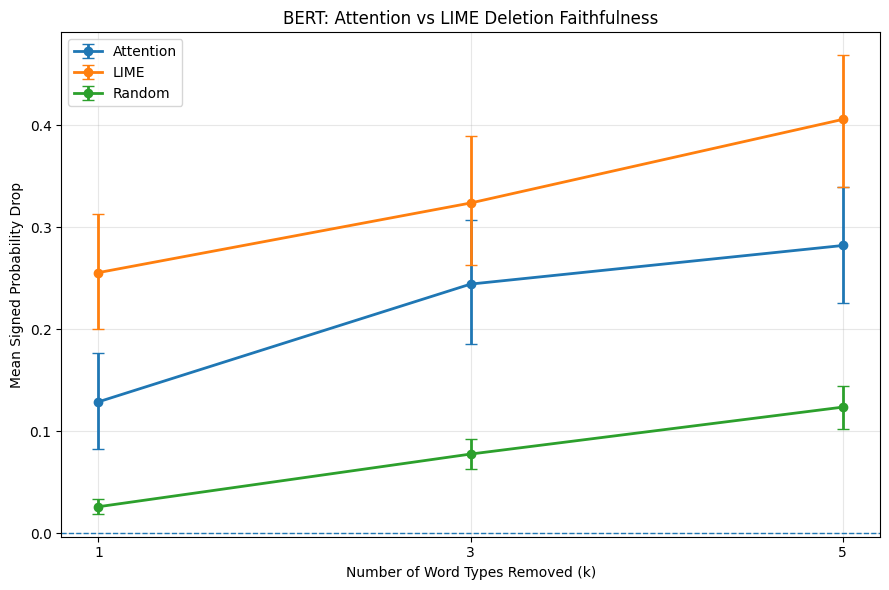

In [98]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

for method in ["Attention", "LIME", "Random"]:

    subset = (
        bert_faithfulness_summary[
            bert_faithfulness_summary["Method"] == method
        ]
        .sort_values("k")
    )

    y = subset["Mean Signed Drop"].to_numpy()

    lower_error = y - subset["CI Lower"].to_numpy()
    upper_error = subset["CI Upper"].to_numpy() - y

    plt.errorbar(
        subset["k"],
        y,
        yerr=[lower_error, upper_error],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method
    )

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Number of Word Types Removed (k)")
plt.ylabel("Mean Signed Probability Drop")

plt.title(
    "BERT: Attention vs LIME Deletion Faithfulness"
)

plt.xticks([1, 3, 5])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/bert_deletion_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


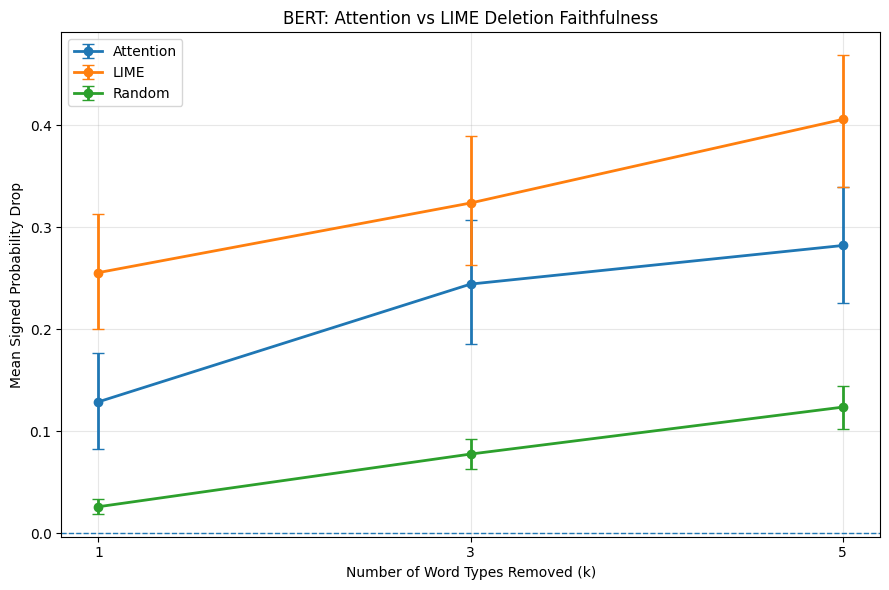

In [99]:

import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 6))

for method in ["Attention", "LIME", "Random"]:

    subset = (
        bert_faithfulness_summary[
            bert_faithfulness_summary["Method"] == method
        ]
        .sort_values("k")
    )

    y = subset["Mean Signed Drop"].to_numpy()

    lower_error = y - subset["CI Lower"].to_numpy()
    upper_error = subset["CI Upper"].to_numpy() - y

    plt.errorbar(
        subset["k"],
        y,
        yerr=[lower_error, upper_error],
        marker="o",
        linewidth=2,
        capsize=4,
        label=method
    )

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Number of Word Types Removed (k)")
plt.ylabel("Mean Signed Probability Drop")

plt.title(
    "BERT: Attention vs LIME Deletion Faithfulness"
)

plt.xticks([1, 3, 5])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/kaggle/working/bert_deletion_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 3.13 Paired Bootstrap Comparison of BERT Explanations

### Objective

We evaluate the reliability of differences in deletion-based faithfulness between LIME, CLS Attention and Random deletion.

### Methodology

All methods are evaluated on the same 165 eligible sentences.

For every sentence, we calculate the signed probability drop difference between two methods:

$$
d_i=\Delta_i^{(A)}-\Delta_i^{(B)}
$$

The mean difference is:

$$
\boxed{\bar d=\frac{1}{N}\sum_{i=1}^{N}d_i}
$$

We use 5,000 paired bootstrap resamples of the sentences to estimate confidence intervals.

### Comparisons

1. LIME vs Attention.
2. LIME vs Random.
3. Attention vs Random.

Each comparison is performed at k = 1, 3 and 5.

### Interpretation

- Positive difference: Method A has a higher mean signed probability drop.
- Confidence interval excluding zero: Evidence of a difference under the chosen bootstrap procedure.
- Confidence interval including zero: The difference is not clearly established.

We report unadjusted 95% intervals and Bonferroni-adjusted intervals for the nine comparisons.

### Justification

Paired bootstrap analysis accounts for the fact that methods were tested on identical sentences.

Random-deletion trials are averaged within each sentence before resampling, avoiding treating repeated trials as independent observations.


In [100]:

import numpy as np
import pandas as pd

# Arrange methods side by side for each sentence and k
paired_df = bert_sentence_deletion.pivot(
    index=["index", "k"],
    columns="Method",
    values="Signed_Drop"
)

comparisons = [
    ("LIME", "Attention"),
    ("LIME", "Random"),
    ("Attention", "Random")
]

rng = np.random.default_rng(42)

bootstrap_results = []

N_BOOT = 5000
N_TESTS = 9

for k in [1, 3, 5]:

    subset = paired_df.xs(k, level="k")

    for method_a, method_b in comparisons:

        paired = subset[
            [method_a, method_b]
        ].dropna()

        differences = (
            paired[method_a] - paired[method_b]
        ).to_numpy()

        n = len(differences)

        # Resample paired sentence differences
        indices = rng.integers(
            0, n,
            size=(N_BOOT, n)
        )

        boot_means = differences[indices].mean(axis=1)

        # Unadjusted 95% CI
        ci_low, ci_high = np.percentile(
            boot_means, [2.5, 97.5]
        )

        # Bonferroni adjustment for 9 comparisons
        alpha_adjusted = 0.05 / N_TESTS

        adj_low, adj_high = np.percentile(
            boot_means,
            [
                100 * alpha_adjusted / 2,
                100 * (1 - alpha_adjusted / 2)
            ]
        )

        bootstrap_results.append({
            "k": k,
            "Comparison": f"{method_a} - {method_b}",
            "N": n,
            "Mean Difference": differences.mean(),
            "CI Lower": ci_low,
            "CI Upper": ci_high,
            "95% CI Excludes Zero":
                ci_low > 0 or ci_high < 0,
            "Adjusted CI Lower": adj_low,
            "Adjusted CI Upper": adj_high,
            "Adjusted CI Excludes Zero":
                adj_low > 0 or adj_high < 0
        })

bert_paired_bootstrap = pd.DataFrame(
    bootstrap_results
)

display(bert_paired_bootstrap.round(4))

# Save results
bert_paired_bootstrap.to_csv(
    "/kaggle/working/bert_paired_bootstrap.csv",
    index=False
)

print("BERT paired bootstrap analysis completed!")


,k,Comparison,N,Mean Difference,CI Lower,CI Upper,95% CI Excludes Zero,Adjusted CI Lower,Adjusted CI Upper,Adjusted CI Excludes Zero
0,1,LIME - Attention,165,0.1267,0.0744,0.1787,True,0.0539,0.2031,True
1,1,LIME - Random,165,0.2295,0.1774,0.2829,True,0.1556,0.3032,True
2,1,Attention - Random,165,0.1028,0.0609,0.1480,True,0.0439,0.1706,True
3,3,LIME - Attention,165,0.0795,0.0117,0.1442,True,-0.0140,0.1697,False
4,3,LIME - Random,165,0.2461,0.1869,0.3070,True,0.1644,0.3384,True
5,3,Attention - Random,165,0.1666,0.1140,0.2233,True,0.0947,0.2458,True
6,5,LIME - Attention,165,0.1236,0.0635,0.1825,True,0.0398,0.2087,True
7,5,LIME - Random,165,0.2820,0.2230,0.3401,True,0.2019,0.3661,True
8,5,Attention - Random,165,0.1584,0.1126,0.2091,True,0.0934,0.2319,True


BERT paired bootstrap analysis completed!



## 4.1 Overall Experimental Results

### Objective

We summarize classification performance, explanation agreement, and deletion-based faithfulness across the three SST-2 classifiers.

### Experimental Setup

- Dataset: Stanford Sentiment Treebank 2 (SST-2).
- Training examples: 67,349.
- Official validation examples: 872.
- Explanation evaluation: 200 selected validation sentences.
- Deletion levels: Top-1, Top-3 and Top-5.
- Random deletion trials: 20 per sentence.

### Models and Explanation Methods

| Model | Explanation Methods |
|---|---|
| Logistic Regression + TF-IDF | Model Contributions, LIME, SHAP |
| Bidirectional GRU + Attention | Attention, LIME |
| BERT Base Uncased | Final-layer CLS Attention, LIME |

### Evaluation Dimensions

1. **Classification Performance:** Accuracy, Macro F1 and ROC-AUC.
2. **Explanation Agreement:** Top-k overlap and Spearman correlation.
3. **Local Surrogate Fit:** LIME R-squared.
4. **Faithfulness:** Signed probability drop after word deletion.
5. **Statistical Reliability:** Bootstrap confidence intervals and paired comparisons.

### Important Limitation

We use identical evaluation sentence IDs for explanation generation, but eligibility rules can produce different sample counts.

Additionally, tokenization and deletion protocols differ across classifiers.

Therefore, cross-model faithfulness comparisons are descriptive rather than strictly controlled comparisons of explanation quality.


In [101]:

import pandas as pd
import numpy as np

# ===================================
# 1. CLASSIFICATION PERFORMANCE
# ===================================

classification_table = final_comparison[
    ["Model", "Accuracy", "F1 (Macro)", "ROC-AUC"]
].copy()

print("1. Classification Performance")
display(classification_table.round(4))


# ===================================
# 2. EXPLANATION AGREEMENT
# ===================================

explanation_table = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Comparison": "Model vs LIME",
        "Top3": agreement_summary.loc[
            "Model vs LIME", "Top3_Mean"
        ],
        "Top5": agreement_summary.loc[
            "Model vs LIME", "Top5_Mean"
        ],
        "Spearman": agreement_summary.loc[
            "Model vs LIME", "Spearman_Mean"
        ]
    },
    {
        "Model": "GRU + Attention",
        "Comparison": "Attention vs LIME",
        "Top3": gru_agreement_summary.loc[
            0, "Mean"
        ],
        "Top5": gru_agreement_summary.loc[
            1, "Mean"
        ],
        "Spearman": gru_agreement_summary.loc[
            2, "Mean"
        ]
    },
    {
        "Model": "BERT Base",
        "Comparison": "CLS Attention vs LIME",
        "Top3": bert_agreement_summary.loc[
            0, "Mean"
        ],
        "Top5": bert_agreement_summary.loc[
            1, "Mean"
        ],
        "Spearman": bert_agreement_summary.loc[
            2, "Mean"
        ]
    }
])

print("\n2. Explanation Agreement")
display(explanation_table.round(4))


# ===================================
# 3. TOP-5 DELETION FAITHFULNESS
# ===================================

faithfulness_tables = [
    ("Logistic Regression", faithfulness_summary),
    ("GRU + Attention", gru_faithfulness_summary),
    ("BERT Base", bert_faithfulness_summary)
]

rows = []

for model_name, table in faithfulness_tables:

    subset = table[table["k"] == 5]

    for _, r in subset.iterrows():
        rows.append({
            "Model": model_name,
            "Method": r["Method"],
            "N": int(r["N"]),
            "Top5 Signed Drop": r["Mean Signed Drop"]
        })

faithfulness_table = pd.DataFrame(rows)

print("\n3. Top-5 Deletion Faithfulness")
display(faithfulness_table.round(4))


# ===================================
# SAVE FINAL TABLES
# ===================================

classification_table.to_csv(
    "/kaggle/working/final_classification_table.csv",
    index=False
)

explanation_table.to_csv(
    "/kaggle/working/final_explanation_table.csv",
    index=False
)

faithfulness_table.to_csv(
    "/kaggle/working/final_faithfulness_table.csv",
    index=False
)

print("\nFinal project tables saved!")


1. Classification Performance


,Model,Accuracy,F1 (Macro),ROC-AUC
0,Logistic Regression,0.8154,0.8147,0.9025
1,GRU with Attention,0.8349,0.8343,0.9155
2,BERT Base,0.9002,0.8996,0.9783



2. Explanation Agreement


,Model,Comparison,Top3,Top5,Spearman
0,Logistic Regression,Model vs LIME,0.9204,0.9141,0.9255
1,GRU + Attention,Attention vs LIME,0.5330,0.5539,0.4187
2,BERT Base,CLS Attention vs LIME,0.3939,0.4412,0.2581



3. Top-5 Deletion Faithfulness


,Model,Method,N,Top5 Signed Drop
0,Logistic Regression,LIME,149,0.1647
1,Logistic Regression,Model,149,0.2128
2,Logistic Regression,Random,149,0.0465
3,Logistic Regression,SHAP,149,0.2118
4,GRU + Attention,Attention,165,0.2852
5,GRU + Attention,LIME,165,0.3395
6,GRU + Attention,Random,165,0.1006
7,BERT Base,Attention,165,0.2822
8,BERT Base,LIME,165,0.4058
9,BERT Base,Random,165,0.1237



Final project tables saved!


In [102]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)
import pandas as pd
import numpy as np

# Recalculate directly from the current LR model
y_true = y_val.to_numpy()

lr_predictions_check = lr_model.predict(X_val_tfidf)
lr_probabilities_check = lr_model.predict_proba(
    X_val_tfidf
)[:, 1]

lr_verified = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(
        y_true, lr_predictions_check
    ),
    "Precision (Macro)": precision_score(
        y_true, lr_predictions_check,
        average="macro"
    ),
    "Recall (Macro)": recall_score(
        y_true, lr_predictions_check,
        average="macro"
    ),
    "F1 (Macro)": f1_score(
        y_true, lr_predictions_check,
        average="macro"
    ),
    "ROC-AUC": roc_auc_score(
        y_true, lr_probabilities_check
    )
}

print("Verified Logistic Regression Results:")
display(pd.DataFrame([lr_verified]).round(4))

print("\nCurrent reported LR results:")
display(pd.DataFrame([lr_results]).round(4))

for metric in [
    "Accuracy", "Precision (Macro)",
    "Recall (Macro)", "F1 (Macro)", "ROC-AUC"
]:
    print(
        metric,
        "MATCH" if np.isclose(
            lr_verified[metric],
            lr_results[metric],
            atol=1e-6
        ) else "MISMATCH"
    )


Verified Logistic Regression Results:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),ROC-AUC
0,Logistic Regression,0.8154,0.8178,0.8145,0.8147,0.9025



Current reported LR results:


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),ROC-AUC
0,Logistic Regression,0.8154,0.8178,0.8145,0.8147,0.9025


Accuracy MATCH
Precision (Macro) MATCH
Recall (Macro) MATCH
F1 (Macro) MATCH
ROC-AUC MATCH


In [103]:
import numpy as np

feature_names_check = tfidf.get_feature_names_out()
current_coefficients = lr_model.coef_[0]

max_difference = 0.0
mismatched_examples = 0

for item in aligned_explanations:

    idx = item["validation_index"]

    # Current model contributions
    row = X_val_tfidf[idx]

    current_scores = dict(zip(
        feature_names_check[row.indices],
        current_coefficients[row.indices] * row.data
    ))

    # Previously saved model contributions
    saved_scores = dict(zip(
        item["words"],
        item["Model"]
    ))

    if set(current_scores) != set(saved_scores):
        mismatched_examples += 1
        continue

    difference = max(
        (abs(current_scores[w] - saved_scores[w])
         for w in current_scores),
        default=0.0
    )

    max_difference = max(max_difference, difference)

    if difference > 1e-6:
        mismatched_examples += 1

print("Examples checked:", len(aligned_explanations))
print("Mismatched examples:", mismatched_examples)
print("Maximum difference:", max_difference)

if mismatched_examples == 0:
    print("PASS: Stored model contributions match current LR model")
else:
    print("WARNING: Stored explanations may be from a different run")

Examples checked: 200
Mismatched examples: 0
Maximum difference: 0.0
PASS: Stored model contributions match current LR model
